# FastPark summer 2026 wash-up: forecast performance

**Period:** arrivals 29 March to 24 October 2026 (29–31 March are folded into April). The R1 comparison covers April to September.

The three questions this notebook answers:

1. **Forecast accuracy.** How accurate were R1 (the budget) and the weekly forecasts, from the first forecast through to one week out, overall and by month?
2. **Drivers of inaccuracy.** What lines up with the misses: pricing, other car parks, holidays and events, manual uplifts?
3. **Monthly comparison.** June as the benchmark, against September and October, with 2025 where we have it.

**How the summer 2026 weekly forecast worked:** up to 14 days ahead, bookings already made × a fixed booking-uplift list;
beyond 14 days, passengers × penetration rates; manual uplifts on top. It had no price input, so every link to pricing in
this notebook is a correlation, not something the forecast was built on.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
from pathlib import Path

import numpy as np
import pandas as pd
import pyodbc
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch

# -----------------------------------------------------------------------------
# Analysis window
# -----------------------------------------------------------------------------
START = pd.Timestamp("2026-03-29")
END = pd.Timestamp("2026-10-24")
LY_START = pd.Timestamp("2025-03-30")   # same weekday-aligned window last year, for booking-curve comparison
LY_END = pd.Timestamp("2025-10-25")

WEEKS_OUT = list(range(8, 0, -1))       # forecast files cover the next 60 days, so 8 weeks is the first full view
RUN_TOLERANCE_DAYS = 3                  # if no run on the exact day, use the latest run up to 3 days earlier

DSN = "AzureConnection"
FORECAST_DIR = Path.home() / (
    "Edinburgh Airport Limited/Business Planning - Documents/02. Capacity Areas/09. Car Parking/"
    "01. FastPark/01 Short-Term Models/Outputs/Daily Forecast Output"
)

MONTHS = [4, 5, 6, 7, 8, 9, 10]
MONTH_NAME = {4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct"}
MONTH_LONG = {4: "April", 5: "May", 6: "June", 7: "July", 8: "August", 9: "September", 10: "October"}
FOCUS = [6, 9, 10]                      # June benchmark vs September and October


def month_key(dates: pd.Series) -> pd.Series:
    """Calendar month, with 29-31 March folded into April."""
    m = pd.to_datetime(dates).dt.month
    return m.where(m != 3, 4)

In [2]:
# -----------------------------------------------------------------------------
# Edinburgh Airport 2026 brand chart style
# -----------------------------------------------------------------------------
DARK_BLUE, LIGHT_BLUE, PINK = "#052145", "#52C1DD", "#FA527D"
YELLOW, GREEN, PURPLE, GREY = "#EECD00", "#009669", "#752969", "#E6E6E6"
MUTED = "#5B6B82"          # secondary text
LY_GREY = "#A3ACB9"        # last-year reference lines

FOCUS_COLOUR = {6: DARK_BLUE, 9: LIGHT_BLUE, 10: PINK}

_brand_fonts = Path.home() / ".claude/skills/synced"
for f in list(_brand_fonts.rglob("Poppins-Regular.ttf")) + list(_brand_fonts.rglob("VinciSans-Regular.ttf")):
    font_manager.fontManager.addfont(str(f))
_available = {f.name for f in font_manager.fontManager.ttflist}
HEAD_FONT = "Poppins" if "Poppins" in _available else "Century Gothic"
BODY_FONT = "Vinci Sans" if "Vinci Sans" in _available else HEAD_FONT

plt.rcParams.update({
    "font.family": BODY_FONT,
    "font.size": 12,
    "text.color": DARK_BLUE,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": GREY,
    "axes.linewidth": 1,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GREY,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": 200,
})

SLIDE = (13.33, 6.4)   # fills the content area of a 16:9 slide


def headline(fig, title, subtitle=None, dark=False):
    """Takeaway headline top-left, with a one-line explainer under it."""
    c1 = "white" if dark else DARK_BLUE
    c2 = LIGHT_BLUE if dark else MUTED
    fig.text(0.04, 0.955, title, fontsize=22, fontfamily=HEAD_FONT, color=c1, va="top", ha="left")
    if subtitle:
        fig.text(0.04, 0.875, subtitle, fontsize=12.5, color=c2, va="top", ha="left")


def footnote(fig, text, dark=False):
    fig.text(0.04, 0.025, text, fontsize=9.5, color=(LIGHT_BLUE if dark else MUTED), ha="left", va="bottom")



pct = mtick.PercentFormatter(1.0, decimals=0)
print("Fonts:", HEAD_FONT, "/", BODY_FONT)

Fonts: Poppins / Vinci Sans


## 2. Load data

In [3]:
conn = pyodbc.connect(f"DSN={DSN};")
day_after = lambda d: (d + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

# FastPark bookings for this summer and the same window last year (for booking-curve / price-shape comparison)
bookings = pd.read_sql(f"""
SELECT bookingId, createdAt, entryDate, productName, productTotal, productQuantity, duration
FROM AirportX.v_Bookings
WHERE assetName = 'FastPark' AND status = 'B' AND productGroup = 'PARKING'
  AND ( (entryDate >= '{LY_START:%Y-%m-%d}' AND entryDate < '{day_after(LY_END)}')
     OR (entryDate >= '{START:%Y-%m-%d}'    AND entryDate < '{day_after(END)}') )
""", conn)

# Operational entries and exits (the actuals the forecast is measured against)
ops = pd.read_sql(f"""
SELECT BookingReference, CheckInStarted, ActualCheckedOutDate
FROM FastPark.v_EntryAndExits
WHERE (CheckInStarted >= '{START:%Y-%m-%d}' AND CheckInStarted < '{day_after(END)}')
   OR (ActualCheckedOutDate >= '{START:%Y-%m-%d}' AND ActualCheckedOutDate < '{day_after(END)}')
""", conn)

print(f"bookings: {len(bookings):,}   operational rows: {len(ops):,}")

bookings: 226,953   operational rows: 232,116


In [4]:
# -----------------------------------------------------------------------------
# Actuals: dedupe entries and exits separately (a combined dedupe can keep a row with no checkout)
# -----------------------------------------------------------------------------
ent = ops.dropna(subset=["CheckInStarted"]).drop_duplicates("BookingReference")
ext = ops.dropna(subset=["ActualCheckedOutDate"]).drop_duplicates("BookingReference")
actuals = pd.concat([
    pd.to_datetime(ent["CheckInStarted"]).dt.normalize().value_counts().rename("act_entries"),
    pd.to_datetime(ext["ActualCheckedOutDate"]).dt.normalize().value_counts().rename("act_exits"),
], axis=1).fillna(0).sort_index().loc[START:END]
actuals.index.name = "Date"

# -----------------------------------------------------------------------------
# Forecast runs: one file per run date, each covering the next 60 days
# -----------------------------------------------------------------------------
def read_run(path):
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    if "Date" not in df.columns:
        df = df.rename(columns={df.columns[0]: "Date"})
    sample = str(df["Date"].dropna().iloc[0])
    df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d" if "-" in sample else "%d/%m/%Y", errors="coerce")
    df = df.rename(columns={
        "Entries": "fc_entries", "entry_forecast": "fc_entries",
        "Exits": "fc_exits", "exit_forecast": "fc_exits",
        "booking_entries": "otb_entries", "booking_exits": "otb_exits",
    })
    return df[[c for c in ["Date", "fc_entries", "fc_exits", "otb_entries", "otb_exits"] if c in df.columns]]

runs = {}
for p in sorted(FORECAST_DIR.glob("2026-*_daily_forecast*.csv")):
    m = re.fullmatch(r"(\d{4}-\d{2}-\d{2})_daily_forecast( - Copy)?\.csv", p.name)
    if not m:
        continue                                    # skips _DWH and other variants
    run_date = pd.Timestamp(m.group(1))
    if run_date < START - pd.Timedelta(days=70) or run_date > END:
        continue
    if run_date in runs and m.group(2):             # prefer the original over a "- Copy"
        continue
    runs[run_date] = read_run(p).assign(run=run_date)

forecasts = pd.concat(runs.values(), ignore_index=True)
print(f"{len(runs)} forecast runs from {min(runs):%d %b} to {max(runs):%d %b}")

236 forecast runs from 19 Jan to 22 Oct


In [5]:
# -----------------------------------------------------------------------------
# What did we forecast N weeks out?  -> the latest run on or before (arrival - 7N days)
# -----------------------------------------------------------------------------
targets = pd.DataFrame(
    [(d, w, d - pd.Timedelta(days=7 * w)) for d in pd.date_range(START, END) for w in WEEKS_OUT],
    columns=["Date", "weeks_out", "cutoff"],
).sort_values("cutoff")

run_index = pd.DataFrame({"run": sorted(runs)})
targets = pd.merge_asof(targets, run_index, left_on="cutoff", right_on="run",
                        direction="backward", tolerance=pd.Timedelta(days=RUN_TOLERANCE_DAYS))

fa = (targets.dropna(subset=["run"])
      .merge(forecasts, on=["run", "Date"], how="inner")
      .merge(actuals.reset_index(), on="Date", how="inner"))
fa["month"] = month_key(fa["Date"])

coverage = fa.groupby("weeks_out")["Date"].nunique().rename("days_covered").to_frame()
coverage["of_days"] = (END - START).days + 1
display(coverage.T)

weeks_out,1,2,3,4,5,6,7,8
days_covered,200,200,200,200,200,200,201,201
of_days,210,210,210,210,210,210,210,210


## 3. Forecast accuracy, from the first forecast to one week out

**Is the initial forecast six weeks out?** Each run covers the next 60 days, so the first forecast for any arrival date
is made about **8 weeks out**. We track 8 weeks to 1 week.

**Accuracy** = 1 − (sum of absolute daily errors ÷ sum of actuals), volume-weighted across days (so busy days count more,
and a month's figure isn't dragged by a single quiet day). Total = entries and exits together.
**Bias** = (forecast − actual) ÷ actual. Positive = over-forecast (fewer cars than expected).

In [6]:
fa["abs_err_entries"] = (fa["fc_entries"] - fa["act_entries"]).abs()
fa["abs_err_exits"] = (fa["fc_exits"] - fa["act_exits"]).abs()

def score(df, by):
    g = df.groupby(by)[["fc_entries", "fc_exits", "act_entries", "act_exits", "abs_err_entries", "abs_err_exits"]].sum()
    out = pd.DataFrame(index=g.index)
    act_total = g["act_entries"] + g["act_exits"]
    out["accuracy"] = 1 - (g["abs_err_entries"] + g["abs_err_exits"]) / act_total
    out["acc_entries"] = 1 - g["abs_err_entries"] / g["act_entries"]
    out["acc_exits"] = 1 - g["abs_err_exits"] / g["act_exits"]
    out["bias"] = (g["fc_entries"] + g["fc_exits"]) / act_total - 1
    out["bias_entries"] = g["fc_entries"] / g["act_entries"] - 1
    out["bias_exits"] = g["fc_exits"] / g["act_exits"] - 1
    return out

by_week = score(fa, "weeks_out").sort_index(ascending=False)
by_month_week = score(fa, ["month", "weeks_out"])

display((by_week * 100).round(1))

,accuracy,acc_entries,acc_exits,bias,bias_entries,bias_exits
weeks_out,,,,,,
8,74.8,74.2,75.3,-0.6,-0.0,-1.3
7,76.1,75.4,76.9,-0.4,0.2,-1.0
6,78.7,77.8,79.6,1.0,1.4,0.6
5,80.8,80.7,80.9,2.6,3.4,1.8
4,81.2,80.9,81.5,4.6,5.6,3.6
3,83.0,82.8,83.3,4.6,5.4,3.8
2,86.3,86.6,86.0,-2.2,3.5,-8.0
1,91.5,89.9,93.0,3.2,4.0,2.2


## 3b. R1 (budget) vs actual, 1 April to 24 October

R1 v2 is the budget the agency staffing is set from. **One transaction = one booking = one entry and one exit.**

**How R1 is turned into days:** R1's own model converts each month's transactions into an average week, splits it across
weekdays, then across hours (`hourly_entries_by_dow` and `hourly_exits_by_dow` in the R1 v2 folder). Adding up a weekday's
hours gives R1's planned entries (or exits) for that weekday in that month, so every date gets R1's own figure.

**Staffing impact** uses R1 v2's own staffing model (`monthly_FTE v2.csv`): the FTE R1 planned, minus the FTE the same model
gives for the transactions that actually happened (actual entries). FTE is a monthly measure, so October's
staffing figure uses the full month's actual entries; everything else runs to 24 October.

In [7]:
# -----------------------------------------------------------------------------
# R1 v2, day by day (April to September)
# -----------------------------------------------------------------------------
from matplotlib.colors import TwoSlopeNorm
import matplotlib.dates as mdates

R1_START, R1_END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-10-24")
R1_MONTHS = [4, 5, 6, 7, 8, 9, 10]
R1_WEEKS = [8, 6, 4, 3, 2, 1]
R1_ROSTER = 3
R1_DIR = Path.home() / ("Edinburgh Airport Limited/Business Planning - Documents/02. Capacity Areas/09. Car Parking/"
                        "01. FastPark/02 Long-Term Models/FastPark Long-term Model Rebuild 2025/Completed Forecasts/S26 R1/S26_R1 v2")

def r1_daily(profile_file, label):
    prof = pd.read_csv(R1_DIR / profile_file)
    prof["Month"] = prof["Month"].astype(int)
    per_day = prof.set_index(["Month", "DayOfWeek"])[[str(h) for h in range(24)]].sum(axis=1)
    dates = pd.date_range(R1_START, R1_END)
    return pd.Series([per_day[(d.month, d.day_name())] for d in dates], index=dates, name=label)

r1 = pd.concat([r1_daily("hourly_entries_by_dow.csv", "r1_entries"),
                r1_daily("hourly_exits_by_dow.csv", "r1_exits")], axis=1)
r1.index.name = "Date"

r1_months = pd.read_csv(R1_DIR / "transaction_forecast.csv")
r1_months["month"] = pd.to_datetime(r1_months["Month"], format="%b-%y").dt.month
print("R1 daily split vs R1 monthly transactions (small differences are R1's own rounding; October is to the 24th):")
display(r1.groupby(r1.index.month).sum().join(r1_months.set_index("month")["Transcations"]).round(0))

# Accuracy and direction: R1 and the weekly forecasts, by month and for the whole period
def score_fc(df, fc_e, fc_x, by):
    d = df.assign(err=(df[fc_e] - df["act_entries"]).abs() + (df[fc_x] - df["act_exits"]).abs(),
                  fc=df[fc_e] + df[fc_x], act=df["act_entries"] + df["act_exits"])
    g = d.groupby(by)[["err", "fc", "act"]].sum()
    return pd.DataFrame({"accuracy": 1 - g["err"] / g["act"], "bias": g["fc"] / g["act"] - 1})

r1_act = r1.join(actuals).reset_index().assign(m=lambda d: d["Date"].dt.month, all=1)
wk_r1 = fa[fa["Date"].between(R1_START, R1_END)].assign(m=lambda d: d["Date"].dt.month, all=1)

v1_acc, v1_bias = {}, {}
for name, df, e, x in [("R1", r1_act, "r1_entries", "r1_exits")] + \
                      [(f"{w}w", wk_r1[wk_r1["weeks_out"] == w], "fc_entries", "fc_exits") for w in R1_WEEKS]:
    s = pd.concat([score_fc(df, e, x, "m"), score_fc(df, e, x, "all").rename(index={1: "Summer"})])
    v1_acc[name], v1_bias[name] = s["accuracy"], s["bias"]
v1_acc, v1_bias = pd.DataFrame(v1_acc), pd.DataFrame(v1_bias)

# Staffing impact with R1 v2's own FTE model
r1_fte = pd.read_csv(R1_DIR / "monthly_FTE v2.csv", nrows=12)
r1_fte["month"] = r1_fte["Month"].astype(int)
r1_fte = r1_fte.set_index("month")

def fte_for(trans, m):
    r = r1_fte.loc[m]
    base_plan = r["Operational FTE"] * (1 + r["Breaks"]) + r["Static Positions"]
    al_rate, sick_rate = r["AL"] / base_plan, r["Sickness"] / base_plan
    op = trans * r["Total Driver Hours"] / r["Transcations"] / 40
    return (op * (1 + r["Breaks"]) + r["Static Positions"]) * (1 + al_rate + sick_rate) * (1 + r["Roster Allowance"])

act_trans = actuals["act_entries"].groupby(actuals.index.month).sum()
# FTE is monthly, so October uses the full month's actual entries (the rest of this analysis runs to 24 October)
oct_full = pd.read_sql("""
SELECT BookingReference, CheckInStarted FROM FastPark.v_EntryAndExits
WHERE CheckInStarted >= '2026-10-01' AND CheckInStarted < '2026-11-01'
""", conn).dropna(subset=["CheckInStarted"]).drop_duplicates("BookingReference")
act_trans[10] = len(oct_full)
staff = pd.DataFrame({
    "R1 transactions": [r1_fte.loc[m, "Transcations"] for m in R1_MONTHS],
    "Actual transactions (Oct = full month)": [act_trans[m] for m in R1_MONTHS],
    "R1 FTE": [r1_fte.loc[m, "Full FTE"] for m in R1_MONTHS],
    "FTE model check": [fte_for(r1_fte.loc[m, "Transcations"], m) for m in R1_MONTHS],
    "FTE for actual": [fte_for(act_trans[m], m) for m in R1_MONTHS],
}, index=R1_MONTHS)
staff["FTE gap"] = staff["R1 FTE"] - staff["FTE for actual"]

display((v1_acc * 100).round(1).rename(index=MONTH_LONG))
display((v1_bias * 100).round(1).rename(index=MONTH_LONG))
display(staff.round(1).rename(index=MONTH_LONG))

R1 daily split vs R1 monthly transactions (small differences are R1's own rounding; October is to the 24th):


,r1_entries,r1_exits,Transcations
Date,,,
4,15829.0,15669.0,15768.0
5,17959.0,17952.0,17856.0
6,17455.0,17513.0,17571.0
7,16540.0,16448.0,16558.0
8,17531.0,17575.0,17422.0
9,19374.0,19329.0,19443.0
10,15115.0,14984.0,19306.0


,R1,8w,6w,4w,3w,2w,1w
April,83.4,73.5,75.7,69.5,72.6,86.8,91.5
May,87.1,79.3,83.3,84.4,85.3,89.2,91.4
June,86.8,85.6,87.6,85.2,87.1,89.1,93.1
July,84.5,74.6,69.5,71.6,75.9,88.2,94.5
August,86.4,78.2,84.1,85.4,85.8,78.6,88.8
September,88.1,66.1,74.9,86.5,85.8,83.9,86.9
October,83.5,69.0,74.0,81.1,87.7,89.2,95.9
Summer,85.8,74.8,78.7,81.3,83.3,86.3,91.5


,R1,8w,6w,4w,3w,2w,1w
April,10.7,20.5,19.6,27.2,24.7,-5.4,1.6
May,9.0,16.7,11.6,9.8,6.0,-0.2,5.1
June,10.3,8.9,7.2,8.3,10.1,1.1,0.5
July,15.0,24.0,30.5,19.8,15.8,1.3,1.6
August,9.8,1.7,-4.8,-8.8,-11.0,-11.9,0.5
September,-5.0,-33.7,-22.3,-8.5,-8.8,7.9,10.6
October,-6.4,-31.0,-24.5,-8.0,-0.1,-10.0,-1.1
Summer,5.6,-0.8,0.8,4.3,4.2,-2.2,3.0


,R1 transactions,Actual transactions (Oct = full month),R1 FTE,FTE model check,FTE for actual,FTE gap
April,15768,14299.0,72.1,72.1,66.5,5.6
May,17856,16968.0,78.0,78.0,74.7,3.3
June,17571,16019.0,79.7,79.7,73.7,6.0
July,16558,14124.0,73.7,73.7,64.6,9.1
August,17422,16208.0,77.2,77.2,72.6,4.6
September,19443,20605.0,86.2,86.2,90.6,-4.4
October,19306,18540.0,82.7,82.7,79.9,2.8


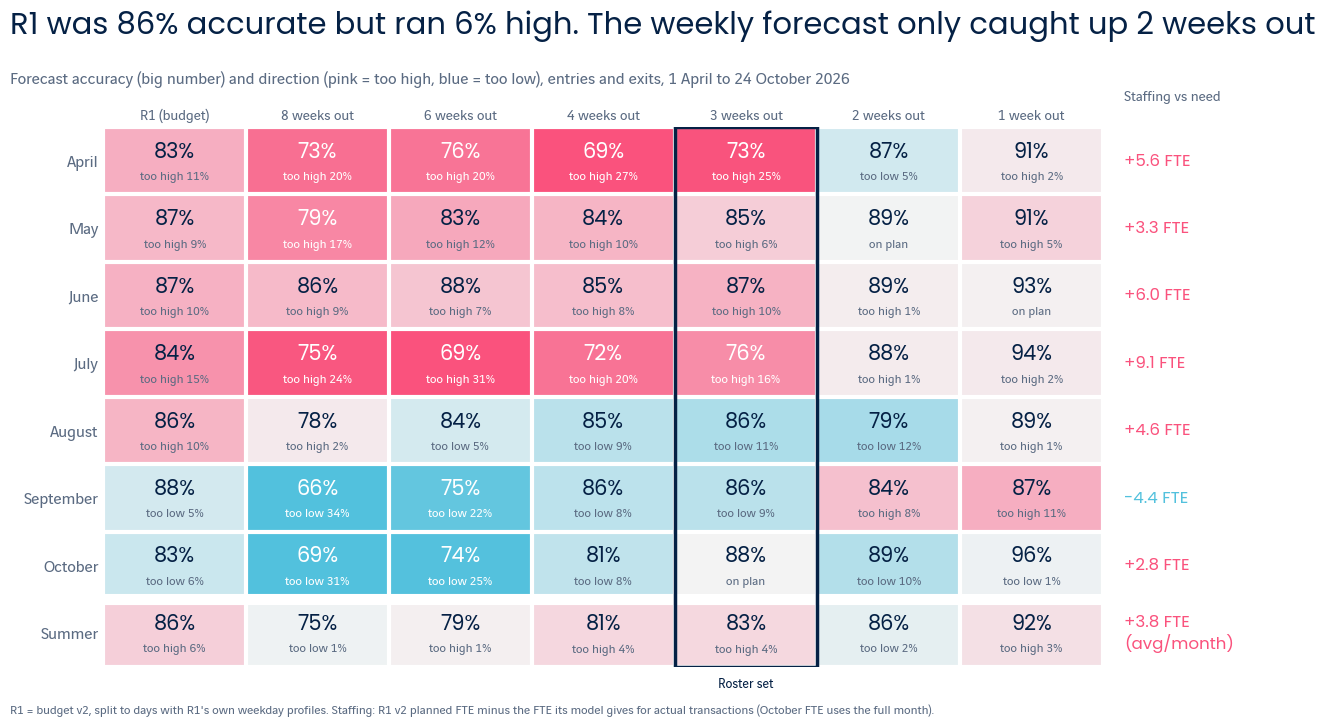

In [8]:
# -----------------------------------------------------------------------------
# Chart 23: R1 and weekly forecasts vs actual, by month, with staffing impact
# -----------------------------------------------------------------------------
cols = ["R1"] + [f"{w}w" for w in R1_WEEKS]
col_labels = ["R1 (budget)"] + [f"{w} week{'s' if w > 1 else ''} out" for w in R1_WEEKS]
rows = R1_MONTHS + ["Summer"]
g_bias, g_acc = v1_bias.loc[rows, cols], v1_acc.loc[rows, cols]
gap = staff["FTE gap"].tolist() + [staff["FTE gap"].mean()]

over_under = LinearSegmentedColormap.from_list("over_under", [LIGHT_BLUE, "#F4F4F4", PINK])
lim = 0.25
fig, ax = plt.subplots(figsize=(13.33, 7.6))
fig.subplots_adjust(top=0.80, bottom=0.09, left=0.11, right=0.86)
ax.grid(False)
ax.imshow(g_bias.values.astype(float), cmap=over_under, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_xticks(np.arange(-0.5, len(cols)), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", length=0)
ax.axhline(len(R1_MONTHS) - 0.5, color="white", lw=8)
for i, r in enumerate(rows):
    for j, c in enumerate(cols):
        b, a = g_bias.loc[r, c], g_acc.loc[r, c]
        if pd.isna(b):
            continue
        strong = abs(b) / lim > 0.6
        ax.text(j, i - 0.13, f"{a:.0%}", ha="center", va="center", fontsize=15, fontfamily=HEAD_FONT,
                color="white" if strong else DARK_BLUE)
        word = "on plan" if abs(b) < 0.005 else ("too high" if b > 0 else "too low")
        ax.text(j, i + 0.24, word if word == "on plan" else f"{word} {abs(b):.0%}", ha="center", va="center",
                fontsize=9.5, color="white" if strong else MUTED)
rx = cols.index(f"{R1_ROSTER}w")
ax.add_patch(plt.Rectangle((rx - 0.5, -0.5), 1, len(rows), fill=False, edgecolor=DARK_BLUE, lw=2.5, zorder=5))
ax.set_xticks(range(len(cols)), col_labels, fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks(range(len(rows)), [MONTH_LONG.get(r, r) for r in rows], fontsize=12.5)
for sp in ax.spines.values():
    sp.set_visible(False)
for i, g in enumerate(gap):
    ax.text(len(cols) - 0.35, i, f"{g:+.1f} FTE" if i < len(R1_MONTHS) else f"{g:+.1f} FTE\n(avg/month)",
            ha="left", va="center", fontsize=12, color=PINK if g > 0 else LIGHT_BLUE, fontfamily=HEAD_FONT)
ax.text(len(cols) - 0.35, -0.85, "Staffing vs need", ha="left", va="bottom", fontsize=11, color=MUTED)
ax.text(rx, len(rows) - 0.35, "Roster set", ha="center", va="top", fontsize=10, color=DARK_BLUE)

s_acc, s_bias = v1_acc.loc["Summer"], v1_bias.loc["Summer"]
beat = next((w for w in sorted(R1_WEEKS, reverse=True) if round(s_acc[f"{w}w"] * 100) >= round(s_acc["R1"] * 100)), None)
headline(fig, f"R1 was {s_acc['R1']:.0%} accurate but ran {abs(s_bias['R1']):.0%} high. "
              f"The weekly forecast only caught up {beat} week{'s' if beat != 1 else ''} out",
         "Forecast accuracy (big number) and direction (pink = too high, blue = too low), entries and exits, 1 April to 24 October 2026")
footnote(fig, "R1 = budget v2, split to days with R1's own weekday profiles. Staffing: R1 v2 planned FTE minus the FTE its model gives for actual transactions (October FTE uses the full month).")
plt.show()

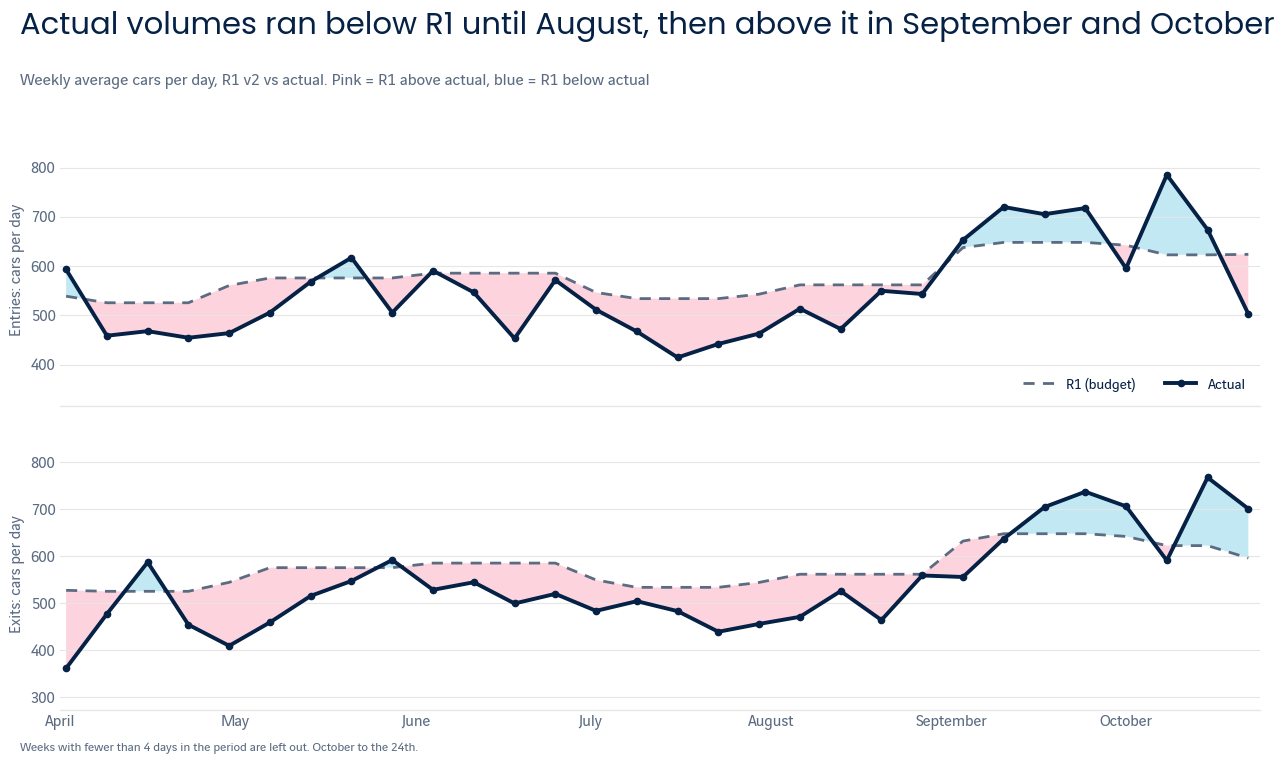

In [9]:
# -----------------------------------------------------------------------------
# Chart 24: actual vs R1 week by week, entries and exits, with what was happening
# -----------------------------------------------------------------------------
ANNOTATIONS = []   # (start, end, label) - left empty: holidays and events showed no clear link to the error.
                   # e.g. ("2026-06-18", "2026-06-21", "Highland Show") to add one back

r1_wk = r1.join(actuals)
r1_wk["week"] = r1_wk.index - pd.to_timedelta(r1_wk.index.weekday, unit="D")
r1_wkly = r1_wk.groupby("week").agg(days=("act_entries", "size"),
                                    **{c: (c, "sum") for c in ["r1_entries", "r1_exits", "act_entries", "act_exits"]})
r1_wkly = r1_wkly[r1_wkly["days"] >= 4]
for c in ["r1_entries", "r1_exits", "act_entries", "act_exits"]:
    r1_wkly[c] = r1_wkly[c] / r1_wkly["days"]          # cars per day, so part-weeks compare fairly

fig, axes = plt.subplots(2, 1, figsize=(13.33, 8.0), sharex=True)
fig.subplots_adjust(top=0.80, bottom=0.08, left=0.07, right=0.97, hspace=0.12)
for ax, flow in zip(axes, ["entries", "exits"]):
    x = r1_wkly.index + pd.Timedelta(days=3)
    plan, act = r1_wkly[f"r1_{flow}"], r1_wkly[f"act_{flow}"]
    ax.fill_between(x, plan, act, where=plan >= act, color=PINK, alpha=0.25, lw=0, interpolate=True)
    ax.fill_between(x, plan, act, where=plan < act, color=LIGHT_BLUE, alpha=0.35, lw=0, interpolate=True)
    ax.plot(x, plan, color=MUTED, lw=2, ls=(0, (4, 3)), label="R1 (budget)")
    ax.plot(x, act, color=DARK_BLUE, lw=2.8, marker="o", ms=4.5, label="Actual")
    ax.set_ylabel(f"{flow.capitalize()}: cars per day")
    ax.set_xlim(R1_START, R1_END)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo * 0.8, hi * 1.08)
axes[0].legend(loc="lower right", ncol=2, fontsize=11)
for k, (a, b, label) in enumerate(ANNOTATIONS):
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    for ax in axes:
        ax.axvspan(a, b, color=GREY, alpha=0.35, lw=0, zorder=0)
    axes[0].annotate(label, xy=(a, 1.0), xycoords=("data", "axes fraction"), xytext=(2, 4 + 14 * (k % 2)),
                     textcoords="offset points", fontsize=9.5, color=MUTED, ha="left", va="bottom")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%B"))

headline(fig, "Actual volumes ran below R1 until August, then above it in September and October",
         "Weekly average cars per day, R1 v2 vs actual. Pink = R1 above actual, blue = R1 below actual")
footnote(fig, "Weeks with fewer than 4 days in the period are left out. October to the 24th.")
plt.show()

## 4. Drivers of inaccuracy: pricing

The weekly forecast had no price input. This section looks at how FastPark's pricing changed against 2025, how booking
timing changed, and whether those changes line up with the forecast error.

**Price index:** each booking's price ÷ the median price for the same length of stay in that summer (×100).
This removes the length-of-stay mix, and puts 2025 and 2026 on the same footing (100 = a typical price that year).

In [10]:
bk = bookings.copy()
bk["createdAt"] = pd.to_datetime(bk["createdAt"])
bk["entryDate"] = pd.to_datetime(bk["entryDate"])
bk["entry_d"] = bk["entryDate"].dt.normalize()
bk["created_d"] = bk["createdAt"].dt.normalize()
bk["lead"] = (bk["entry_d"] - bk["created_d"]).dt.days
bk["year"] = bk["entry_d"].dt.year
bk["month"] = month_key(bk["entry_d"])
bk = bk[bk["month"].isin(MONTHS) & (bk["lead"] >= 0)]

# price per car; standard refundable product only (excludes EV charging), stays of 1-21 days
bk["price"] = bk["productTotal"] / bk["productQuantity"].clip(lower=1)
priced = bk[bk["productName"].str.strip().eq("FastPark Refundable") & bk["duration"].between(1, 21) & (bk["price"] > 0)].copy()
priced["ref"] = priced.groupby(["year", "duration"])["price"].transform("median")
priced["price_idx"] = priced["price"] / priced["ref"] * 100

LEAD_BINS = [-1, 3, 7, 14, 21, 28, 42, 56, 90, 10_000]
LEAD_LABELS = ["0–3", "4–7", "8–14", "15–21", "22–28", "29–42", "43–56", "57–90", "90+"]
priced["lead_band"] = pd.cut(priced["lead"], LEAD_BINS, labels=LEAD_LABELS)

price_shape = (priced.groupby(["year", "month", "lead_band"], observed=True)["price_idx"].median()
               .unstack("lead_band")[LEAD_LABELS[::-1]])
late_premium = priced[priced["lead"] <= 7].groupby(["month", "year"])["price_idx"].median().unstack("year")
display(price_shape.round(0))
display(late_premium.round(0).rename(index=MONTH_LONG))

lead_band     90+  57–90  43–56  29–42  22–28  15–21   8–14    4–7    0–3
year month                                                               
2025 4       90.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0
     5      100.0  100.0  100.0   79.0   79.0   87.0   93.0  100.0  111.0
     6      100.0  100.0   89.0   81.0   89.0  101.0  126.0  132.0  133.0
     7      100.0   89.0   89.0   93.0  100.0  102.0  126.0  144.0  144.0
     8       93.0   93.0  100.0   90.0   89.0   90.0  100.0  111.0  117.0
     9      100.0  106.0   90.0   89.0  100.0  111.0  143.0  156.0  160.0
     10     100.0   90.0   91.0  100.0  110.0  120.0  133.0  144.0  158.0
2026 4       54.0   60.0   61.0   72.0   90.0   93.0  103.0  114.0  117.0
     5       60.0   60.0   77.0   93.0  108.0  111.0  120.0  129.0  133.0
     6       60.0   66.0  100.0  108.0  114.0  120.0  135.0  144.0  156.0
     7       61.0   92.0  107.0  114.0  129.0  149.0  156.0  160.0  157.0
     8       64.0   85.0  120.0  117.0  110.0  100.0  100.0  100.0  100.0
     9       64.0  120.0  103.0  100.0  100.0  100.0  103.0  110.0  116.0
     10      54.0  100.0  100.0  110.0  108.0  109.0  120.0  122.0  122.0

year,2025,2026
month,,
April,100.0,114.0
May,107.0,133.0
June,133.0,150.0
July,144.0,158.0
August,113.0,100.0
September,160.0,111.0
October,153.0,122.0


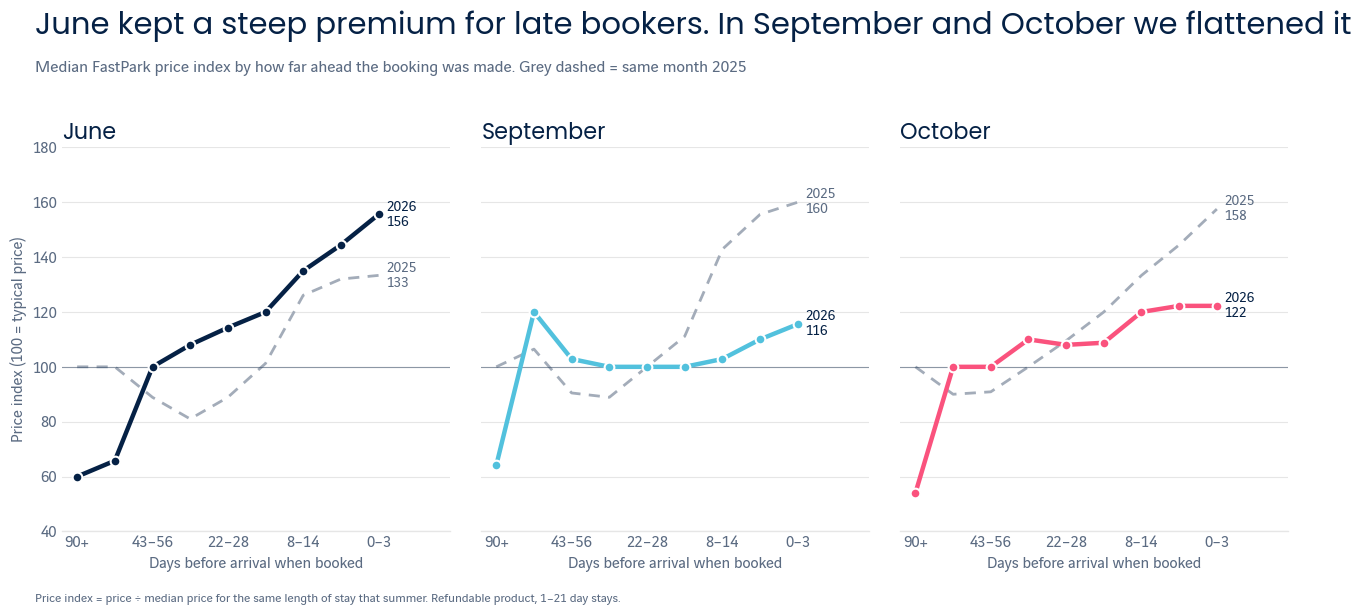

In [11]:
# -----------------------------------------------------------------------------
# Chart 4: the price curve. How much more did late bookers pay? (2026 vs 2025)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=SLIDE, sharey=True)
fig.subplots_adjust(top=0.74, bottom=0.14, left=0.06, right=0.98, wspace=0.08)
xb = np.arange(len(LEAD_LABELS))

for ax, m in zip(axes, FOCUS):
    ly = price_shape.loc[(2025, m)]
    ty = price_shape.loc[(2026, m)]
    ax.plot(xb, ly.values, color=LY_GREY, lw=2, ls=(0, (4, 3)), zorder=2)
    ax.plot(xb, ty.values, color=FOCUS_COLOUR[m], lw=3.2, marker="o", ms=7, mec="white", mew=1.5, zorder=3)
    ax.text(xb[-1] + 0.2, ty.values[-1], f"2026\n{ty.values[-1]:.0f}", color=DARK_BLUE, fontsize=11, va="center")
    ax.text(xb[-1] + 0.2, ly.values[-1], f"2025\n{ly.values[-1]:.0f}", color=MUTED, fontsize=11, va="center")
    ax.axhline(100, color=DARK_BLUE, lw=0.8, alpha=0.4)
    ax.set_title(MONTH_LONG[m], fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
    ax.set_xticks(xb[::2], LEAD_LABELS[::-1][::2])
    ax.set_xlim(-0.4, len(xb) + 0.9)
    ax.set_xlabel("Days before arrival when booked")
axes[0].set_ylabel("Price index (100 = typical price)")
axes[0].set_ylim(40, max(180, np.nanmax(price_shape.values) + 10))

jun, sep = late_premium.loc[6, 2026], late_premium.loc[9, 2026]
headline(fig, "June kept a steep premium for late bookers. In September and October we flattened it",
         "Median FastPark price index by how far ahead the booking was made. Grey dashed = same month 2025")
footnote(fig, "Price index = price ÷ median price for the same length of stay that summer. Refundable product, 1–21 day stays.")
plt.show()

In [12]:
# -----------------------------------------------------------------------------
# Booking timing: share of final demand already booked N days before arrival (what the model relies on)
# -----------------------------------------------------------------------------
DAYS = np.arange(90, -1, -1)
def booked_by(df):
    leads = np.sort(df["lead"].values)
    return pd.Series([(leads >= d).mean() for d in DAYS], index=DAYS)

curves = {(y, m): booked_by(g) for (y, m), g in bk.groupby(["year", "month"])}
timing = pd.DataFrame({
    m: {f"{w}w": curves[(2026, m)][7 * w] - curves[(2025, m)][7 * w] for w in [8, 6, 3, 1]}
    for m in MONTHS
}).T.rename(index=MONTH_LONG)
print("Change in share of final bookings already made, 2026 vs 2025 (percentage points):")
display((timing * 100).round(1))

Change in share of final bookings already made, 2026 vs 2025 (percentage points):


,8w,6w,3w,1w
April,13.7,17.2,17.7,12.8
May,16.1,16.8,9.3,2.2
June,12.5,8.7,-0.6,-3.2
July,9.9,8.5,0.9,-5.6
August,8.5,4.6,-6.1,-6.0
September,-0.7,-4.7,-9.5,-3.8
October,-0.4,-3.7,-8.0,-5.3


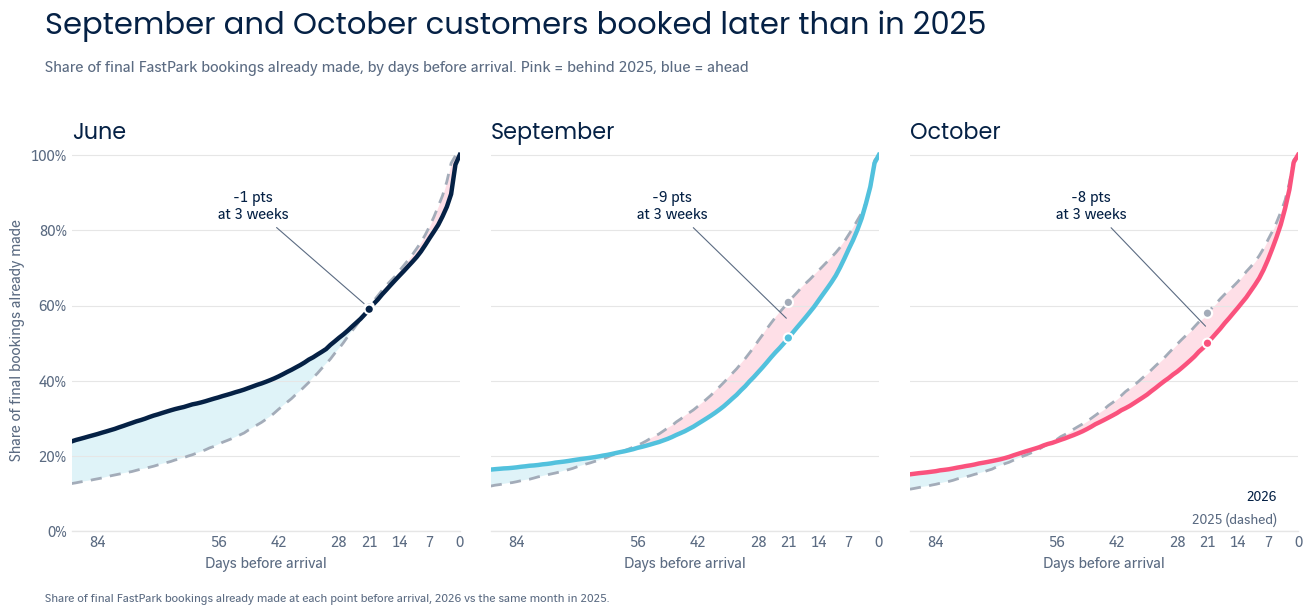

In [13]:
# -----------------------------------------------------------------------------
# Chart 5: booking curve 2026 vs 2025 for the focus months
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=SLIDE, sharey=True)
fig.subplots_adjust(top=0.74, bottom=0.14, left=0.06, right=0.98, wspace=0.08)

for ax, m in zip(axes, FOCUS):
    ly, ty = curves[(2025, m)], curves[(2026, m)]
    ax.fill_between(DAYS, ly.values, ty.values, where=ty.values < ly.values, color=PINK, alpha=0.18, lw=0, interpolate=True)
    ax.fill_between(DAYS, ly.values, ty.values, where=ty.values >= ly.values, color=LIGHT_BLUE, alpha=0.18, lw=0, interpolate=True)
    ax.plot(DAYS, ly.values, color=LY_GREY, lw=2, ls=(0, (4, 3)))
    ax.plot(DAYS, ty.values, color=FOCUS_COLOUR[m], lw=3.2)
    gap = ty[21] - ly[21]
    ax.scatter([21, 21], [ly[21], ty[21]], s=45, color=[LY_GREY, FOCUS_COLOUR[m]], zorder=4, edgecolor="white", linewidth=1.5)
    ax.annotate(f"{gap * 100:+.0f} pts\nat 3 weeks", xy=(21, (ly[21] + ty[21]) / 2), xytext=(48, 0.83),
                fontsize=12, color=DARK_BLUE, ha="center",
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.set_title(MONTH_LONG[m], fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
    ax.set_xlim(90, 0)
    ax.set_xticks([84, 56, 42, 28, 21, 14, 7, 0])
    ax.set_xlabel("Days before arrival")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylim(0, 1.02)
axes[0].set_ylabel("Share of final bookings already made")
axes[-1].text(5, 0.08, "2026", color=DARK_BLUE, fontsize=11, ha="right")
axes[-1].text(5, 0.02, "2025 (dashed)", color=MUTED, fontsize=11, ha="right")

headline(fig, "September and October customers booked later than in 2025",
         "Share of final FastPark bookings already made, by days before arrival. Pink = behind 2025, blue = ahead")
footnote(fig, "Share of final FastPark bookings already made at each point before arrival, 2026 vs the same month in 2025.")
plt.show()

### Does late-booking pricing line up with forecast error?

For each arrival week we take the **late-booking price** (median price index of bookings made 0–7 days before arrival)
and compare it with the **same week in 2025**, the pattern the model learned from. We then line that up with how far
the forecast was out for that week.

We use **forecast error with its direction** (over or under), not accuracy. Accuracy treats a 20% over-forecast and a
20% under-forecast the same, so it hides the pricing effect, which pushes the forecast one way or the other.

In [14]:
priced["week"] = priced["entry_d"].dt.isocalendar().week.astype(int)
late_wk = priced[priced["lead"] <= 7].groupby(["week", "year"])["price_idx"].median().unstack("year")
late_wk["late_price_change"] = late_wk[2026] - late_wk[2025]

fa["week"] = fa["Date"].dt.isocalendar().week.astype(int)
wk = (fa.groupby(["week", "weeks_out"])
        .agg(days=("Date", "nunique"), week_start=("Date", "min"),
             fc=("fc_entries", "sum"), act=("act_entries", "sum")))
wk["bias"] = wk["fc"] / wk["act"] - 1
wk = (wk[wk["days"] >= 4].reset_index()                       # drop part-weeks at the window edges
        .merge(late_wk[["late_price_change"]].reset_index(), on="week"))
wk["month"] = month_key(wk["week_start"])

link_by_horizon = (wk.groupby("weeks_out")
                     .apply(lambda d: d["late_price_change"].corr(d["bias"]), include_groups=False)
                     .loc[WEEKS_OUT])
print(f"{wk['week'].nunique()} arrival weeks")
display(link_by_horizon.round(2).rename("r").to_frame().T)

30 arrival weeks


weeks_out,8,7,6,5,4,3,2,1
r,0.72,0.77,0.75,0.72,0.68,0.67,0.19,0.12


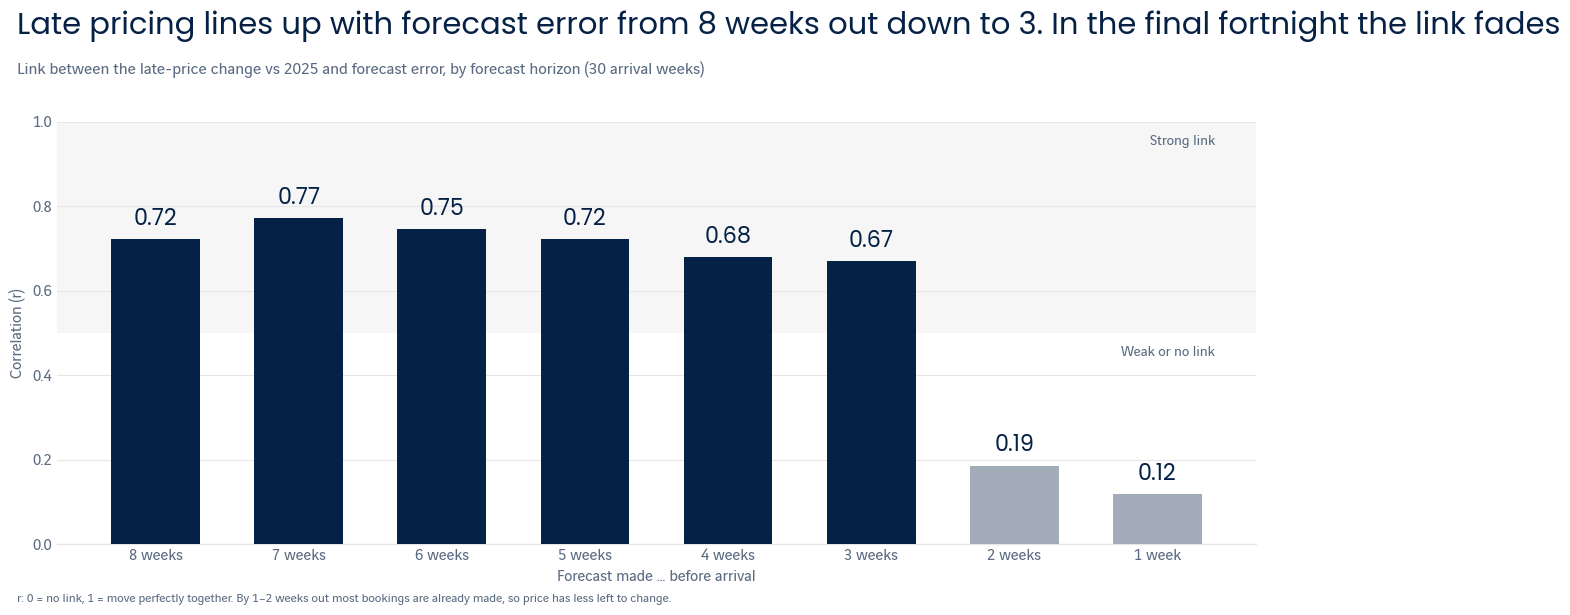

In [15]:
# -----------------------------------------------------------------------------
# Chart 7: how strong is the link at each forecast horizon?
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.07, right=0.97)

xs = np.arange(len(WEEKS_OUT))
vals = link_by_horizon.values
colours = [DARK_BLUE if v >= 0.5 else LY_GREY for v in vals]
ax.bar(xs, vals, width=0.62, color=colours, zorder=3)
for xi, v in zip(xs, vals):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE)

ax.axhspan(0.5, 1.0, color=GREY, alpha=0.35, lw=0, zorder=0)
ax.text(len(xs) - 0.6, 0.97, "Strong link", ha="right", va="top", color=MUTED, fontsize=11)
ax.text(len(xs) - 0.6, 0.47, "Weak or no link", ha="right", va="top", color=MUTED, fontsize=11)
ax.set_xticks(xs, [f"{w} weeks" if w > 1 else "1 week" for w in WEEKS_OUT])
ax.set_xlabel("Forecast made … before arrival")
ax.set_ylabel("Correlation (r)")
ax.set_ylim(0, 1)

strong = [w for w, v in zip(WEEKS_OUT, vals) if v >= 0.5]
headline(fig, f"Late pricing lines up with forecast error from {max(strong)} weeks out down to {min(strong)}. "
              "In the final fortnight the link fades",
         f"Link between the late-price change vs 2025 and forecast error, by forecast horizon ({wk['week'].nunique()} arrival weeks)")
footnote(fig, "r: 0 = no link, 1 = move perfectly together. By 1–2 weeks out most bookings are already made, so price has less left to change.")
plt.show()

## 5. June vs September vs October

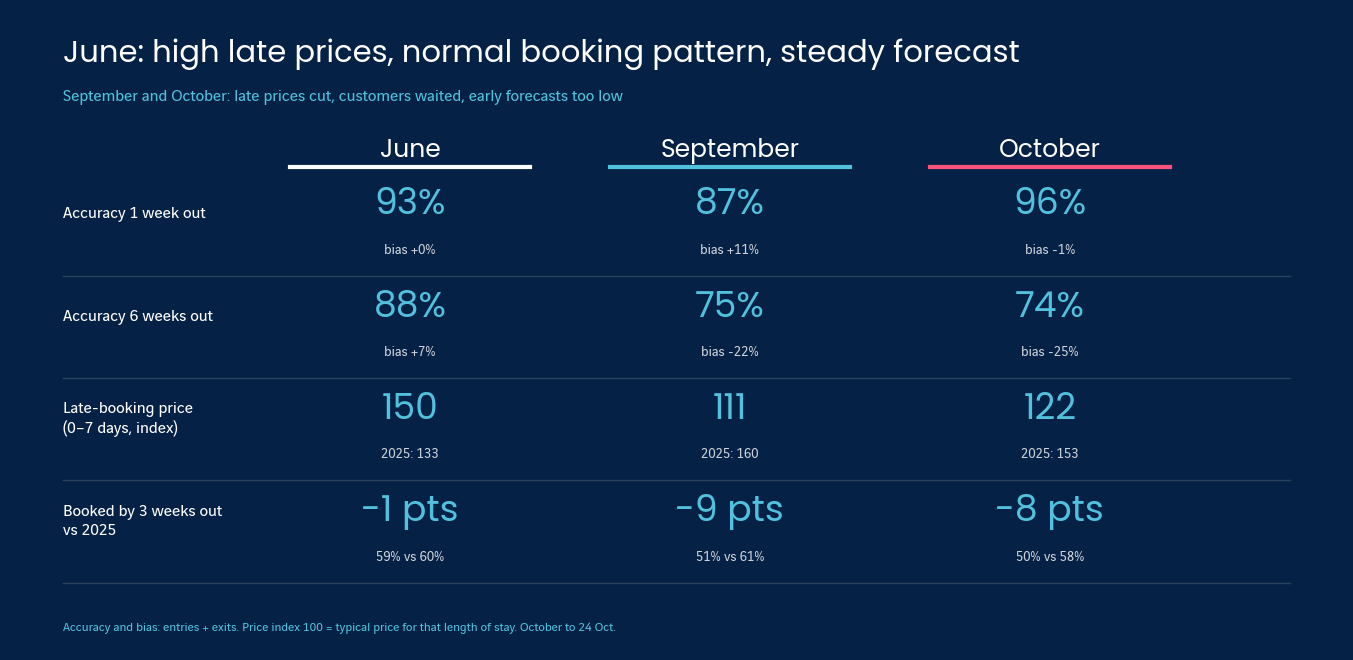

In [16]:
def m_score(m, w, col="accuracy"):
    return by_month_week.loc[(m, w), col]

score_rows = [
    ("Accuracy 1 week out", lambda m: f"{m_score(m, 1):.0%}"),
    ("Accuracy 6 weeks out", lambda m: f"{m_score(m, 6):.0%}"),
    ("Late-booking price\n(0–7 days, index)", lambda m: f"{late_premium.loc[m, 2026]:.0f}"),
    ("Booked by 3 weeks out\nvs 2025", lambda m: f"{timing.loc[MONTH_LONG[m], '3w'] * 100:+.0f} pts"),
]
score_sub = [
    lambda m: f"bias {m_score(m, 1, 'bias'):+.0%}",
    lambda m: f"bias {m_score(m, 6, 'bias'):+.0%}",
    lambda m: f"2025: {late_premium.loc[m, 2025]:.0f}",
    lambda m: f"{curves[(2026, m)][21]:.0%} vs {curves[(2025, m)][21]:.0%}",
]

fig = plt.figure(figsize=SLIDE, facecolor=DARK_BLUE)
fig.add_axes([0, 0, 1, 1]).axis("off")   # gives the figure an axes so it displays inline
headline(fig, "June: high late prices, normal booking pattern, steady forecast",
         "September and October: late prices cut, customers waited, early forecasts too low", dark=True)

col_x = [0.30, 0.54, 0.78]
row_y = [0.66, 0.50, 0.34, 0.18]
for cx, m in zip(col_x, FOCUS):
    fig.text(cx, 0.77, MONTH_LONG[m], fontsize=18, fontfamily=HEAD_FONT, color="white", ha="center")
    fig.add_artist(plt.Line2D([cx - 0.09, cx + 0.09], [0.755, 0.755], color=FOCUS_COLOUR[m] if m != 6 else "white",
                              lw=3, transform=fig.transFigure))
for (label, fn), sub, ry in zip(score_rows, score_sub, row_y):
    fig.text(0.04, ry + 0.02, label, fontsize=12.5, color="white", va="center", linespacing=1.3)
    for cx, m in zip(col_x, FOCUS):
        fig.text(cx, ry + 0.035, fn(m), fontsize=26, fontfamily=HEAD_FONT, color=LIGHT_BLUE, ha="center", va="center")
        fig.text(cx, ry - 0.035, sub(m), fontsize=10.5, color="white", alpha=0.8, ha="center", va="center")
    fig.add_artist(plt.Line2D([0.04, 0.96], [ry - 0.075, ry - 0.075], color="white", alpha=0.15, lw=1,
                              transform=fig.transFigure))
footnote(fig, "Accuracy and bias: entries + exits. Price index 100 = typical price for that length of stay. October to 24 Oct.", dark=True)
plt.show()

FastPark changes in 2026

uplift of 7.6% to entries from 11th to 15th of April (323 spaces in GAP)
uplift of 7.6% to exits for period of 16th - 20th of April (323 spacs in GAP)

On 2nd of March a 10% uplift to entries and exits was applied for all days in March
On 23rd of March, adjustment to uplift now 15% uplift to entries and exits on Monday to Wednesday and 7% uplift to Thurs to Sunday for March and April and 10% uplift across all days of Easter Holidays (3rd to 20th of April)
On 27th of March adjustment to previous uplift, Easter is now 0% uplift but rest of april remain with 15% M-W and 7% T-Sun
On 30th of March adjustment to the uplift to be 6% on MTW and 4% on TFSS, with 0% uplift for Easter (3rd to 30th of April)

On the 10th of April the Easter period was adjusted:
uplift of 7.6% to entries from 11th to 13th of April (323 spaces in GAP)
uplift of 7.6% to exits for period of 16th - 20th of April (323 spacs in GAP)
no uplift for april beyong the 20th of April

On 13th of April of the uplift was adjusted to be: Easter 11th-13th, Entry 17%, Easter 16th of 20th Exit 7.6%, April 21st to 30th 6% MTW 4% T-Sun, May 12.6% for both Entry and Exit

On 20th of April the uplift was adjusted to April 21st to 30th 6% MTW 4% T-Sun, May 8.7% for both Entry and Exit

On 27th of April the uplift was adjusted to April 21st to 30th 6% MTW 4% T-Sun, May 9.9% for both Entry and Exit

On the 4th of May: All uplifts were removed

11th of May: 14% uplift applied to last week of May and all of June

Due to carpark closures on the 12th of May:
the next 2 weeks had 18% uplift and the remaning days of may and june had a 14% uplift

On the 18th of May:
Uplift adjusted to 10% for etnries on M-W and 10% on extis Tues-Thurs for May and then 5% overall for June

On the 25th of May:
Uplift adjusted to 10% for etnries on M-W and 10% on extis and June uplift removed

5th of August: 53% uplift for entries and exits in September added
10th of August: adjusted to 44% uplift for entries and exits in september

August 11th:
current forecast provides uplifts to booking numbers for first two weeks of forecast and then uses penetration rates for forecast after two weeks. These are a statitc uplift per day for entries and exits:
Entries = [5, 10, 15, 20, 25, 30, 35, 38, 41, 44, 47, 50, 53, 56]
Exits = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
On this day they were adjusted for the rest of August to be
Entries = [5, 10.4, 18.84, 26.9, 34.48, 42.16, 50.10, 57.2, 63.45, 69.24, 75.02,80.13, 84.69, 89.25]
Exits = [1, 11.05, 18.79, 25.27, 31.72, 38, 43.2, 48.83, 53.80, 57.80, 61.1, 65.32, 69.04, 73.63]
The old logic remains for September with 44% uplift in place

August 17th: September uplift adjsuted to 38%

August 24th: September uplift adjusted to 28%

31st of August: Forecasting logic returned to old booking uplift and september uplift adjusted to 21%







## 6. Manual uplifts and events: did they help?

**How the summer 2026 forecast worked:**

- **Up to 14 days ahead:** bookings already made × the standard booking uplift by days ahead
  (entries 5%, 10%, 15% … 56%; exits 1%, 2% … 14%; a revised list was used for August arrivals from 11 August).
- **Beyond 14 days:** passenger forecast × penetration rates.
- **Manual uplifts** (the schedule below) then go on top of that forecast, for the dates and weekdays they cover,
  from the run date they were set.

**What this section works out**, for every arrival date and forecast horizon:

- **Standard forecast** = issued forecast ÷ (1 + manual uplift in force on that run date), i.e. what it would have
  been without the manual uplift. The standard booking uplift (including the revised August list) stays in.
- **Applied** = issued ÷ standard − 1, the manual uplift we made.
- **Needed** = actual ÷ standard − 1, the change that would have made the forecast exactly right.

In [17]:
# -----------------------------------------------------------------------------
# Manual uplift schedule, 2026
# Each entry is the rule set in force for forecasts RUN on or after that date (until the next entry).
# Within a rule set, each rule = (first target date, last target date, flows, weekdays, uplift %).
# Weekdays: 0 = Mon ... 6 = Sun. Later rules in the same list override earlier ones for the same day.
# -----------------------------------------------------------------------------
from datetime import date as _d

BOTH, ENT, EXT = ("entries", "exits"), ("entries",), ("exits",)
ALL_DAYS, MTW, THU_SUN, TUE_THU = range(7), (0, 1, 2), (3, 4, 5, 6), (1, 2, 3)

UPLIFT_SCHEDULE = [
    ("2026-03-02", "10% on all of March", [
        ("2026-03-01", "2026-03-31", BOTH, ALL_DAYS, 10)]),
    ("2026-03-23", "Mar-Apr 15% Mon-Wed / 7% Thu-Sun, Easter 10%", [
        ("2026-03-01", "2026-04-30", BOTH, MTW, 15),
        ("2026-03-01", "2026-04-30", BOTH, THU_SUN, 7),
        ("2026-04-03", "2026-04-20", BOTH, ALL_DAYS, 10)]),
    ("2026-03-27", "Easter 0%, rest 15% / 7%", [
        ("2026-03-01", "2026-04-30", BOTH, MTW, 15),
        ("2026-03-01", "2026-04-30", BOTH, THU_SUN, 7),
        ("2026-04-03", "2026-04-20", BOTH, ALL_DAYS, 0)]),
    ("2026-03-30", "6% Mon-Wed / 4% Thu-Sun, 0% from 3 Apr", [
        ("2026-03-01", "2026-04-30", BOTH, MTW, 6),
        ("2026-03-01", "2026-04-30", BOTH, THU_SUN, 4),
        ("2026-04-03", "2026-04-30", BOTH, ALL_DAYS, 0)]),
    ("2026-04-10", "Easter GAP: entries 11-13 Apr, exits 16-20 Apr 7.6%", [
        ("2026-04-11", "2026-04-13", ENT, ALL_DAYS, 7.6),
        ("2026-04-16", "2026-04-20", EXT, ALL_DAYS, 7.6)]),
    ("2026-04-13", "Easter + late Apr 6%/4% + May 12.6%", [
        ("2026-04-11", "2026-04-13", ENT, ALL_DAYS, 17),
        ("2026-04-16", "2026-04-20", EXT, ALL_DAYS, 7.6),
        ("2026-04-21", "2026-04-30", BOTH, MTW, 6),
        ("2026-04-21", "2026-04-30", BOTH, THU_SUN, 4),
        ("2026-05-01", "2026-05-31", BOTH, ALL_DAYS, 12.6)]),
    ("2026-04-20", "Late Apr 6%/4% + May 8.7%", [
        ("2026-04-21", "2026-04-30", BOTH, MTW, 6),
        ("2026-04-21", "2026-04-30", BOTH, THU_SUN, 4),
        ("2026-05-01", "2026-05-31", BOTH, ALL_DAYS, 8.7)]),
    ("2026-04-27", "Late Apr 6%/4% + May 9.9%", [
        ("2026-04-21", "2026-04-30", BOTH, MTW, 6),
        ("2026-04-21", "2026-04-30", BOTH, THU_SUN, 4),
        ("2026-05-01", "2026-05-31", BOTH, ALL_DAYS, 9.9)]),
    ("2026-05-04", "All uplifts removed", []),
    ("2026-05-11", "14% last week of May + June", [
        ("2026-05-25", "2026-06-30", BOTH, ALL_DAYS, 14)]),
    ("2026-05-12", "Car park closures: 18% next 2 weeks, then 14%", [
        ("2026-05-27", "2026-06-30", BOTH, ALL_DAYS, 14),
        ("2026-05-13", "2026-05-26", BOTH, ALL_DAYS, 18)]),
    ("2026-05-18", "May 10% (entries Mon-Wed, exits Tue-Thu), June 5%", [
        ("2026-05-01", "2026-05-31", ENT, MTW, 10),
        ("2026-05-01", "2026-05-31", EXT, TUE_THU, 10),
        ("2026-06-01", "2026-06-30", BOTH, ALL_DAYS, 5)]),
    ("2026-05-25", "May 10% (entries Mon-Wed, exits Tue-Thu), June removed", [
        ("2026-05-01", "2026-05-31", ENT, MTW, 10),
        ("2026-05-01", "2026-05-31", EXT, TUE_THU, 10)]),
    ("2026-06-01", "No uplifts (May rules have expired)", []),
    ("2026-08-05", "September 53%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 53)]),
    ("2026-08-10", "September 44%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 44)]),
    ("2026-08-17", "September 38%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 38)]),
    ("2026-08-24", "September 28%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 28)]),
    ("2026-08-31", "September 21%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 21)]),
    ("2026-09-07", "September 13%", [("2026-09-01", "2026-09-30", BOTH, ALL_DAYS, 13)]),
    ("2026-09-14", "September uplift removed (definitely off by 21 Sep)", []),
]

EVENTS = [
    ("2026-04-03", "2026-04-20", "Easter holidays"),
    ("2026-05-12", "2026-05-26", "Car park closures"),
]

_schedule = [(pd.Timestamp(d), label, [(pd.Timestamp(a), pd.Timestamp(b), fl, set(wd), pct)
                                       for a, b, fl, wd, pct in rules])
             for d, label, rules in UPLIFT_SCHEDULE]


def overlay_pct(run, target, flow):
    """Manual % uplift on the forecast for `target`, as set in the rules in force on `run` date."""
    current = [rules for start, _, rules in _schedule if start <= run]
    if not current:
        return 0.0
    pct = 0.0
    for a, b, flows, weekdays, p in current[-1]:
        if flow in flows and a <= target <= b and target.weekday() in weekdays:
            pct = p
    return pct


In [18]:
# -----------------------------------------------------------------------------
# Standard (no manual change) forecast for every arrival date x horizon
# -----------------------------------------------------------------------------
def standard_forecast(run, target, issued, flow):
    """Issued forecast with the manual uplift (from the schedule) taken back off."""
    return issued / (1 + overlay_pct(run, target, flow) / 100)

fu = fa.copy()
for flow in ["entries", "exits"]:
    fu[f"std_{flow}"] = [standard_forecast(r, t, f, flow)
                         for r, t, f in zip(fu["run"], fu["Date"], fu[f"fc_{flow}"])]
fu["issued"] = fu["fc_entries"] + fu["fc_exits"]
fu["standard"] = fu["std_entries"] + fu["std_exits"]
fu["actual"] = fu["act_entries"] + fu["act_exits"]
fu["abs_err_issued"] = (fu["fc_entries"] - fu["act_entries"]).abs() + (fu["fc_exits"] - fu["act_exits"]).abs()
fu["abs_err_standard"] = (fu["std_entries"] - fu["act_entries"]).abs() + (fu["std_exits"] - fu["act_exits"]).abs()

def uplift_score(df, by):
    g = df.groupby(by)[["issued", "standard", "actual", "abs_err_issued", "abs_err_standard"]].sum()
    out = pd.DataFrame(index=g.index)
    out["applied"] = g["issued"] / g["standard"] - 1
    out["needed"] = g["actual"] / g["standard"] - 1
    out["acc_issued"] = 1 - g["abs_err_issued"] / g["actual"]
    out["acc_standard"] = 1 - g["abs_err_standard"] / g["actual"]
    out["acc_change_pts"] = (out["acc_issued"] - out["acc_standard"]) * 100
    return out

uplift_month = uplift_score(fu, ["month", "weeks_out"])
uplift_horizon = uplift_score(fu, "weeks_out").loc[WEEKS_OUT]
fu["week_start"] = fu["Date"] - pd.to_timedelta(fu["Date"].dt.weekday, unit="D")
uplift_week = uplift_score(fu, ["week_start", "weeks_out"]).reset_index()

print("Whole summer, by horizon (%, accuracy change in points):")
display((uplift_horizon * [100, 100, 100, 100, 1]).round(1))

Whole summer, by horizon (%, accuracy change in points):


,applied,needed,acc_issued,acc_standard,acc_change_pts
weeks_out,,,,,
8,0.2,0.8,74.8,74.6,0.1
7,1.5,1.9,76.1,75.3,0.8
6,3.6,2.5,78.7,76.9,1.7
5,5.4,2.7,80.8,78.1,2.7
4,6.7,2.0,81.2,78.6,2.6
3,5.8,1.2,83.0,80.6,2.4
2,5.4,7.8,86.3,86.6,-0.2
1,3.7,0.6,91.5,93.0,-1.6


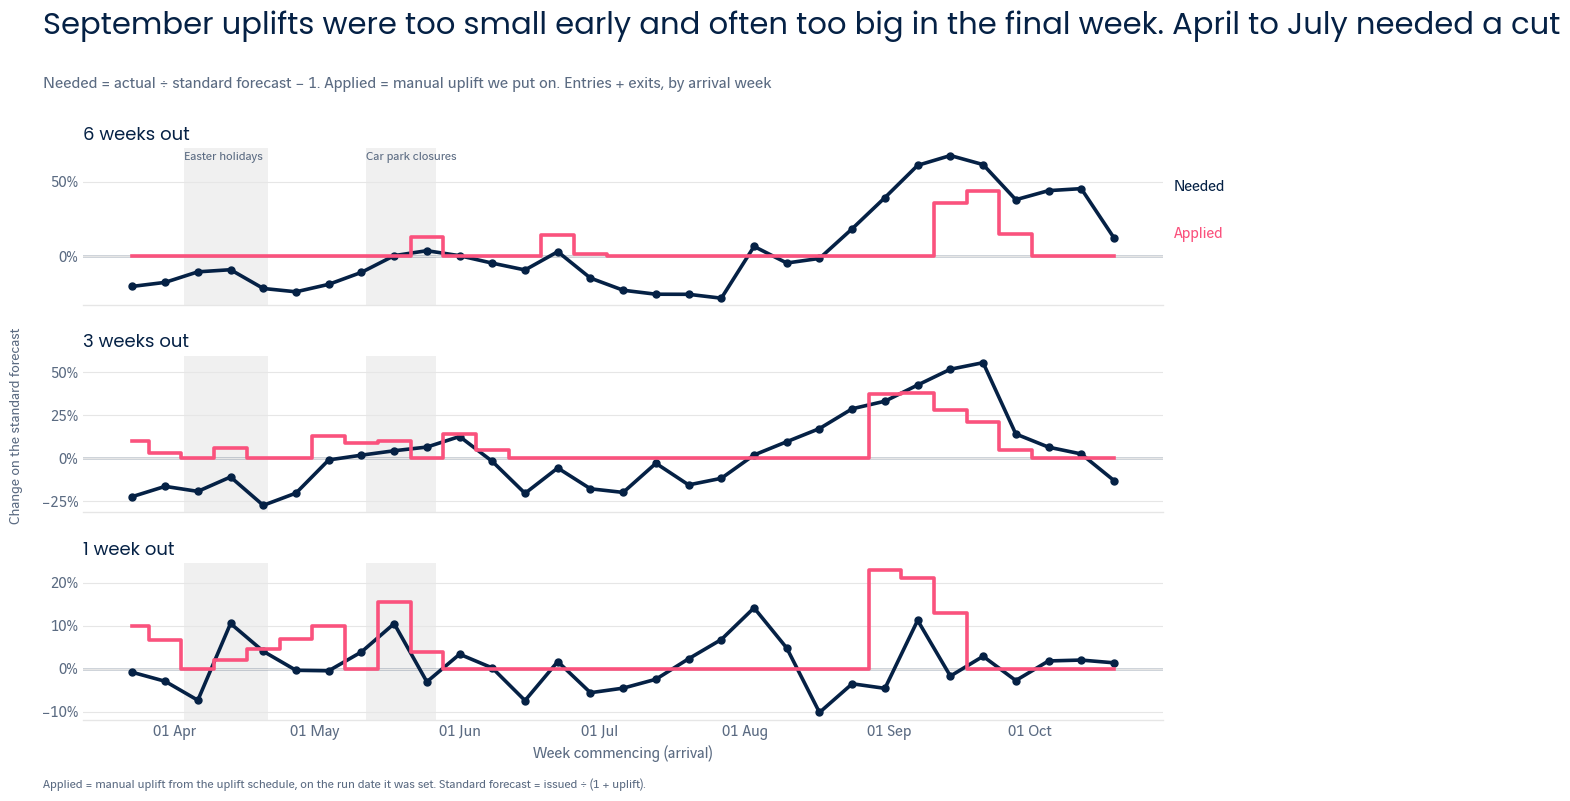

In [19]:
# -----------------------------------------------------------------------------
# Chart 9: what we added vs what was needed, week by week
# -----------------------------------------------------------------------------
PANELS = [6, 3, 1]
fig, axes = plt.subplots(len(PANELS), 1, figsize=(13.33, 8.4), sharex=True)
fig.subplots_adjust(top=0.79, bottom=0.11, left=0.07, right=0.88, hspace=0.32)

for ax, w in zip(axes, PANELS):
    d = uplift_week[uplift_week["weeks_out"] == w].sort_values("week_start")
    for a, b, label in EVENTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=GREY, alpha=0.6, lw=0, zorder=0)
    ax.axhline(0, color=DARK_BLUE, lw=1, zorder=1)
    ax.plot(d["week_start"], d["needed"], color=DARK_BLUE, lw=2.6, marker="o", ms=5, zorder=3)
    ax.step(d["week_start"], d["applied"], where="mid", color=PINK, lw=2.6, zorder=4)
    ax.yaxis.set_major_formatter(pct)
    ax.set_title(f"{w} week{'s' if w > 1 else ''} out", fontsize=13, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
    if w == PANELS[0]:
        ax.text(1.01, 0.75, "Needed", transform=ax.transAxes, color=DARK_BLUE, fontsize=12, va="center")
        ax.text(1.01, 0.45, "Applied", transform=ax.transAxes, color=PINK, fontsize=12, va="center")
        for a, b, label in EVENTS:
            ax.text(pd.Timestamp(a), 0.98, label, transform=ax.get_xaxis_transform(), fontsize=9.5,
                    color=MUTED, va="top", ha="left")
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
axes[-1].set_xlabel("Week commencing (arrival)")
fig.text(0.015, 0.46, "Change on the standard forecast", rotation=90, color=MUTED, va="center", fontsize=11)

headline(fig, "September uplifts were too small early and often too big in the final week. April to July needed a cut",
         "Needed = actual ÷ standard forecast − 1. Applied = manual uplift we put on. Entries + exits, by arrival week")
footnote(fig, "Applied = manual uplift from the uplift schedule, on the run date it was set. Standard forecast = issued ÷ (1 + uplift).")
plt.show()

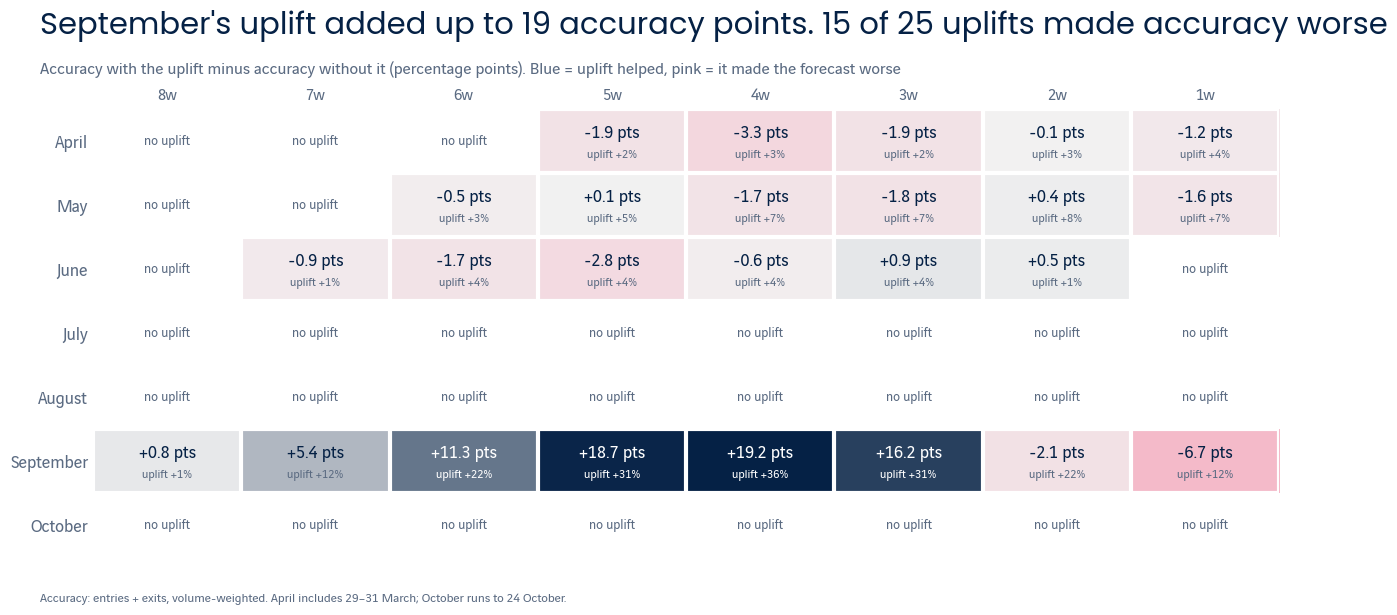

In [20]:
# -----------------------------------------------------------------------------
# Chart 10: did the uplifts improve accuracy?  (accuracy points gained or lost, month x horizon)
# -----------------------------------------------------------------------------
chg = uplift_month["acc_change_pts"].unstack("weeks_out").loc[MONTHS, WEEKS_OUT]
applied = uplift_month["applied"].unstack("weeks_out").loc[MONTHS, WEEKS_OUT]
touched = applied.abs() >= 0.005                       # an uplift of at least 0.5% was in place

div = LinearSegmentedColormap.from_list("edi_div", [PINK, "#F2F2F2", DARK_BLUE])
lim = max(5, np.nanmax(np.abs(chg.where(touched).values)))
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.80, bottom=0.10, left=0.08, right=0.97)
ax.grid(False)
ax.imshow(chg.where(touched).values, cmap=div, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(np.arange(-0.5, len(WEEKS_OUT)), minor=True)
ax.set_yticks(np.arange(-0.5, len(MONTHS)), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", length=0)
for i, m in enumerate(MONTHS):
    for j, w in enumerate(WEEKS_OUT):
        if not touched.loc[m, w]:
            ax.text(j, i, "no uplift", ha="center", va="center", fontsize=10, color=MUTED)
            continue
        v = chg.loc[m, w]
        strong = abs(v) / lim > 0.55
        ax.text(j, i - 0.12, f"{v:+.1f} pts", ha="center", va="center", fontsize=13,
                color="white" if strong else DARK_BLUE)
        ax.text(j, i + 0.22, f"uplift {applied.loc[m, w]:+.0%}", ha="center", va="center", fontsize=9,
                color="white" if strong else MUTED)
ax.set_xticks(range(len(WEEKS_OUT)), [f"{w}w" for w in WEEKS_OUT])
ax.set_yticks(range(len(MONTHS)), [MONTH_LONG[m] for m in MONTHS], fontsize=13)
ax.xaxis.tick_top()
for s in ax.spines.values():
    s.set_visible(False)

helped = int(((chg > 0) & touched).values.sum())
hurt = int(((chg < 0) & touched).values.sum())
best = chg.where(touched).max().max()
headline(fig, f"September's uplift added up to {best:.0f} accuracy points. {hurt} of {helped + hurt} uplifts made accuracy worse",
         "Accuracy with the uplift minus accuracy without it (percentage points). Blue = uplift helped, pink = it made the forecast worse")
footnote(fig, "Accuracy: entries + exits, volume-weighted. April includes 29–31 March; October runs to 24 October.")
plt.show()

### Did the uplifts push us into over-forecasting?

For every arrival date and horizon where an uplift of at least 0.5% was in place, what did it do?

- **Too low: uplift helped, not enough:** without the uplift the forecast was below actual; the uplift moved it up but it was still below.
- **Too low: uplift overshot:** without the uplift the forecast was below actual; the uplift pushed it above actual.
- **Already too high: uplift added more:** without the uplift the forecast was already above actual; the uplift pushed it further
  above, so the error got bigger.

In [21]:
OUTCOMES = ["Too low: uplift helped, not enough", "Too low: uplift overshot", "Already too high: uplift added more"]
OUTCOME_COLOUR = dict(zip(OUTCOMES, [DARK_BLUE, LIGHT_BLUE, PINK]))

up = fu[(fu["issued"] / fu["standard"] - 1) >= 0.005].copy()
up["outcome"] = np.select(
    [(up["standard"] < up["actual"]) & (up["issued"] <= up["actual"]),
     (up["standard"] < up["actual"]) & (up["issued"] > up["actual"]),
     (up["standard"] >= up["actual"])],
    OUTCOMES, default="Other")
up["horizon"] = np.where(up["weeks_out"] <= 2, "1–2 weeks out", "3–8 weeks out")
up["extra_cars"] = up["issued"] - up["standard"]

uplift_outcome = (up.groupby(["month", "horizon", "outcome"]).size().unstack("outcome", fill_value=0)
                  .reindex(columns=OUTCOMES, fill_value=0))
uplift_outcome_share = uplift_outcome.div(uplift_outcome.sum(axis=1), axis=0)

over_issued = (up["issued"] > up["actual"]).mean()
over_standard = (up["standard"] > up["actual"]).mean()
print(f"Uplifted forecasts above actual: {over_issued:.0%} as issued, vs {over_standard:.0%} had we not uplifted")
display(up.groupby("horizon")["outcome"].value_counts(normalize=True).unstack().reindex(columns=OUTCOMES).round(2))
display(uplift_outcome)

Uplifted forecasts above actual: 64% as issued, vs 26% had we not uplifted


outcome,"Too low: uplift helped, not enough",Too low: uplift overshot,Already too high: uplift added more
horizon,,,
1–2 weeks out,0.27,0.53,0.20
3–8 weeks out,0.42,0.29,0.29


outcome              Too low: uplift helped, not enough  \
month horizon                                             
4     1–2 weeks out                                  12   
      3–8 weeks out                                   0   
5     1–2 weeks out                                   9   
      3–8 weeks out                                  13   
6     1–2 weeks out                                   6   
      3–8 weeks out                                   5   
9     1–2 weeks out                                   6   
      3–8 weeks out                                  80   

outcome              Too low: uplift overshot  \
month horizon                                   
4     1–2 weeks out                        10   
      3–8 weeks out                         0   
5     1–2 weeks out                        26   
      3–8 weeks out                        28   
6     1–2 weeks out                         1   
      3–8 weeks out                        21   
9     1–2 weeks out                        29   
      3–8 weeks out                        19   

outcome              Already too high: uplift added more  
month horizon                                             
4     1–2 weeks out                                    8  
      3–8 weeks out                                   20  
5     1–2 weeks out                                    9  
      3–8 weeks out                                   22  
6     1–2 weeks out                                    0  
      3–8 weeks out                                   27  
9     1–2 weeks out                                    8  
      3–8 weeks out                                    0

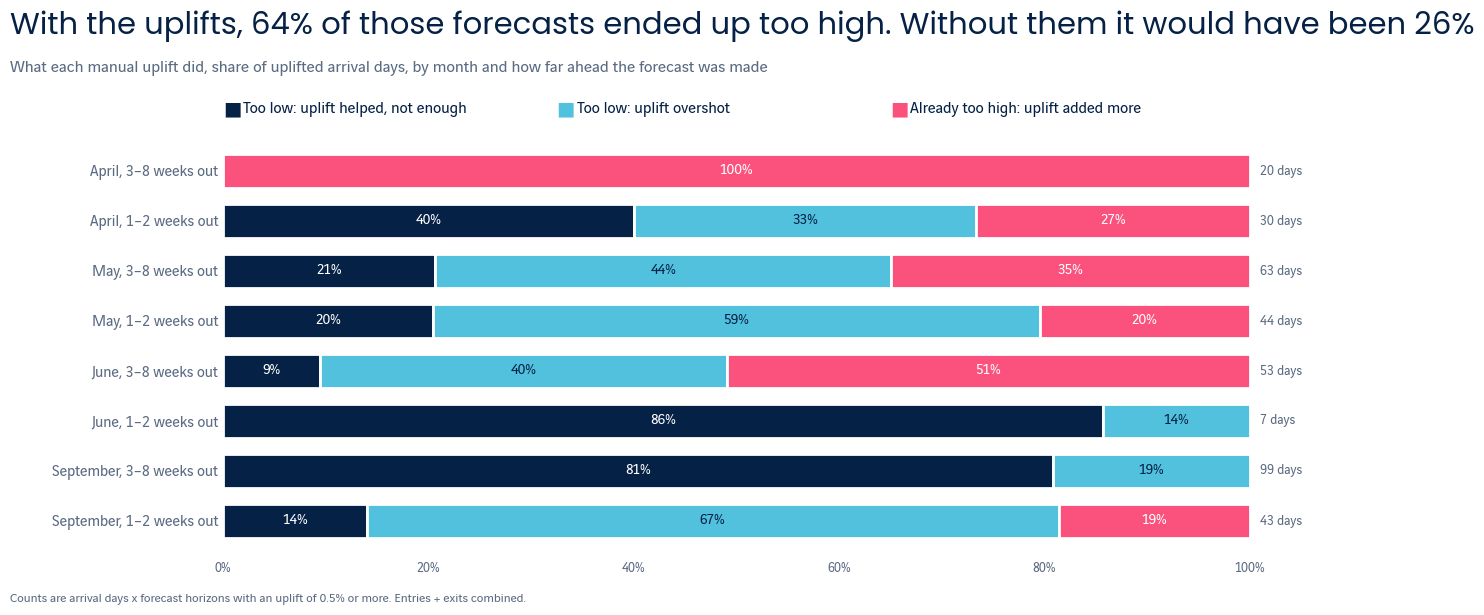

In [22]:
# -----------------------------------------------------------------------------
# Chart 11: what each uplift did, by month and horizon
# -----------------------------------------------------------------------------
rows = [(m, h) for m in MONTHS for h in ["3–8 weeks out", "1–2 weeks out"] if (m, h) in uplift_outcome_share.index]
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.76, bottom=0.10, left=0.20, right=0.97)
ax.grid(False)
y = np.arange(len(rows))[::-1]
for yi, key in zip(y, rows):
    left = 0
    n = uplift_outcome.loc[key].sum()
    for o in OUTCOMES:
        v = uplift_outcome_share.loc[key, o]
        if v <= 0:
            continue
        ax.barh(yi, v, left=left, color=OUTCOME_COLOUR[o], height=0.68, edgecolor="white", linewidth=2)
        if v >= 0.08:
            ax.text(left + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=11,
                    color="white" if o != OUTCOMES[1] else DARK_BLUE)
        left += v
    ax.text(1.01, yi, f"{n} days", va="center", fontsize=10, color=MUTED)
ax.set_yticks(y, [f"{MONTH_LONG[m]}, {h}" for m, h in rows], fontsize=11.5)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(pct)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", labelsize=10)
for k, o in enumerate(OUTCOMES):
    fig.text(0.20 + k * 0.25, 0.80, "■", color=OUTCOME_COLOUR[o], fontsize=14, va="center", fontfamily="DejaVu Sans")
    fig.text(0.215 + k * 0.25, 0.80, o, color=DARK_BLUE, fontsize=12, va="center")

headline(fig, f"With the uplifts, {over_issued:.0%} of those forecasts ended up too high. Without them it would have been {over_standard:.0%}",
         "What each manual uplift did, share of uplifted arrival days, by month and how far ahead the forecast was made")
footnote(fig, "Counts are arrival days x forecast horizons with an uplift of 0.5% or more. Entries + exits combined.")
plt.show()

### R1, the weekly forecast, and what the manual uplifts changed (1 April to 24 October)

For each month: weekly forecast accuracy **with** manual uplifts (as issued), **without** them (schedule backed out), and R1.
The vertical line between the two dots is the difference the uplift made. Under each month: the uplift in place at the
roster point, and the late-booking price index for 2025 and 2026 (median price index of bookings made 0–7 days before
arrival; 100 = typical price for that stay length that year).

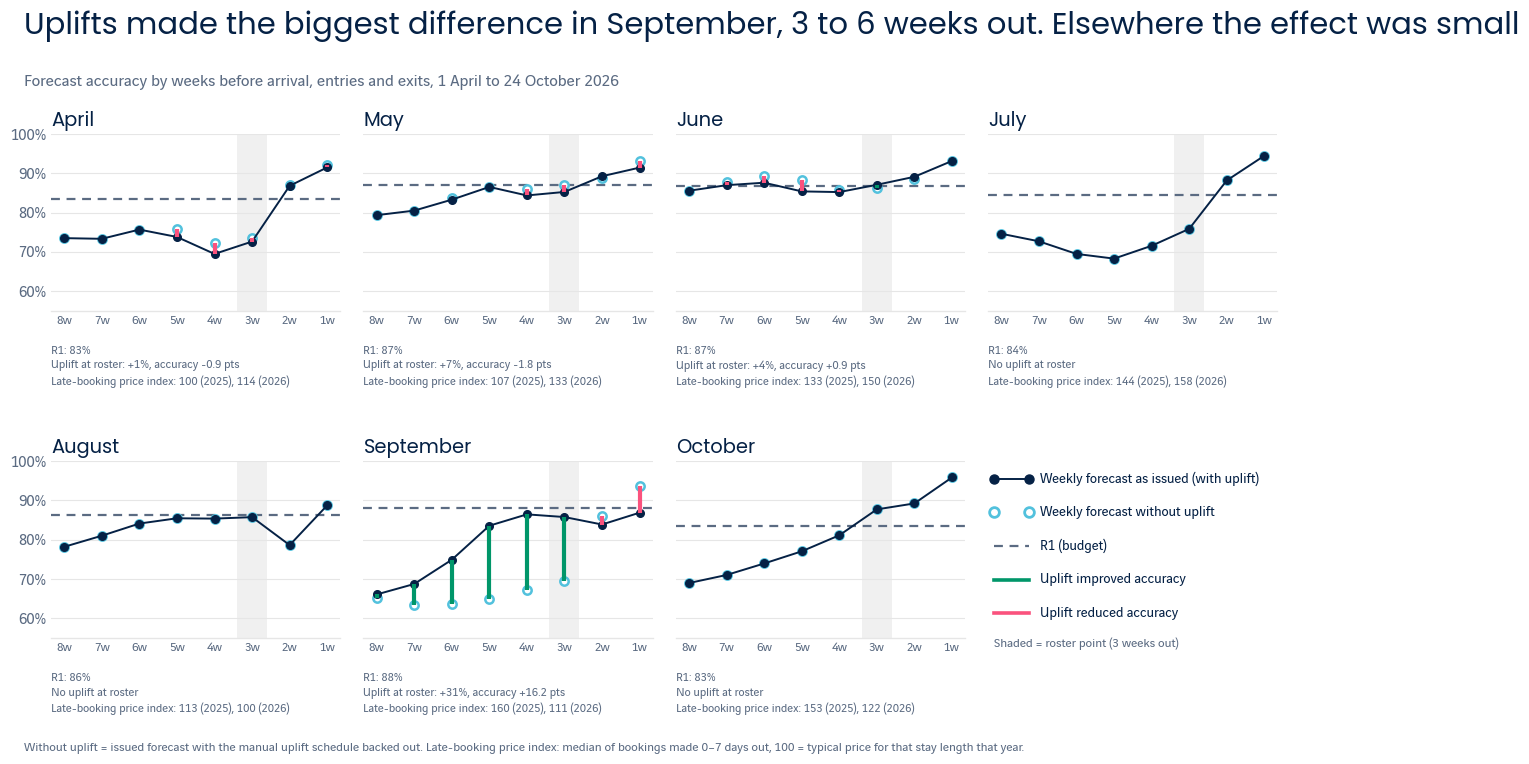

In [23]:
# -----------------------------------------------------------------------------
# Chart 25: accuracy with uplift, without uplift, and R1, by month and weeks out
# -----------------------------------------------------------------------------
H = list(range(8, 0, -1))
fu_r1 = fu[fu["Date"].between(R1_START, R1_END)].assign(m=lambda d: d["Date"].dt.month, all=1)

def acc_by_horizon(fc_e, fc_x):
    out = {}
    for w in H:
        d = fu_r1[fu_r1["weeks_out"] == w]
        out[w] = pd.concat([score_fc(d, fc_e, fc_x, "m")["accuracy"],
                            score_fc(d, fc_e, fc_x, "all")["accuracy"].rename(index={1: "Summer"})])
    return pd.DataFrame(out)

with_up = acc_by_horizon("fc_entries", "fc_exits")
no_up = acc_by_horizon("std_entries", "std_exits")
r1_ref = v1_acc["R1"]

roster_rows = fu_r1[fu_r1["weeks_out"] == R1_ROSTER]
def uplift_at_roster(key):
    d = roster_rows if key == "Summer" else roster_rows[roster_rows["m"] == key]
    return (d["fc_entries"].sum() + d["fc_exits"].sum()) / (d["std_entries"].sum() + d["std_exits"].sum()) - 1

panels = R1_MONTHS
fig, axes = plt.subplots(2, 4, figsize=(13.33, 8.0), sharey=True)
fig.subplots_adjust(top=0.80, bottom=0.17, left=0.06, right=0.98, hspace=0.85, wspace=0.08)
xh = np.arange(len(H))
rx = H.index(R1_ROSTER)

for ax, key in zip(axes.flat, panels):
    w_vals, n_vals = with_up.loc[key, H].values, no_up.loc[key, H].values
    ax.axvspan(rx - 0.4, rx + 0.4, color=GREY, alpha=0.6, lw=0, zorder=0)
    ax.axhline(r1_ref[key], color=MUTED, lw=1.6, ls=(0, (4, 3)), zorder=1)
    for xi, a, b in zip(xh, w_vals, n_vals):
        if abs(a - b) >= 0.005:
            ax.plot([xi, xi], [a, b], color=GREEN if a > b else PINK, lw=3, zorder=5, solid_capstyle="butt")
    ax.plot(xh, n_vals, ls="none", marker="o", ms=6, mfc="white", mec=LIGHT_BLUE, mew=1.8, zorder=3)
    ax.plot(xh, w_vals, lw=1.4, color=DARK_BLUE, marker="o", ms=5.5, zorder=4)
    ax.set_title("Whole summer" if key == "Summer" else MONTH_LONG[key], loc="left", fontsize=14,
                 fontfamily=HEAD_FONT, color=DARK_BLUE)
    ax.set_xticks(xh, [f"{w}w" for w in H], fontsize=9.5)
    ax.set_ylim(0.55, 1.0)
    ax.yaxis.set_major_formatter(pct)
    up = uplift_at_roster(key)
    eff = (w_vals[rx] - n_vals[rx]) * 100
    facts = [f"R1: {r1_ref[key]:.0%}",
             f"Uplift at roster: {up:+.0%}, accuracy {eff:+.1f} pts" if abs(up) >= 0.005 else "No uplift at roster"]
    if key != "Summer":
        facts.append(f"Late-booking price index: {late_premium.loc[key, 2025]:.0f} (2025), "
                     f"{late_premium.loc[key, 2026]:.0f} (2026)")
    ax.text(0, -0.2, "\n".join(facts), transform=ax.transAxes, fontsize=9, color=MUTED, va="top", linespacing=1.4)

# Key in the spare panel
key_ax = axes.flat[len(panels)]
key_ax.axis("off")
items = [
    (dict(ls="-", lw=1.4, color=DARK_BLUE, marker="o", ms=6.5), "Weekly forecast as issued (with uplift)"),
    (dict(ls="none", marker="o", ms=7, mfc="white", mec=LIGHT_BLUE, mew=2), "Weekly forecast without uplift"),
    (dict(ls=(0, (4, 3)), lw=1.6, color=MUTED), "R1 (budget)"),
    (dict(ls="-", lw=2.6, color=GREEN), "Uplift improved accuracy"),
    (dict(ls="-", lw=2.6, color=PINK), "Uplift reduced accuracy"),
]
for k, (style, label) in enumerate(items):
    y = 0.9 - k * 0.19
    key_ax.plot([0.02, 0.14], [y, y], transform=key_ax.transAxes, **style)
    key_ax.text(0.18, y, label, transform=key_ax.transAxes, va="center", fontsize=10.5, color=DARK_BLUE)
key_ax.text(0.02, -0.05, "Shaded = roster point (3 weeks out)", transform=key_ax.transAxes, fontsize=9.5, color=MUTED)

headline(fig, "Uplifts made the biggest difference in September, 3 to 6 weeks out. Elsewhere the effect was small",
         "Forecast accuracy by weeks before arrival, entries and exits, 1 April to 24 October 2026")
footnote(fig, "Without uplift = issued forecast with the manual uplift schedule backed out. Late-booking price index: median of bookings made 0–7 days out, 100 = typical price for that stay length that year.")
plt.show()

## 7. 2025 vs 2026: did the booking and pricing changes make us more or less accurate?

Same method as section 3, applied to the 2025 forecasts (runs from 20 June 2025) and 2025 actuals.

**Differences to bear in mind:**

- 2025 forecasts only start on 20 June 2025, and **no runs were saved from 2 to 21 September 2025** (or 14 to 21 July).
  So September 2025 has no 1-week-out figure and October 2025 has no 2 to 5-week-out figures. Gaps are left as gaps.
- In 2025 the bookings-based part of the forecast covered **7 days**; in 2026 it covered **14 days**.
  Beyond that, both years used penetration rates.
- Any manual uplifts in 2025 are included as issued (we don't have a 2025 uplift log).

In [24]:
conn = pyodbc.connect(f"DSN={DSN};")
ops25 = pd.read_sql(f"""
SELECT BookingReference, CheckInStarted, ActualCheckedOutDate
FROM FastPark.v_EntryAndExits
WHERE (CheckInStarted >= '{LY_START:%Y-%m-%d}' AND CheckInStarted < '{day_after(LY_END)}')
   OR (ActualCheckedOutDate >= '{LY_START:%Y-%m-%d}' AND ActualCheckedOutDate < '{day_after(LY_END)}')
""", conn)

e25 = ops25.dropna(subset=["CheckInStarted"]).drop_duplicates("BookingReference")
x25 = ops25.dropna(subset=["ActualCheckedOutDate"]).drop_duplicates("BookingReference")
actuals25 = pd.concat([
    pd.to_datetime(e25["CheckInStarted"]).dt.normalize().value_counts().rename("act_entries"),
    pd.to_datetime(x25["ActualCheckedOutDate"]).dt.normalize().value_counts().rename("act_exits"),
], axis=1).fillna(0).sort_index().loc[LY_START:LY_END]
actuals25.index.name = "Date"

runs25 = {}
for p in sorted(FORECAST_DIR.glob("2025-*_daily_forecast*.csv")):
    m = re.fullmatch(r"(\d{4}-\d{2}-\d{2})_daily_forecast( - Copy)?\.csv", p.name)
    if not m:
        continue
    run_date = pd.Timestamp(m.group(1))
    if run_date > LY_END or (run_date in runs25 and m.group(2)):
        continue
    runs25[run_date] = read_run(p).assign(run=run_date)
forecasts25 = pd.concat(runs25.values(), ignore_index=True)

t25 = pd.DataFrame(
    [(d, w, d - pd.Timedelta(days=7 * w)) for d in pd.date_range(LY_START, LY_END) for w in WEEKS_OUT],
    columns=["Date", "weeks_out", "cutoff"]).sort_values("cutoff")
t25 = pd.merge_asof(t25, pd.DataFrame({"run": sorted(runs25)}), left_on="cutoff", right_on="run",
                    direction="backward", tolerance=pd.Timedelta(days=RUN_TOLERANCE_DAYS))
fa25 = (t25.dropna(subset=["run"]).merge(forecasts25, on=["run", "Date"])
        .merge(actuals25.reset_index(), on="Date"))
fa25["month"] = month_key(fa25["Date"])
fa25["abs_err_entries"] = (fa25["fc_entries"] - fa25["act_entries"]).abs()
fa25["abs_err_exits"] = (fa25["fc_exits"] - fa25["act_exits"]).abs()

MIN_DAYS = 15     # only compare a month x horizon when 2025 has at least this many days
yoy = pd.concat({2025: score(fa25, ["month", "weeks_out"]), 2026: by_month_week}, names=["year"])
days25 = fa25.groupby(["month", "weeks_out"])["Date"].nunique()
ok25 = days25[days25 >= MIN_DAYS].index
yoy = yoy[[(y == 2026) or ((m, w) in ok25) for y, m, w in yoy.index]]
YOY_MONTHS = [m for m in MONTHS if sum((m, w) in ok25 for w in WEEKS_OUT) >= 4]   # 2025 has at least 4 horizons
print(f"{len(runs25)} forecast runs in 2025; months with full 2025 comparison: {[MONTH_LONG[m] for m in YOY_MONTHS]}")
display((yoy["accuracy"].unstack("weeks_out")[WEEKS_OUT] * 100).round(1).unstack("year"))

90 forecast runs in 2025; months with full 2025 comparison: ['August', 'September', 'October']


weeks_out     8           7           6           5           4           3  \
year       2025  2026  2025  2026  2025  2026  2025  2026  2025  2026  2025   
month                                                                         
4           NaN  73.4   NaN  73.6   NaN  75.6   NaN  74.1   NaN  69.6   NaN   
5           NaN  79.3   NaN  80.5   NaN  83.3   NaN  86.5   NaN  84.4   NaN   
6           NaN  85.6   NaN  87.0   NaN  87.6   NaN  85.4   NaN  85.2   NaN   
7           NaN  74.6   NaN  72.7   NaN  69.5   NaN  68.3   NaN  71.6  90.5   
8          88.8  78.2  87.5  81.0  87.6  84.1  90.1  85.5  91.8  85.4  92.0   
9          82.9  66.1  82.4  68.7  82.4  74.9  81.9  83.6  81.6  86.5  82.0   
10         78.7  69.0  78.8  71.0  79.0  74.0   NaN  77.1   NaN  81.1   NaN   

weeks_out           2           1        
year       2026  2025  2026  2025  2026  
month                                    
4          71.3   NaN  87.0   NaN  91.0  
5          85.3   NaN  89.2   NaN  91.4  
6          87.1   NaN  89.1   NaN  93.1  
7          75.9  90.9  88.2  93.6  94.5  
8          85.8  91.8  78.6  95.6  88.8  
9          85.8  83.2  83.9   NaN  86.9  
10         87.7  91.7  89.2  95.3  95.9

6w accuracy change vs 2025 (pts): {'August': np.float64(-3.5), 'September': np.float64(-7.5), 'October': np.float64(-5.0)}
1w accuracy change vs 2025 (pts): {'August': np.float64(-6.8), 'September': np.float64(nan), 'October': np.float64(0.6)}


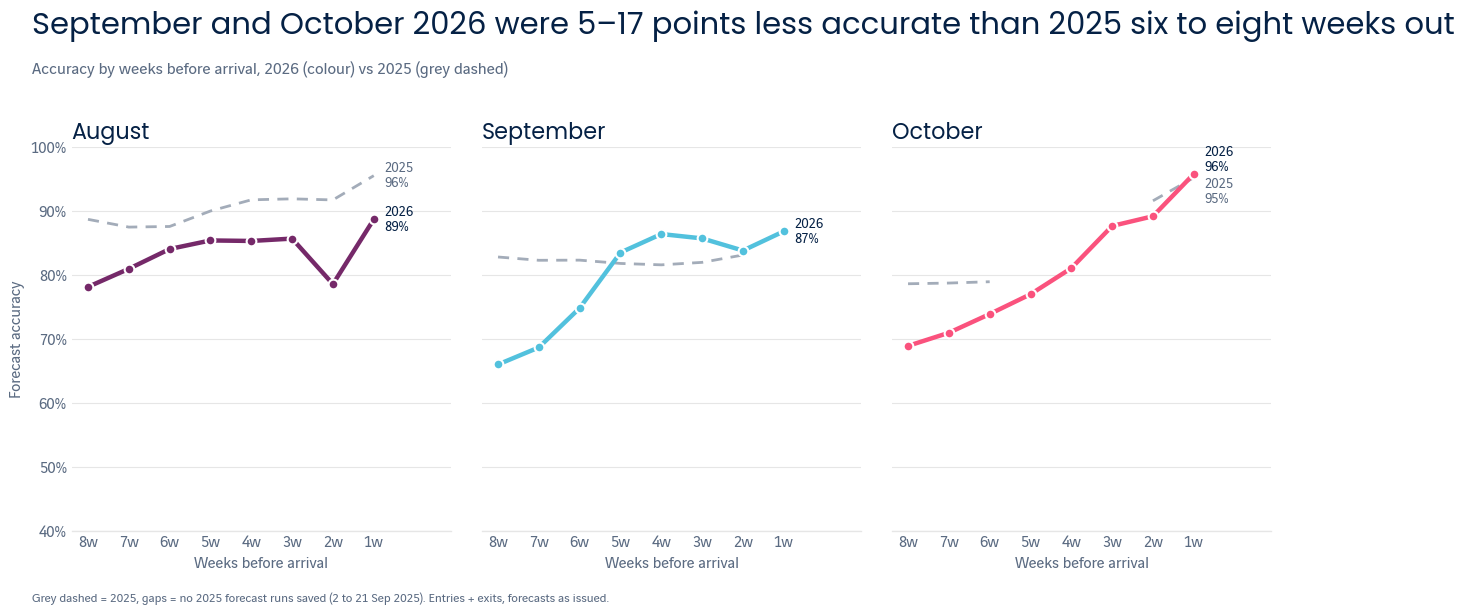

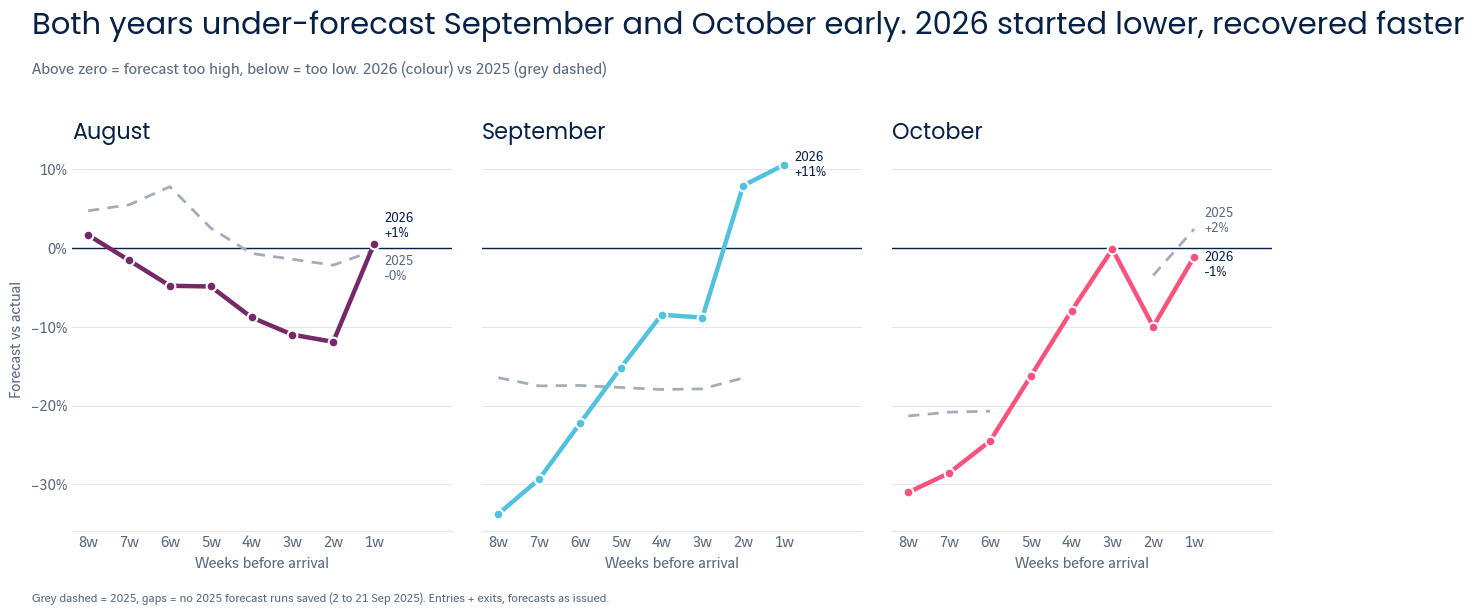

In [25]:
# -----------------------------------------------------------------------------
# Charts 12 and 13: accuracy and over/under, 2026 vs 2025, by weeks out
# -----------------------------------------------------------------------------
YOY_COLOUR = {7: GREEN, 8: PURPLE, 9: LIGHT_BLUE, 10: PINK}

def yoy_panels(metric, ylabel, fmt, title, subtitle, name, zero_line=False, ylim=None):
    fig, axes = plt.subplots(1, len(YOY_MONTHS), figsize=SLIDE, sharey=True)
    axes = np.atleast_1d(axes)
    fig.subplots_adjust(top=0.74, bottom=0.14, left=0.07, right=0.97, wspace=0.08)
    xw = np.arange(len(WEEKS_OUT))
    for ax, m in zip(axes, YOY_MONTHS):
        if zero_line:
            ax.axhline(0, color=DARK_BLUE, lw=1)
        lasts = {}
        for yr, style in [(2025, dict(color=LY_GREY, lw=2, ls=(0, (4, 3)))),
                          (2026, dict(color=YOY_COLOUR.get(m, DARK_BLUE), lw=3.2, marker="o", ms=7, mec="white", mew=1.5))]:
            s = yoy.loc[yr].get(metric)
            vals = [s.get((m, w), np.nan) for w in WEEKS_OUT]
            ax.plot(xw, vals, **style, zorder=3 if yr == 2026 else 2)
            if not np.isnan(vals[-1]):
                lasts[yr] = vals[-1]
        gap = 0.05 if metric == "accuracy" else 0.055          # keep the two end labels apart
        pos = dict(lasts)
        if len(lasts) == 2 and abs(lasts[2026] - lasts[2025]) < gap:
            hi, lo = (2026, 2025) if lasts[2026] >= lasts[2025] else (2025, 2026)
            mid = (lasts[2026] + lasts[2025]) / 2
            pos[hi], pos[lo] = mid + gap / 2, mid - gap / 2
        for yr, v in lasts.items():
            ax.text(xw[-1] + 0.25, pos[yr], f"{yr}\n{fmt(v)}", fontsize=10.5, va="center",
                    color=DARK_BLUE if yr == 2026 else MUTED)
        ax.set_title(MONTH_LONG[m], fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
        ax.set_xticks(xw[::1], [f"{w}w" for w in WEEKS_OUT])
        ax.set_xlim(-0.4, len(xw) + 0.9)
        ax.set_xlabel("Weeks before arrival")
        ax.yaxis.set_major_formatter(pct)
    axes[0].set_ylabel(ylabel)
    if ylim:
        axes[0].set_ylim(*ylim)
    headline(fig, title, subtitle)
    footnote(fig, "Grey dashed = 2025, gaps = no 2025 forecast runs saved (2 to 21 Sep 2025). Entries + exits, forecasts as issued.")
    plt.show()

acc = yoy["accuracy"]
gap6 = {m: acc.get((2026, m, 6), np.nan) - acc.get((2025, m, 6), np.nan) for m in YOY_MONTHS}
gap1 = {m: acc.get((2026, m, 1), np.nan) - acc.get((2025, m, 1), np.nan) for m in YOY_MONTHS}
print("6w accuracy change vs 2025 (pts):", {MONTH_LONG[m]: round(v * 100, 1) for m, v in gap6.items()})
print("1w accuracy change vs 2025 (pts):", {MONTH_LONG[m]: round(v * 100, 1) for m, v in gap1.items()})

early = [(acc.get((2026, m, w)) - acc.get((2025, m, w))) * 100 for m in YOY_MONTHS if m in (9, 10)
         for w in (8, 7, 6) if (2025, m, w) in acc.index]
yoy_panels("accuracy", "Forecast accuracy", lambda v: f"{v:.0%}",
           f"September and October 2026 were {-max(early):.0f}–{-min(early):.0f} points less accurate than 2025 six to eight weeks out",
           "Accuracy by weeks before arrival, 2026 (colour) vs 2025 (grey dashed)",
           "12_yoy_accuracy", ylim=(0.4, 1.0))
yoy_panels("bias", "Forecast vs actual", lambda v: f"{v:+.0%}",
           "Both years under-forecast September and October early. 2026 started lower, recovered faster",
           "Above zero = forecast too high, below = too low. 2026 (colour) vs 2025 (grey dashed)",
           "13_yoy_bias", zero_line=True)

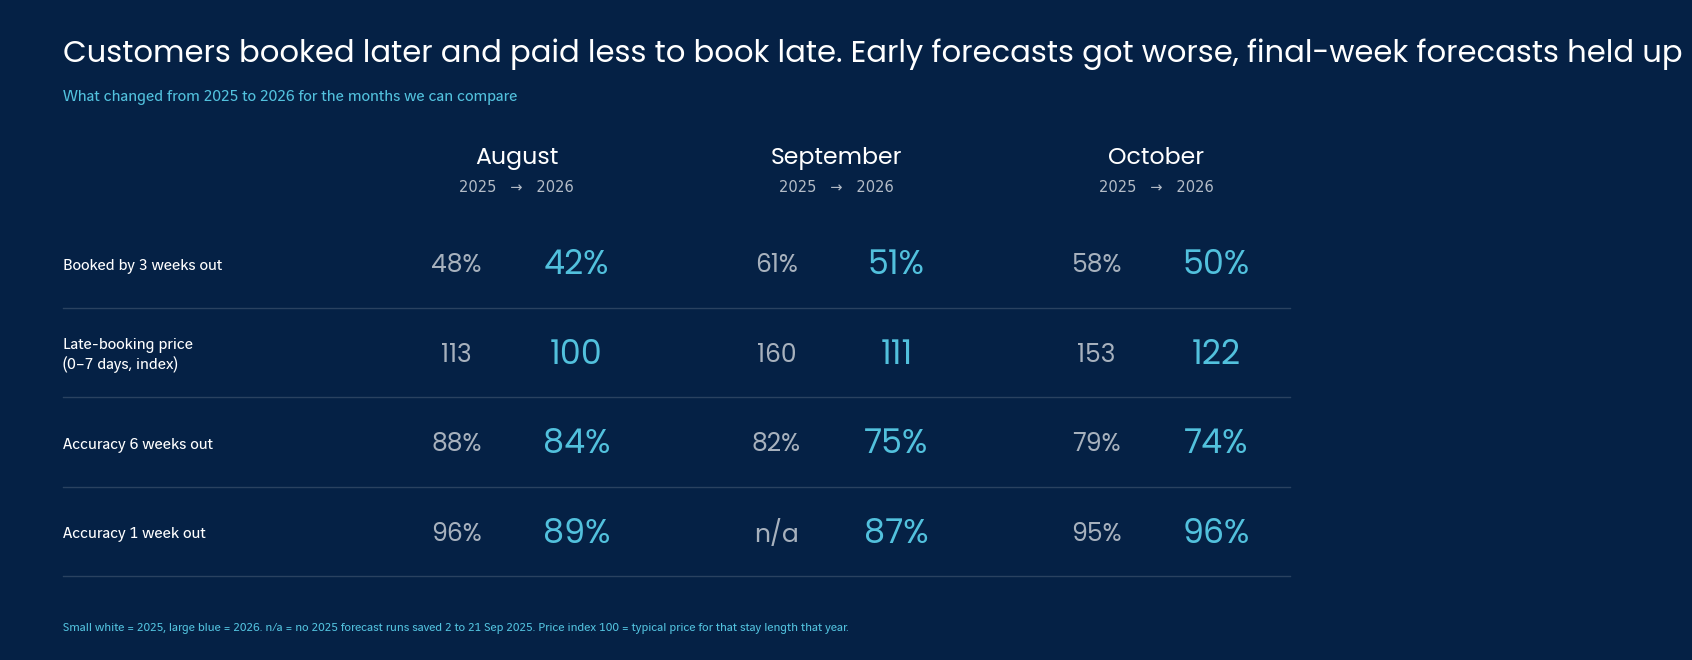

In [26]:
# -----------------------------------------------------------------------------
# Chart 14: what changed year on year, and what it did to accuracy
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=SLIDE, facecolor=DARK_BLUE)
fig.add_axes([0, 0, 1, 1]).axis("off")   # gives the figure an axes so it displays inline
headline(fig, "Customers booked later and paid less to book late. Early forecasts got worse, final-week forecasts held up",
         "What changed from 2025 to 2026 for the months we can compare", dark=True)

def booked3(y, m):
    return curves[(y, m)][21]

yoy_rows = [
    ("Booked by 3 weeks out", lambda m, y: f"{booked3(y, m):.0%}"),
    ("Late-booking price\n(0–7 days, index)", lambda m, y: f"{late_premium.loc[m, y]:.0f}"),
    ("Accuracy 6 weeks out", lambda m, y: f"{acc[(y, m, 6)]:.0%}" if (y, m, 6) in acc.index else "n/a"),
    ("Accuracy 1 week out", lambda m, y: f"{acc[(y, m, 1)]:.0%}" if (y, m, 1) in acc.index else "n/a"),
]
ncol = len(YOY_MONTHS)
col_x = np.linspace(0.38, 0.86, ncol)
row_y = [0.60, 0.46, 0.32, 0.18]
for cx, m in zip(col_x, YOY_MONTHS):
    fig.text(cx, 0.76, MONTH_LONG[m], fontsize=17, fontfamily=HEAD_FONT, color="white", ha="center")
    fig.text(cx, 0.715, "2025   →   2026", fontsize=10.5, color="white", alpha=0.7, ha="center", fontfamily="DejaVu Sans")
for (label, fn), ry in zip(yoy_rows, row_y):
    fig.text(0.04, ry, label, fontsize=12.5, color="white", va="center", linespacing=1.3)
    for cx, m in zip(col_x, YOY_MONTHS):
        fig.text(cx - 0.045, ry, fn(m, 2025), fontsize=18, color="white", alpha=0.65, ha="center", va="center", fontfamily=HEAD_FONT)
        fig.text(cx + 0.045, ry, fn(m, 2026), fontsize=24, color=LIGHT_BLUE, ha="center", va="center", fontfamily=HEAD_FONT)
    fig.add_artist(plt.Line2D([0.04, 0.96], [ry - 0.065, ry - 0.065], color="white", alpha=0.15, lw=1,
                              transform=fig.transFigure))
footnote(fig, "Small white = 2025, large blue = 2026. n/a = no 2025 forecast runs saved 2 to 21 Sep 2025. Price index 100 = typical price for that stay length that year.", dark=True)
plt.show()

## 8. The story: summer 2026 FastPark forecast

**In one line:** the forecast was reliable close to arrival, and its earlier misses moved with late-booking pricing.
While late-booking prices were above 2025 the forecast ran too high; once they were cut in August it ran too low, and
customers booked later than in 2025. The forecast has no price input, so this is a correlation between pricing and
forecast error, not something the forecast was built on.

The roster point (3 weeks out, when the roster is confirmed) is highlighted throughout.

| # | Slide | Message | Chart |
|---|---|---|---|
| 0 | Summary | Six numbers that tell the story | chart 00 |
| 1 | Accuracy improves as arrival approaches | 75% at 8 weeks, 83% at the roster point, 91% at 1 week; the final week was reliable every month | chart 23 (R1 and weekly accuracy) |
| 2 | The errors flipped direction in August, in step with pricing | Late prices above 2025 to July, below from August; customers booked later; the forecast went from too high to too low | chart 18 |
| 3 | The price curve itself | June kept a steep late premium; September and October flattened it | chart 04 |
| 4 | The evidence, week by week | r = 0.75 at the roster point; strong from 8 to 3 weeks out, fades in the final fortnight | chart 17, chart 07 |
| 5 | The roster point by month | 83% overall; September only reached 86% with a +32% manual uplift | chart 23 (3 weeks out column) |
| 6 | What the manual uplifts did | They rescued September 3 to 6 weeks out, but most uplifted forecasts ended up too high | chart 09, chart 11 |
| 7 | June vs September and October, and 2025 | June steady at every horizon; September and October started far lower; both were under-forecast early in 2025 too, but less | chart 16, chart 14 |
| 8 | What we'd take from summer 2026 | Connect pricing to the forecast, tighten uplifts, keep a full record | (text, end of this section) |

**Appendix:** `03`, `10`, `12`, `13`. **Not used:** `05`, `06`, `08` (covered by `18`, `17` and `16`; `05` and the
section 4 introduction describe the summer forecast as a booking-curve model, which it wasn't beyond 14 days).

In [27]:
# -----------------------------------------------------------------------------
# Key numbers for the story (roster point = 3 weeks out)
# -----------------------------------------------------------------------------
ROSTER_W = 3

roster = pd.DataFrame({
    "issued": uplift_month.xs(ROSTER_W, level="weeks_out")["acc_issued"],
    "no_uplift": uplift_month.xs(ROSTER_W, level="weeks_out")["acc_standard"],
    "uplift": uplift_month.xs(ROSTER_W, level="weeks_out")["applied"],
    "bias": by_month_week.xs(ROSTER_W, level="weeks_out")["bias"],
}).reindex(MONTHS)
roster["acc_2025"] = [acc.get((2025, m, ROSTER_W), np.nan) for m in MONTHS]

# Roster-point accuracy for the months both years can be compared on
both = [m for m in MONTHS if not np.isnan(roster.loc[m, "acc_2025"])]
yoy_roster = {
    2026: score(fa[fa["month"].isin(both) & (fa["weeks_out"] == ROSTER_W)], "weeks_out").loc[ROSTER_W, "accuracy"],
    2025: score(fa25[fa25["month"].isin(both) & (fa25["weeks_out"] == ROSTER_W)], "weeks_out").loc[ROSTER_W, "accuracy"],
}

# Weekly link between late-price change vs 2025 and forecast error WITHOUT manual uplifts
week_days = fu.groupby(["week_start", "weeks_out"])["Date"].nunique().rename("days").reset_index()
price_link = uplift_week.merge(week_days, on=["week_start", "weeks_out"])
price_link = price_link[price_link["days"] >= 4].copy()
price_link["week"] = price_link["week_start"].dt.isocalendar().week.astype(int)
price_link["bias_no_uplift"] = 1 / (1 + price_link["needed"]) - 1          # standard forecast / actual - 1
price_link["month"] = month_key(price_link["week_start"])
price_link = price_link.merge(late_wk[["late_price_change"]].reset_index(), on="week")
price_r = price_link.groupby("weeks_out").apply(
    lambda d: d["late_price_change"].corr(d["bias_no_uplift"]), include_groups=False)

summer = {w: by_week.loc[w, "accuracy"] for w in WEEKS_OUT}
jun_journey = [acc.get((2026, 6, w)) for w in WEEKS_OUT]

display((roster * 100).round(1).rename(index=MONTH_LONG))
print(f"Summer at roster point: {summer[ROSTER_W]:.1%} (without manual uplifts {uplift_horizon.loc[ROSTER_W, 'acc_standard']:.1%})")
print(f"Roster point, {', '.join(MONTH_LONG[m] for m in both)}: 2026 {yoy_roster[2026]:.1%} vs 2025 {yoy_roster[2025]:.1%}")
print("Price link (no-uplift forecast), r by weeks out:", price_r.loc[WEEKS_OUT].round(2).to_dict())

# -----------------------------------------------------------------------------
# Month-level view of the story: price change -> booking timing -> forecast error (no manual uplift)
# -----------------------------------------------------------------------------
price_chg = late_premium[2026] - late_premium[2025]
flip = pd.DataFrame({
    "late_price_vs_2025": price_chg.reindex(MONTHS),
    "booked_by_3w_vs_2025": [timing.loc[MONTH_LONG[m], "3w"] for m in MONTHS],
    "error_6w_no_uplift": [1 / (1 + uplift_month.loc[(m, 6), "needed"]) - 1 for m in MONTHS],
    "error_3w_no_uplift": [1 / (1 + uplift_month.loc[(m, ROSTER_W), "needed"]) - 1 for m in MONTHS],
}, index=MONTHS)
EARLY, LATE = [4, 5, 6, 7], [8, 9, 10]

def group_bias(months, w):
    return score(fa[fa["month"].isin(months) & (fa["weeks_out"] == w)], "weeks_out").loc[w, "bias"]

flip_summary = {
    "price": (price_chg.loc[EARLY].mean(), price_chg.loc[LATE].mean()),
    "bias6": (group_bias(EARLY, 6), group_bias(LATE, 6)),
}
final_week_min = by_month_week.xs(1, level="weeks_out")["accuracy"].loc[MONTHS].min()
display(flip.round(3).rename(index=MONTH_LONG))
print("Late price vs 2025, Apr-Jul / Aug-Oct:", [round(v, 1) for v in flip_summary["price"]])
print("Bias 6 weeks out, Apr-Jul / Aug-Oct:", [f"{v:+.1%}" for v in flip_summary["bias6"]])

,issued,no_uplift,uplift,bias,acc_2025
month,,,,,
April,71.3,73.2,2.1,26.3,NaN
May,85.3,87.1,7.0,6.0,NaN
June,87.1,86.2,4.4,10.1,NaN
July,75.9,75.9,0.0,15.8,90.5
August,85.8,85.8,0.0,-11.0,92.0
September,85.8,69.6,30.8,-8.8,82.0
October,87.7,87.7,0.0,-0.1,NaN


Summer at roster point: 83.0% (without manual uplifts 80.6%)
Roster point, July, August, September: 2026 83.2% vs 2025 87.9%
Price link (no-uplift forecast), r by weeks out: {8: 0.71, 7: 0.76, 6: 0.79, 5: 0.81, 4: 0.8, 3: 0.75, 2: 0.36, 1: 0.16}


,late_price_vs_2025,booked_by_3w_vs_2025,error_6w_no_uplift,error_3w_no_uplift
April,14.288,0.177,0.200,0.237
May,26.669,0.093,0.088,-0.009
June,16.668,-0.006,0.036,0.055
July,13.247,0.009,0.305,0.158
August,-12.502,-0.061,-0.048,-0.110
September,-48.578,-0.095,-0.364,-0.303
October,-30.440,-0.080,-0.245,-0.001


Late price vs 2025, Apr-Jul / Aug-Oct: [np.float64(17.7), np.float64(-30.5)]
Bias 6 weeks out, Apr-Jul / Aug-Oct: ['+16.4%', '-17.6%']


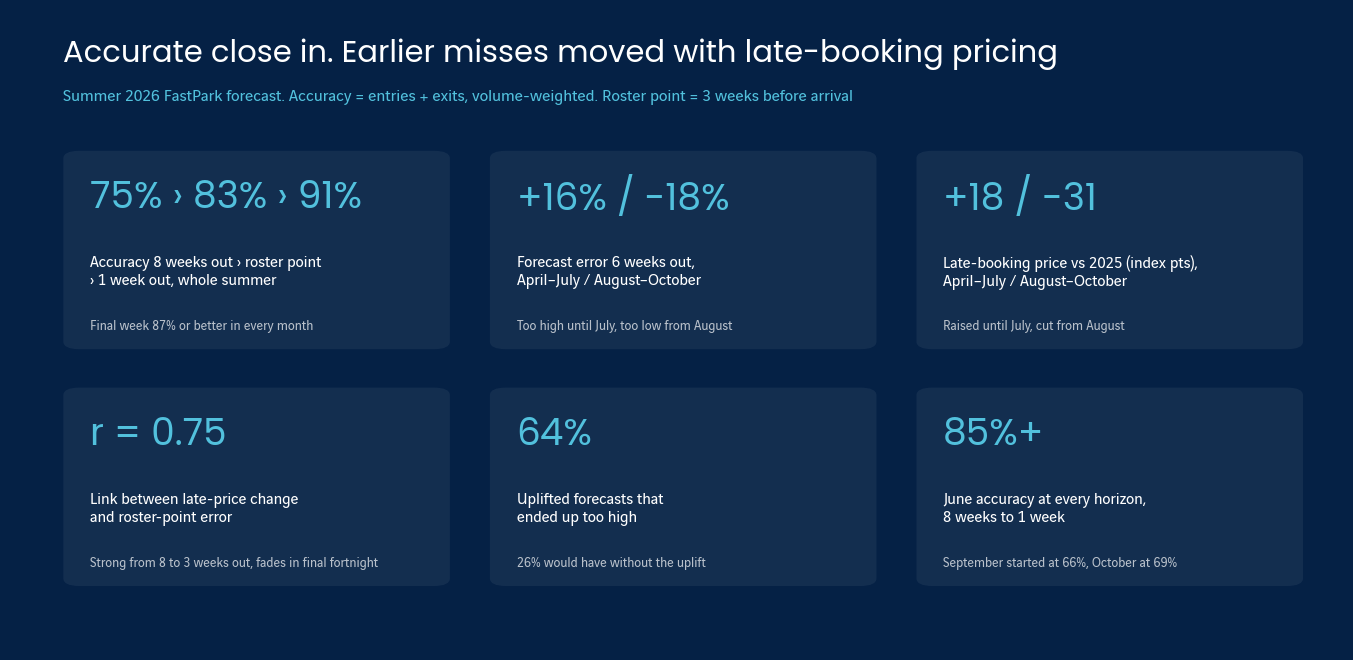

In [28]:
# -----------------------------------------------------------------------------
# Chart 00: executive summary
# -----------------------------------------------------------------------------
tiles = [
    (f"{summer[8]:.0%} › {summer[ROSTER_W]:.0%} › {summer[1]:.0%}", "Accuracy 8 weeks out › roster point\n› 1 week out, whole summer",
     f"Final week {final_week_min:.0%} or better in every month"),
    (f"{flip_summary['bias6'][0]:+.0%} / {flip_summary['bias6'][1]:+.0%}", "Forecast error 6 weeks out,\nApril–July / August–October",
     "Too high until July, too low from August"),
    (f"{flip_summary['price'][0]:+.0f} / {flip_summary['price'][1]:+.0f}", "Late-booking price vs 2025 (index pts),\nApril–July / August–October",
     "Raised until July, cut from August"),
    (f"r = {price_r.loc[ROSTER_W]:.2f}", "Link between late-price change\nand roster-point error",
     "Strong from 8 to 3 weeks out, fades in final fortnight"),
    (f"{over_issued:.0%}", "Uplifted forecasts that\nended up too high",
     f"{over_standard:.0%} would have without the uplift"),
    (f"{min(jun_journey):.0%}+", "June accuracy at every horizon,\n8 weeks to 1 week",
     f"September started at {acc[(2026, 9, 8)]:.0%}, October at {acc[(2026, 10, 8)]:.0%}"),
]
fig = plt.figure(figsize=SLIDE, facecolor=DARK_BLUE)
fig.add_axes([0, 0, 1, 1]).axis("off")   # gives the figure an axes so it displays inline
headline(fig, "Accurate close in. Earlier misses moved with late-booking pricing",
         "Summer 2026 FastPark forecast. Accuracy = entries + exits, volume-weighted. Roster point = 3 weeks before arrival", dark=True)
xs, ys = [0.04, 0.36, 0.68], [0.47, 0.10]
for k, (big, label, sub) in enumerate(tiles):
    x, y = xs[k % 3], ys[k // 3]
    fig.add_artist(FancyBboxPatch((x, y), 0.29, 0.31, boxstyle="round,pad=0,rounding_size=0.012",
                                  transform=fig.transFigure, facecolor="white", alpha=0.06, edgecolor="none"))
    fig.text(x + 0.02, y + 0.235, big, fontsize=27, fontfamily=HEAD_FONT, color=LIGHT_BLUE, va="center")
    fig.text(x + 0.02, y + 0.12, label, fontsize=12, color="white", va="center", linespacing=1.25)
    fig.text(x + 0.02, y + 0.035, sub, fontsize=10, color="white", alpha=0.7, va="center")
plt.show()

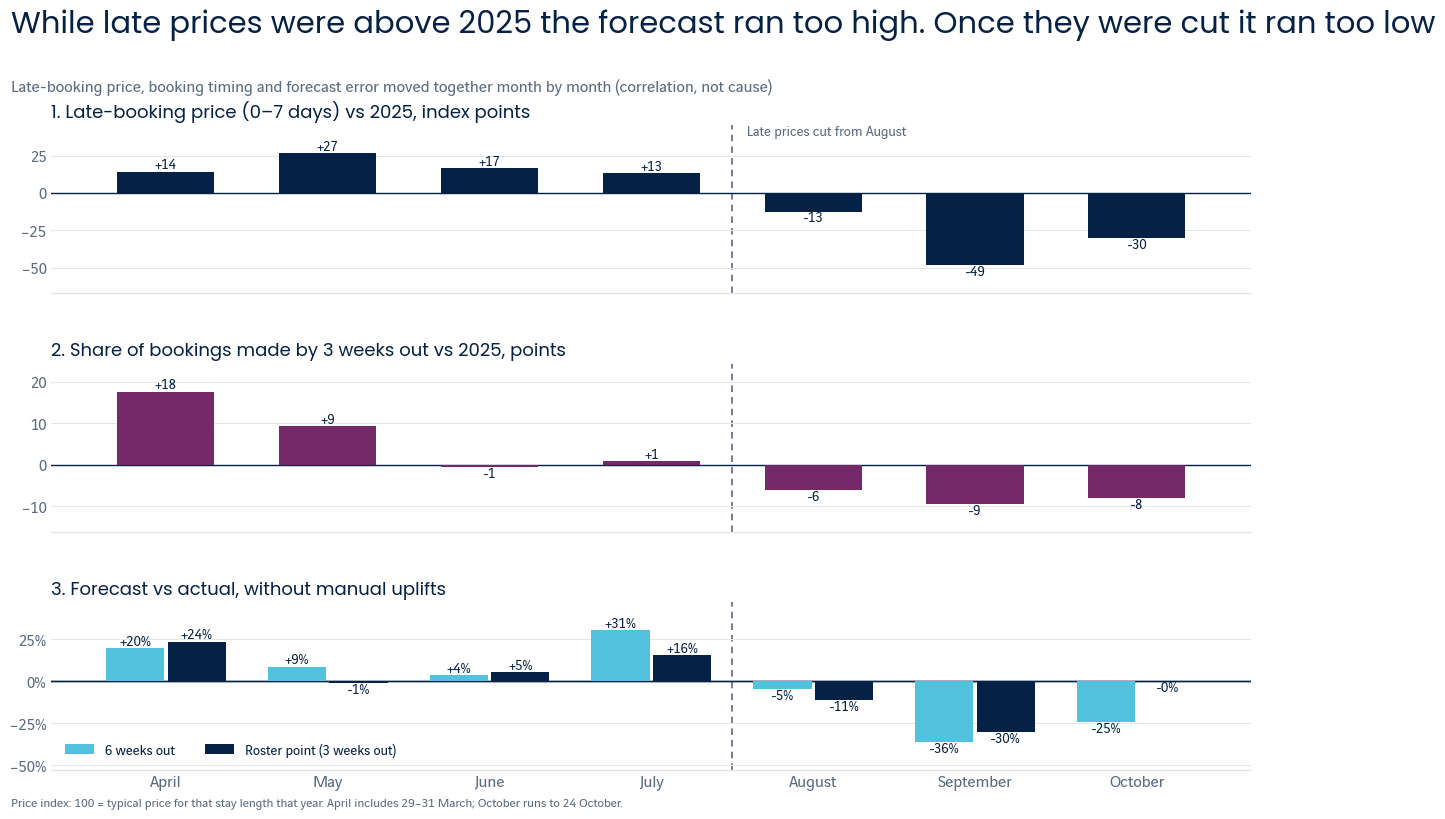

In [29]:
# -----------------------------------------------------------------------------
# Chart 18: the story by month - late price -> booking timing -> forecast error
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(13.33, 8.6), sharex=True)
fig.subplots_adjust(top=0.82, bottom=0.07, left=0.07, right=0.97, hspace=0.42)
xm = np.arange(len(MONTHS))
split = MONTHS.index(8) - 0.5

def bar_panel(ax, vals, colour, title, fmt, width=0.6, offset=0.0, label=None):
    ax.bar(xm + offset, vals, width=width, color=colour, zorder=3, label=label)
    for xi, v in zip(xm + offset, vals):
        ax.text(xi, v, fmt(v), ha="center", va="bottom" if v >= 0 else "top", fontsize=10.5, color=DARK_BLUE)
    ax.axhline(0, color=DARK_BLUE, lw=1)
    ax.set_title(title, fontsize=13, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")

for ax in axes:
    ax.axvline(split, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)

bar_panel(axes[0], flip["late_price_vs_2025"].values, DARK_BLUE,
          "1. Late-booking price (0–7 days) vs 2025, index points", lambda v: f"{v:+.0f}")
bar_panel(axes[1], flip["booked_by_3w_vs_2025"].values * 100, PURPLE,
          "2. Share of bookings made by 3 weeks out vs 2025, points", lambda v: f"{v:+.0f}")
bar_panel(axes[2], flip["error_6w_no_uplift"].values, LIGHT_BLUE,
          "3. Forecast vs actual, without manual uplifts", lambda v: f"{v:+.0%}", width=0.36, offset=-0.19, label="6 weeks out")
bar_panel(axes[2], flip["error_3w_no_uplift"].values, DARK_BLUE,
          "3. Forecast vs actual, without manual uplifts", lambda v: f"{v:+.0%}", width=0.36, offset=0.19, label="Roster point (3 weeks out)")
axes[2].yaxis.set_major_formatter(pct)
axes[2].legend(loc="lower left", ncol=2, fontsize=10.5)
for ax in axes:
    lo, hi = ax.get_ylim()
    pad = (hi - lo) * 0.18
    ax.set_ylim(lo - pad, hi + pad)
axes[0].text(split + 0.05, axes[0].get_ylim()[1], "  Late prices cut from August", fontsize=10.5, color=MUTED, va="top")
axes[-1].set_xticks(xm, [MONTH_LONG[m] for m in MONTHS], fontsize=12.5)

headline(fig, "While late prices were above 2025 the forecast ran too high. Once they were cut it ran too low",
         "Late-booking price, booking timing and forecast error moved together month by month (correlation, not cause)")
footnote(fig, "Price index: 100 = typical price for that stay length that year. April includes 29–31 March; October runs to 24 October.")
plt.show()

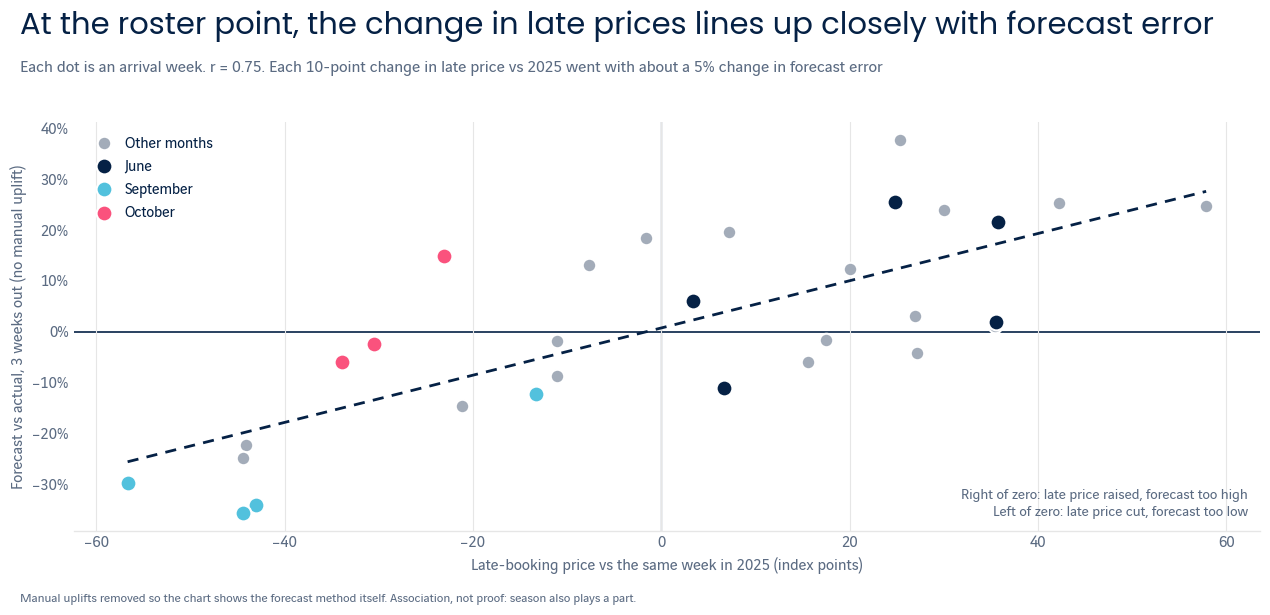

In [30]:
# -----------------------------------------------------------------------------
# Chart 17: late-price change vs 2025 against roster-point error (forecast without manual uplift)
# -----------------------------------------------------------------------------
d = price_link[price_link["weeks_out"] == ROSTER_W]
r = d["late_price_change"].corr(d["bias_no_uplift"])
slope, intercept = np.polyfit(d["late_price_change"], d["bias_no_uplift"], 1)

fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.78, bottom=0.14, left=0.08, right=0.97)
ax.grid(axis="both")
ax.axhline(0, color=DARK_BLUE, lw=1.2, zorder=1)
ax.axvline(0, color=DARK_BLUE, lw=1, alpha=0.4, zorder=1)
xx = np.linspace(d["late_price_change"].min(), d["late_price_change"].max(), 50)
ax.plot(xx, slope * xx + intercept, color=DARK_BLUE, lw=2, ls=(0, (4, 3)), zorder=2)
other = d[~d["month"].isin(FOCUS)]
ax.scatter(other["late_price_change"], other["bias_no_uplift"], s=95, color=LY_GREY, edgecolor="white", lw=1.5,
           zorder=3, label="Other months")
for m in FOCUS:
    s = d[d["month"] == m]
    ax.scatter(s["late_price_change"], s["bias_no_uplift"], s=130, color=FOCUS_COLOUR[m], edgecolor="white",
               lw=1.5, zorder=4, label=MONTH_LONG[m])
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Late-booking price vs the same week in 2025 (index points)")
ax.set_ylabel("Forecast vs actual, 3 weeks out (no manual uplift)")
ax.text(0.99, 0.03, "Right of zero: late price raised, forecast too high\nLeft of zero: late price cut, forecast too low",
        transform=ax.transAxes, ha="right", va="bottom", color=MUTED, fontsize=11, linespacing=1.4)
ax.legend(loc="upper left", fontsize=11.5, handletextpad=0.3)

headline(fig, "At the roster point, the change in late prices lines up closely with forecast error",
         f"Each dot is an arrival week. r = {r:.2f}. Each 10-point change in late price vs 2025 went with about a "
         f"{abs(slope) * 10:.0%} change in forecast error")
footnote(fig, "Manual uplifts removed so the chart shows the forecast method itself. Association, not proof: season also plays a part.")
plt.show()

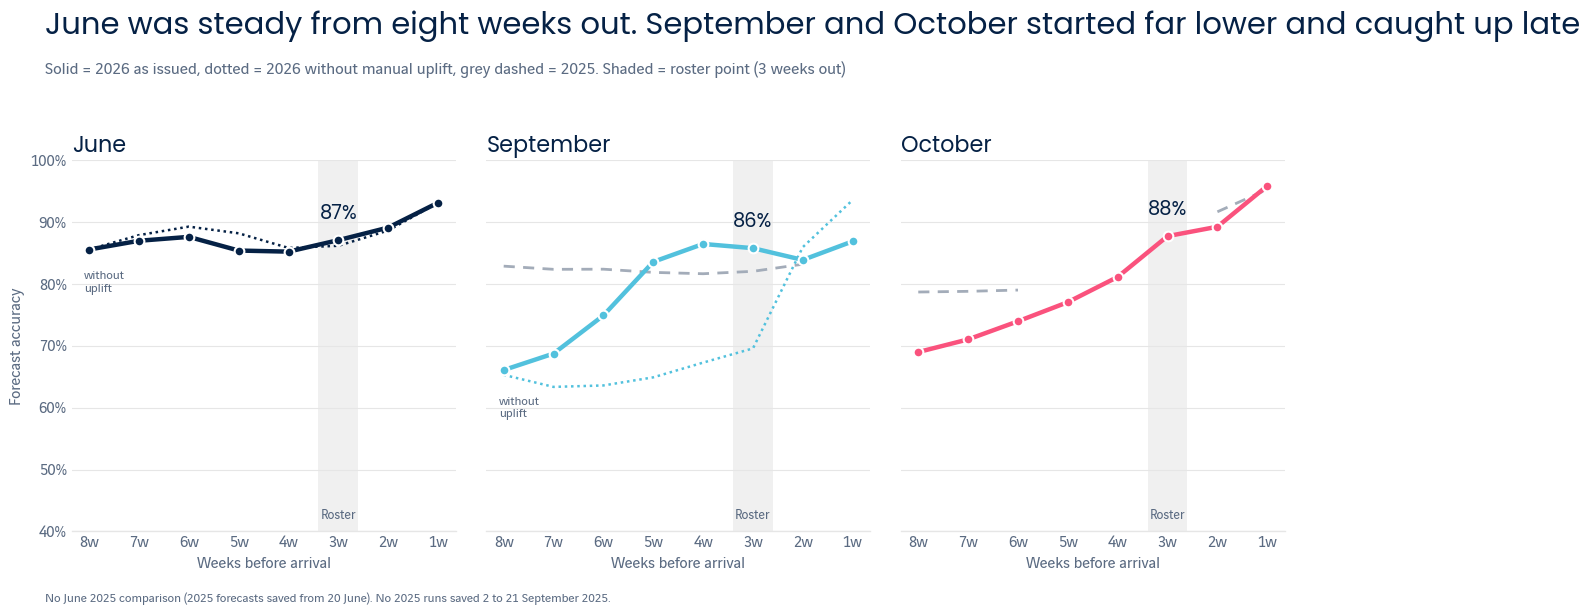

In [31]:
# -----------------------------------------------------------------------------
# Chart 16: June vs September vs October, 8 weeks out to 1 week out
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=SLIDE, sharey=True)
fig.subplots_adjust(top=0.72, bottom=0.14, left=0.06, right=0.97, wspace=0.08)
xw = np.arange(len(WEEKS_OUT))
rx = WEEKS_OUT.index(ROSTER_W)

for ax, m in zip(axes, FOCUS):
    col = FOCUS_COLOUR[m]
    ax.axvspan(rx - 0.4, rx + 0.4, color=GREY, alpha=0.6, lw=0, zorder=0)
    ax.text(rx, 0.415, "Roster", ha="center", va="bottom", fontsize=10, color=MUTED)
    issued = [acc.get((2026, m, w), np.nan) for w in WEEKS_OUT]
    no_up = [uplift_month["acc_standard"].get((m, w), np.nan) for w in WEEKS_OUT]
    ly = [acc.get((2025, m, w), np.nan) for w in WEEKS_OUT]
    ax.plot(xw, ly, color=LY_GREY, lw=2, ls=(0, (4, 3)), zorder=2)
    if np.nanmax(np.abs(np.array(issued) - np.array(no_up))) >= 0.005:
        ax.plot(xw, no_up, color=col, lw=1.8, ls=(0, (1, 1.5)), zorder=2)
        ax.text(xw[0] - 0.1, no_up[0] - 0.035, "without\nuplift", fontsize=9.5, color=MUTED, va="top")
    ax.plot(xw, issued, color=col, lw=3.2, marker="o", ms=7, mec="white", mew=1.5, zorder=3)
    ax.text(rx, issued[rx] + 0.035, f"{issued[rx]:.0%}", ha="center", fontsize=14, fontfamily=HEAD_FONT, color=DARK_BLUE)
    ax.set_title(MONTH_LONG[m], fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
    ax.set_xticks(xw, [f"{w}w" for w in WEEKS_OUT])
    ax.set_xlabel("Weeks before arrival")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylim(0.4, 1.0)
axes[0].set_ylabel("Forecast accuracy")

headline(fig, "June was steady from eight weeks out. September and October started far lower and caught up late",
         "Solid = 2026 as issued, dotted = 2026 without manual uplift, grey dashed = 2025. Shaded = roster point (3 weeks out)")
footnote(fig, "No June 2025 comparison (2025 forecasts saved from 20 June). No 2025 runs saved 2 to 21 September 2025.")
plt.show()

### What we'd take from summer 2026

1. **Connect pricing decisions to the forecast.** Each 10-point change in the late-booking price vs the same week last
   year went with about a 5% change in roster-point error. When late prices change, the forecast team should know before
   the roster point.
2. **Test adding a price signal to the forecast**, given how closely price changes tracked the error, rather than relying
   on manual uplifts after the event.
3. **Keep manual uplifts for genuine events, size them from evidence, and avoid them inside two weeks**, where bookings
   already show the demand. Most of this summer's uplifts ended up too high.
4. **Save every forecast run and log every adjustment.** Gaps in the 2025 runs (2 to 21 September) limited the
   year-on-year comparison, and the uplift notes had to be reconstructed.

## 9. Other factors: other car parks, school holidays and weekdays

Pricing and uplifts aren't the only things that could explain the forecast error. This section tests three more,
using the forecast **without manual uplifts** (so we're looking at the forecast method, not our adjustments):

1. **Other car parks:** did all car parks grow or shrink vs 2025, or did FastPark gain or lose share? Did the other car
   parks' late prices move the way FastPark's did?
2. **School holidays:** is the forecast worse at the start, middle or end of a holiday, and did holidays fall in
   different weeks to 2025?
3. **Weekdays:** is the error concentrated on particular days?
4. **Public holidays and events:** bank holiday weekends, the Royal Highland Show, Summer Sessions and the Festival.

Holiday and event dates come from the forecast calendar (`MANUAL_CALENDAR_PERIODS`).

All of these are correlations with the forecast error, not causes.

In [32]:
# -----------------------------------------------------------------------------
# All car parks: bookings for the same windows as FastPark (2025 and 2026)
# -----------------------------------------------------------------------------
conn = pyodbc.connect(f"DSN={DSN};")
all_bk = pd.read_sql(f"""
SELECT bookingId, createdAt, entryDate, assetName, productName, productTotal, productQuantity, duration
FROM AirportX.v_Bookings
WHERE status = 'B' AND productGroup = 'PARKING'
  AND ( (entryDate >= '{LY_START:%Y-%m-%d}' AND entryDate < '{day_after(LY_END)}')
     OR (entryDate >= '{START:%Y-%m-%d}'    AND entryDate < '{day_after(END)}') )
""", conn)

ab = all_bk.copy()
ab["entry_d"] = pd.to_datetime(ab["entryDate"]).dt.normalize()
ab["created_d"] = pd.to_datetime(ab["createdAt"]).dt.normalize()
ab["lead"] = (ab["entry_d"] - ab["created_d"]).dt.days
ab["year"] = ab["entry_d"].dt.year
ab["month"] = month_key(ab["entry_d"])
ab["week"] = ab["entry_d"].dt.isocalendar().week.astype(int)
ab["group"] = np.where(ab["assetName"].eq("FastPark"), "FastPark", "Other car parks")
ab = ab[ab["month"].isin(MONTHS) & (ab["lead"] >= 0)]

# Price index per car park: price / median price for that car park, year and stay length (x100)
ab["price"] = ab["productTotal"] / ab["productQuantity"].clip(lower=1)
pr = ab[ab["productName"].str.contains("Refundable") & ab["duration"].between(1, 21) & (ab["price"] > 0)].copy()
pr["price_idx"] = pr["price"] / pr.groupby(["assetName", "year", "duration"])["price"].transform("median") * 100

display(ab.groupby(["assetName", "year"]).size().unstack("year").rename(columns=str))

year,2025,2026
assetName,,
FastPark,108830,118123
Long Stay,57788,57911
Mid Stay,23983,24321
Multi,79588,82664
Plane Parking,57399,69202
Terminal,57007,41023


In [33]:
# -----------------------------------------------------------------------------
# Monthly: volumes and late-booking prices vs 2025, FastPark vs other car parks
# -----------------------------------------------------------------------------
vol_m = ab.groupby(["month", "group", "year"]).size().unstack(["group", "year"])
all_m = ab.groupby(["month", "year"]).size().unstack("year")
vol_chg_m = pd.DataFrame({
    "FastPark": vol_m[("FastPark", 2026)] / vol_m[("FastPark", 2025)] - 1,
    "Other car parks": vol_m[("Other car parks", 2026)] / vol_m[("Other car parks", 2025)] - 1,
    "All car parks": all_m[2026] / all_m[2025] - 1,
})
fp_share_m = pd.DataFrame({y: vol_m[("FastPark", y)] / all_m[y] for y in (2025, 2026)})

late_m = pr[pr["lead"] <= 7].groupby(["month", "group", "year"])["price_idx"].median().unstack(["group", "year"])
late_chg_m = pd.DataFrame({g: late_m[(g, 2026)] - late_m[(g, 2025)] for g in ["FastPark", "Other car parks"]})

print("Bookings vs 2025:")
display((vol_chg_m * 100).round(1).rename(index=MONTH_LONG))
print("FastPark share of all car park bookings:")
display((fp_share_m * 100).round(1).rename(index=MONTH_LONG))
print("Late-booking price (0-7 days) vs 2025, index points:")
display(late_chg_m.round(1).rename(index=MONTH_LONG))

Bookings vs 2025:


,FastPark,Other car parks,All car parks
month,,,
April,4.4,2.9,3.3
May,1.7,-10.3,-7.0
June,4.6,3.8,4.0
July,-4.7,3.7,1.2
August,11.0,1.2,4.1
September,27.2,-0.4,7.3
October,15.5,-0.9,3.9


FastPark share of all car park bookings:


,2025,2026
month,,
April,27.3,27.5
May,27.3,29.9
June,27.7,27.9
July,29.4,27.7
August,29.5,31.4
September,28.2,33.4
October,29.2,32.4


Late-booking price (0-7 days) vs 2025, index points:


,FastPark,Other car parks
month,,
April,14.3,0.0
May,26.7,16.7
June,16.7,-10.0
July,13.2,8.3
August,-12.5,0.0
September,-48.6,3.3
October,-30.4,-2.4


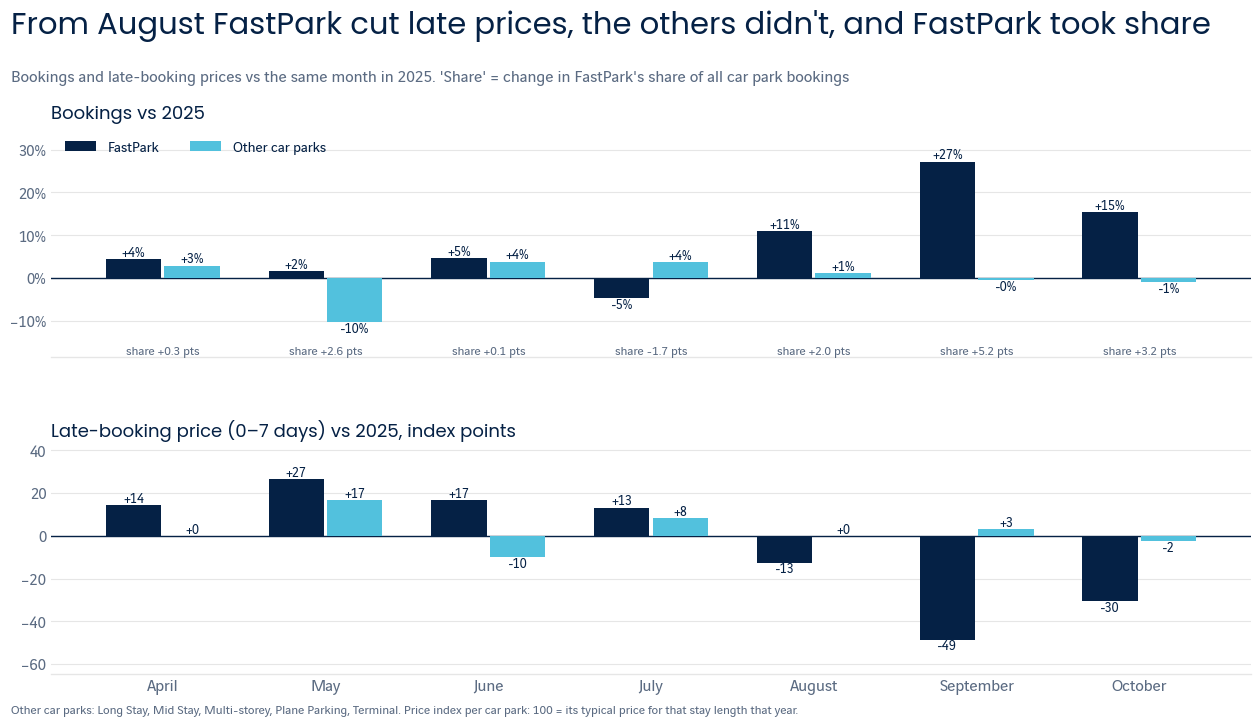

In [34]:
# -----------------------------------------------------------------------------
# Chart 20: did all car parks move, or just FastPark?  (volumes and late prices vs 2025)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(13.33, 7.6), sharex=True)
fig.subplots_adjust(top=0.80, bottom=0.08, left=0.07, right=0.97, hspace=0.38)
xm = np.arange(len(MONTHS))
GROUP_COLOUR = {"FastPark": DARK_BLUE, "Other car parks": LIGHT_BLUE}

def grouped(ax, df, fmt, title):
    for k, g in enumerate(["FastPark", "Other car parks"]):
        vals = df[g].reindex(MONTHS).values
        xs = xm + (k - 0.5) * 0.36
        ax.bar(xs, vals, width=0.34, color=GROUP_COLOUR[g], label=g, zorder=3)
        for xi, v in zip(xs, vals):
            ax.text(xi, v, fmt(v), ha="center", va="bottom" if v >= 0 else "top", fontsize=10, color=DARK_BLUE)
    ax.axhline(0, color=DARK_BLUE, lw=1)
    ax.set_title(title, fontsize=13, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")
    lo, hi = ax.get_ylim(); pad = (hi - lo) * 0.15
    ax.set_ylim(lo - pad, hi + pad)

grouped(axes[0], vol_chg_m, lambda v: f"{v:+.0%}", "Bookings vs 2025")
axes[0].yaxis.set_major_formatter(pct)
grouped(axes[1], late_chg_m, lambda v: f"{v:+.0f}", "Late-booking price (0–7 days) vs 2025, index points")
axes[0].legend(loc="upper left", ncol=2, fontsize=11)
axes[-1].set_xticks(xm, [MONTH_LONG[m] for m in MONTHS], fontsize=12.5)
for xi, m in zip(xm, MONTHS):
    chg = (fp_share_m.loc[m, 2026] - fp_share_m.loc[m, 2025]) * 100
    axes[0].text(xi, axes[0].get_ylim()[0], f"share {chg:+.1f} pts", ha="center", va="bottom", fontsize=9.5, color=MUTED)

sep_fp, sep_other = vol_chg_m.loc[9, "FastPark"], vol_chg_m.loc[9, "Other car parks"]
headline(fig, f"From August FastPark cut late prices, the others didn't, and FastPark took share",
         "Bookings and late-booking prices vs the same month in 2025. 'Share' = change in FastPark's share of all car park bookings")
footnote(fig, "Other car parks: Long Stay, Mid Stay, Multi-storey, Plane Parking, Terminal. Price index per car park: 100 = its typical price for that stay length that year.")
plt.show()

In [35]:
# -----------------------------------------------------------------------------
# School holidays from the forecast calendar (MANUAL_CALENDAR_PERIODS, school_holiday).
# The calendar stops after summer 2026, so the September weekend and October 2026 are added in the same pattern as 2025.
HOLIDAYS = {
    2025: [("2025-04-04", "2025-04-21", "Easter"), ("2025-05-02", "2025-05-06", "May weekend"),
           ("2025-05-16", "2025-05-19", "May weekend"), ("2025-06-26", "2025-08-11", "Summer"),
           ("2025-09-12", "2025-09-14", "September weekend"), ("2025-10-10", "2025-10-19", "October")],
    2026: [("2026-04-02", "2026-04-20", "Easter"), ("2026-05-01", "2026-05-05", "May weekend"),
           ("2026-05-15", "2026-05-18", "May weekend"), ("2026-06-26", "2026-08-10", "Summer"),
           ("2026-09-11", "2026-09-13", "September weekend (added)"), ("2026-10-09", "2026-10-18", "October (added)")],
}
DAY_TYPES = ["Term time", "Long weekend", "Holiday: first week", "Holiday: middle", "Holiday: last week"]

def day_type(d):
    for a, b, _ in HOLIDAYS.get(d.year, []):
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        if a <= d <= b:
            length = (b - a).days + 1
            if length <= 5:
                return "Long weekend"
            edge = min(7, length // 2)
            if (d - a).days < edge:
                return "Holiday: first week"
            if (b - d).days < edge:
                return "Holiday: last week"
            return "Holiday: middle"
    return "Term time"

for df in (fu, fa25):
    df["day_type"] = df["Date"].map(day_type)
    df["weekday"] = df["Date"].dt.day_name()

def flow_bias(df, by, fc_prefix):
    """Forecast vs actual by group, separately for entries and exits."""
    g = df.groupby(by)[[f"{fc_prefix}entries", f"{fc_prefix}exits", "act_entries", "act_exits"]].sum()
    return pd.DataFrame({
        "entries": g[f"{fc_prefix}entries"] / g["act_entries"] - 1,
        "exits": g[f"{fc_prefix}exits"] / g["act_exits"] - 1,
        "days": df.groupby(by)["Date"].nunique(),
    })

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
roster_fu = fu[fu["weeks_out"] == ROSTER_W]
hol_bias = flow_bias(roster_fu, "day_type", "std_").reindex(DAY_TYPES)
wd_bias = flow_bias(roster_fu, "weekday", "std_").reindex(WEEKDAYS)
hol_bias_25 = flow_bias(fa25[fa25["weeks_out"] == ROSTER_W], "day_type", "fc_").reindex(DAY_TYPES)
wd_bias_25 = flow_bias(fa25[fa25["weeks_out"] == ROSTER_W], "weekday", "fc_").reindex(WEEKDAYS)

print("Roster point, 2026 without manual uplifts: forecast vs actual by day type")
display((hol_bias[["entries", "exits"]] * 100).round(1).assign(days=hol_bias["days"]))
print("Same for 2025 (forecasts as issued, July to October only)")
display((hol_bias_25[["entries", "exits"]] * 100).round(1).assign(days=hol_bias_25["days"]))
print("Roster point, 2026 without manual uplifts: by weekday")
display((wd_bias[["entries", "exits"]] * 100).round(1))

Roster point, 2026 without manual uplifts: forecast vs actual by day type


,entries,exits,days
day_type,,,
Term time,-4.8,-8.0,120
Long weekend,-10.8,1.6,12
Holiday: first week,6.0,19.3,17
Holiday: middle,12.9,13.0,32
Holiday: last week,10.7,-4.0,19


Same for 2025 (forecasts as issued, July to October only)


,entries,exits,days
day_type,,,
Term time,-11.0,-9.9,48
Long weekend,-14.0,-11.3,3
Holiday: first week,-2.8,3.3,2
Holiday: middle,8.4,5.8,25
Holiday: last week,5.5,-10.1,7


Roster point, 2026 without manual uplifts: by weekday


,entries,exits
weekday,,
Monday,-3.3,-4.4
Tuesday,5.8,-0.5
Wednesday,2.5,1.0
Thursday,-0.6,-2.7
Friday,-2.0,-4.2
Saturday,-0.2,-0.3
Sunday,-5.7,-2.1


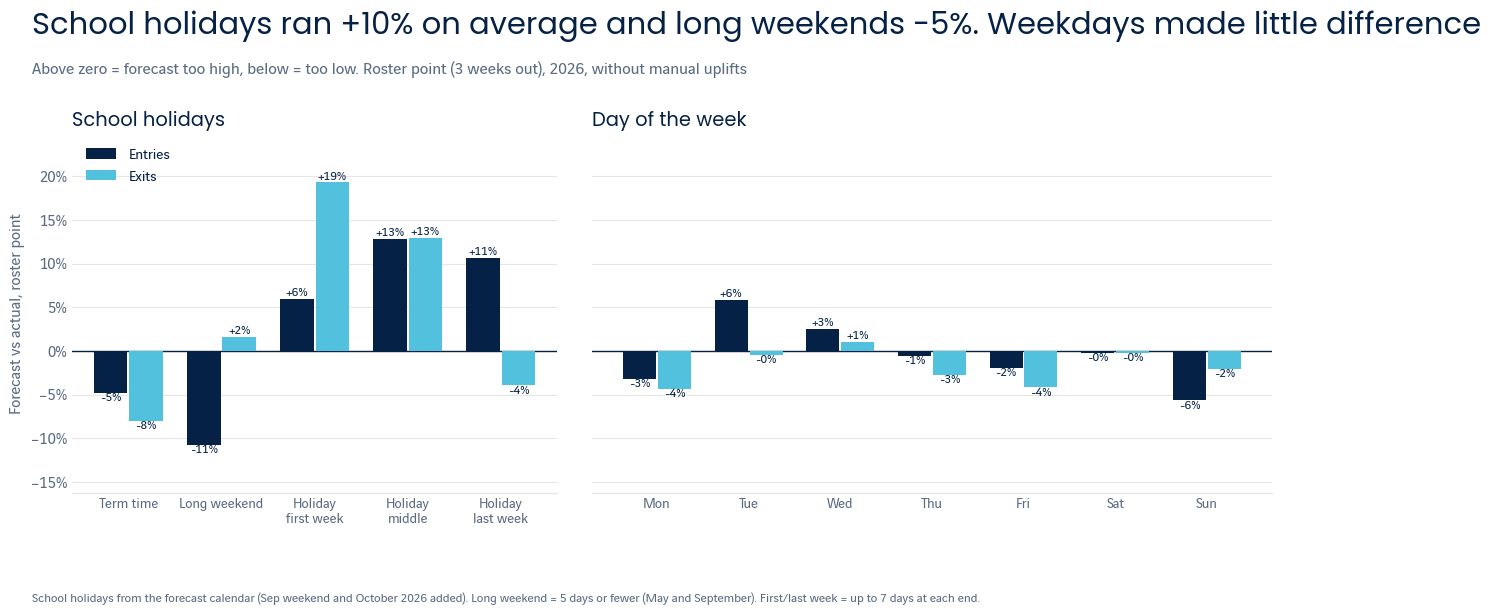

In [36]:
# -----------------------------------------------------------------------------
# Chart 21: school holidays and weekdays at the roster point
# -----------------------------------------------------------------------------
FLOW_COLOUR = {"entries": DARK_BLUE, "exits": LIGHT_BLUE}
fig, axes = plt.subplots(1, 2, figsize=SLIDE, sharey=True, gridspec_kw={"width_ratios": [5, 7]})
fig.subplots_adjust(top=0.76, bottom=0.20, left=0.07, right=0.97, wspace=0.06)

def flow_bars(ax, df, labels, title):
    x = np.arange(len(df))
    for k, flow in enumerate(["entries", "exits"]):
        vals = df[flow].values
        xs = x + (k - 0.5) * 0.38
        ax.bar(xs, vals, width=0.36, color=FLOW_COLOUR[flow], label=flow.capitalize(), zorder=3)
        for xi, v in zip(xs, vals):
            if not np.isnan(v):
                ax.text(xi, v, f"{v:+.0%}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9.5, color=DARK_BLUE)
    ax.axhline(0, color=DARK_BLUE, lw=1)
    ax.set_xticks(x, labels, fontsize=10.5)
    ax.set_title(title, fontsize=14, fontfamily=HEAD_FONT, color=DARK_BLUE, loc="left")

flow_bars(axes[0], hol_bias, [t.replace("Holiday: ", "Holiday\n") for t in DAY_TYPES], "School holidays")
flow_bars(axes[1], wd_bias, [d[:3] for d in WEEKDAYS], "Day of the week")
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Forecast vs actual, roster point")
axes[0].legend(loc="upper left", fontsize=11)
lo, hi = axes[0].get_ylim(); pad = (hi - lo) * 0.12
axes[0].set_ylim(lo - pad, hi + pad)

hol_mid = hol_bias.loc[["Holiday: first week", "Holiday: middle", "Holiday: last week"], ["entries", "exits"]].mean().mean()
lw = hol_bias.loc["Long weekend", ["entries", "exits"]].mean()
headline(fig, f"School holidays ran {hol_mid:+.0%} on average and long weekends {lw:+.0%}. Weekdays made little difference",
         "Above zero = forecast too high, below = too low. Roster point (3 weeks out), 2026, without manual uplifts")
footnote(fig, "School holidays from the forecast calendar (Sep weekend and October 2026 added). Long weekend = 5 days or fewer (May and September). First/last week = up to 7 days at each end.")
plt.show()

In [37]:
# -----------------------------------------------------------------------------
# Public holidays and special events (from the forecast calendar, MANUAL_CALENDAR_PERIODS)
# -----------------------------------------------------------------------------
EVENTS = {
    "Public holiday weekends": [("2025-05-03", "2025-05-05"), ("2025-05-24", "2025-05-26"), ("2025-08-02", "2025-08-04"),
                                ("2026-05-02", "2026-05-04"), ("2026-05-23", "2026-05-25"), ("2026-08-01", "2026-08-03"),
                                ("2026-09-19", "2026-09-21")],
    "Royal Highland Show": [("2025-06-19", "2025-06-22"), ("2026-06-18", "2026-06-21")],
    "Summer Sessions": [("2025-08-22", "2025-08-26"), ("2026-08-21", "2026-08-29")],
    "Edinburgh Festival": [("2025-08-01", "2025-08-25"), ("2026-08-07", "2026-08-30")],
}

def in_event(dates, ranges):
    mask = pd.Series(False, index=dates.index)
    for a, b in ranges:
        mask |= dates.between(pd.Timestamp(a), pd.Timestamp(b))
    return mask

rows = []
for name, ranges in EVENTS.items():
    for yr, df, prefix in [(2026, roster_fu, "std_"), (2025, fa25[fa25["weeks_out"] == ROSTER_W], "fc_")]:
        sub = df[in_event(df["Date"], ranges)]
        if sub["Date"].nunique() == 0:
            continue
        b = flow_bias(sub.assign(all="all"), "all", prefix).iloc[0]
        rows.append({"event": name, "year": yr, "entries": b["entries"], "exits": b["exits"], "days": int(b["days"])})
event_bias = pd.DataFrame(rows).set_index(["event", "year"])
print("Forecast vs actual at the roster point (2026 without manual uplifts; 2025 as issued)")
display(event_bias.assign(entries=lambda d: (d["entries"] * 100).round(1), exits=lambda d: (d["exits"] * 100).round(1)))

Forecast vs actual at the roster point (2026 without manual uplifts; 2025 as issued)


entries  exits  days
event                   year                      
Public holiday weekends 2026    -12.2   -4.0    12
                        2025      6.6    3.1     3
Royal Highland Show     2026     54.3   29.4     4
Summer Sessions         2026    -24.1  -18.3     9
                        2025     -3.0   -3.8     5
Edinburgh Festival      2026    -15.4  -11.2    23
                        2025      0.8    2.4    20

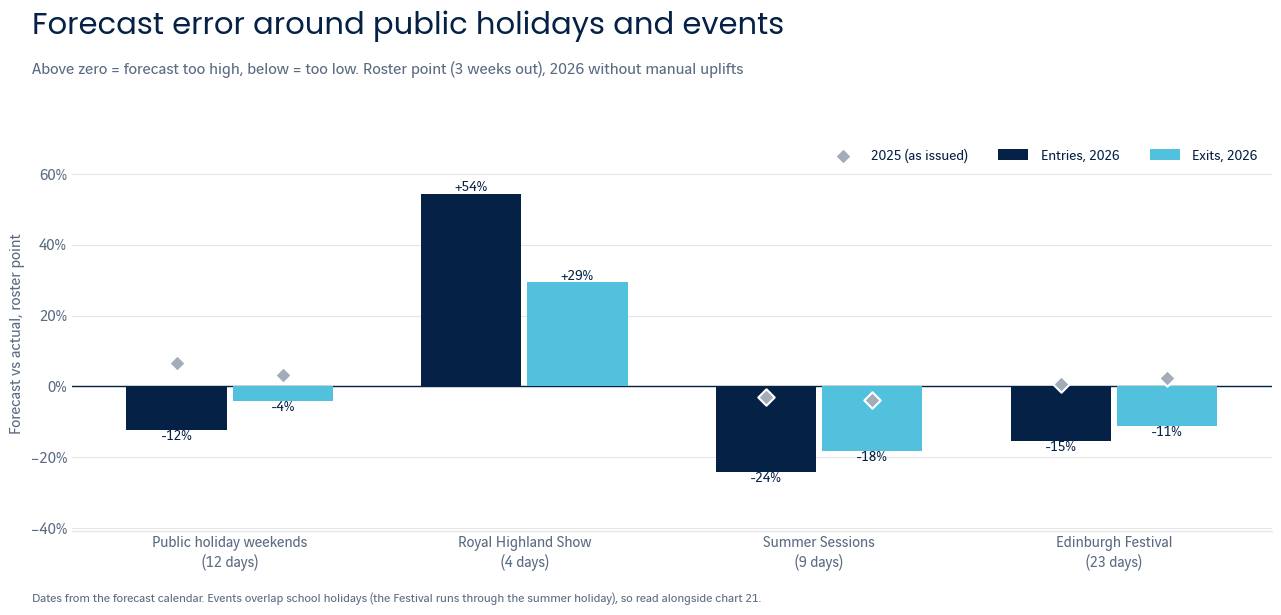

In [38]:
# -----------------------------------------------------------------------------
# Chart 22: public holidays and special events at the roster point, 2026
# -----------------------------------------------------------------------------
ev = event_bias.xs(2026, level="year").reindex(list(EVENTS)).dropna(how="all")
ev25 = event_bias.xs(2025, level="year").reindex(ev.index) if 2025 in event_bias.index.get_level_values("year") else None

fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.07, right=0.97)
x = np.arange(len(ev))
for k, flow in enumerate(["entries", "exits"]):
    vals = ev[flow].values
    xs = x + (k - 0.5) * 0.36
    ax.bar(xs, vals, width=0.34, color=FLOW_COLOUR[flow], label=f"{flow.capitalize()}, 2026", zorder=3)
    for xi, v in zip(xs, vals):
        ax.text(xi, v, f"{v:+.0%}", ha="center", va="bottom" if v >= 0 else "top", fontsize=11, color=DARK_BLUE)
    if ev25 is not None:
        ax.scatter(xs, ev25[flow].values, marker="D", s=70, color=LY_GREY, edgecolor="white", linewidth=1.5, zorder=4,
                   label="2025 (as issued)" if k == 0 else None)
ax.axhline(0, color=DARK_BLUE, lw=1)
ax.set_xticks(x, [f"{n}\n({int(ev.loc[n, 'days'])} days)" for n in ev.index], fontsize=11.5)
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel("Forecast vs actual, roster point")
lo, hi = ax.get_ylim(); pad = (hi - lo) * 0.15
ax.set_ylim(lo - pad, hi + pad)
ax.legend(loc="upper right", fontsize=11, ncol=3)

headline(fig, "Forecast error around public holidays and events",
         "Above zero = forecast too high, below = too low. Roster point (3 weeks out), 2026 without manual uplifts")
footnote(fig, "Dates from the forecast calendar. Events overlap school holidays (the Festival runs through the summer holiday), so read alongside chart 21.")
plt.show()

In [39]:
# -----------------------------------------------------------------------------
# Which factors line up with the roster-point error?  (weekly correlations, forecast without manual uplifts)
# -----------------------------------------------------------------------------
wk_vol = ab.groupby(["week", "group", "year"]).size().unstack(["group", "year"])
wk_all = ab.groupby(["week", "year"]).size().unstack("year")
wk_late = pr[pr["lead"] <= 7].groupby(["week", "group", "year"])["price_idx"].median().unstack(["group", "year"])

hol_days = {y: pd.Series([day_type(d) != "Term time" for d in pd.date_range(s, e)],
                         index=pd.date_range(s, e)).groupby(lambda d: d.isocalendar()[1]).sum()
            for y, (s, e) in {2025: (LY_START, LY_END), 2026: (START, END)}.items()}

factors = pd.DataFrame({
    "FastPark late price vs 2025": wk_late[("FastPark", 2026)] - wk_late[("FastPark", 2025)],
    "Other car parks' late price vs 2025": wk_late[("Other car parks", 2026)] - wk_late[("Other car parks", 2025)],
    "FastPark late price vs other car parks, change on 2025":
        (wk_late[("FastPark", 2026)] - wk_late[("Other car parks", 2026)])
        - (wk_late[("FastPark", 2025)] - wk_late[("Other car parks", 2025)]),
    "All car park bookings vs 2025": wk_all[2026] / wk_all[2025] - 1,
    "Other car park bookings vs 2025": wk_vol[("Other car parks", 2026)] / wk_vol[("Other car parks", 2025)] - 1,
    "FastPark share of bookings vs 2025": wk_vol[("FastPark", 2026)] / wk_all[2026] - wk_vol[("FastPark", 2025)] / wk_all[2025],
    "School holiday days in the week vs 2025": hol_days[2026].reindex(wk_all.index).fillna(0)
                                               - hol_days[2025].reindex(wk_all.index).fillna(0),
})

factor_r = {}
for w in [6, ROSTER_W]:
    d = price_link[price_link["weeks_out"] == w].set_index("week")["bias_no_uplift"]
    j = factors.join(d.rename("error"), how="inner")
    factor_r[w] = j.drop(columns="error").corrwith(j["error"])
factor_r = pd.DataFrame({f"{w} weeks out": s for w, s in factor_r.items()})
factor_r = factor_r.reindex(factor_r[f"{ROSTER_W} weeks out"].abs().sort_values(ascending=False).index)
print(f"Correlation with forecast error (forecast/actual - 1, no manual uplift), {len(j)} arrival weeks")
display(factor_r.round(2))

Correlation with forecast error (forecast/actual - 1, no manual uplift), 30 arrival weeks


,6 weeks out,3 weeks out
"FastPark late price vs other car parks, change on 2025",0.76,0.78
FastPark late price vs 2025,0.79,0.75
FastPark share of bookings vs 2025,-0.76,-0.71
All car park bookings vs 2025,-0.47,-0.22
Other car park bookings vs 2025,0.02,0.22
Other car parks' late price vs 2025,0.29,0.13
School holiday days in the week vs 2025,0.13,0.09


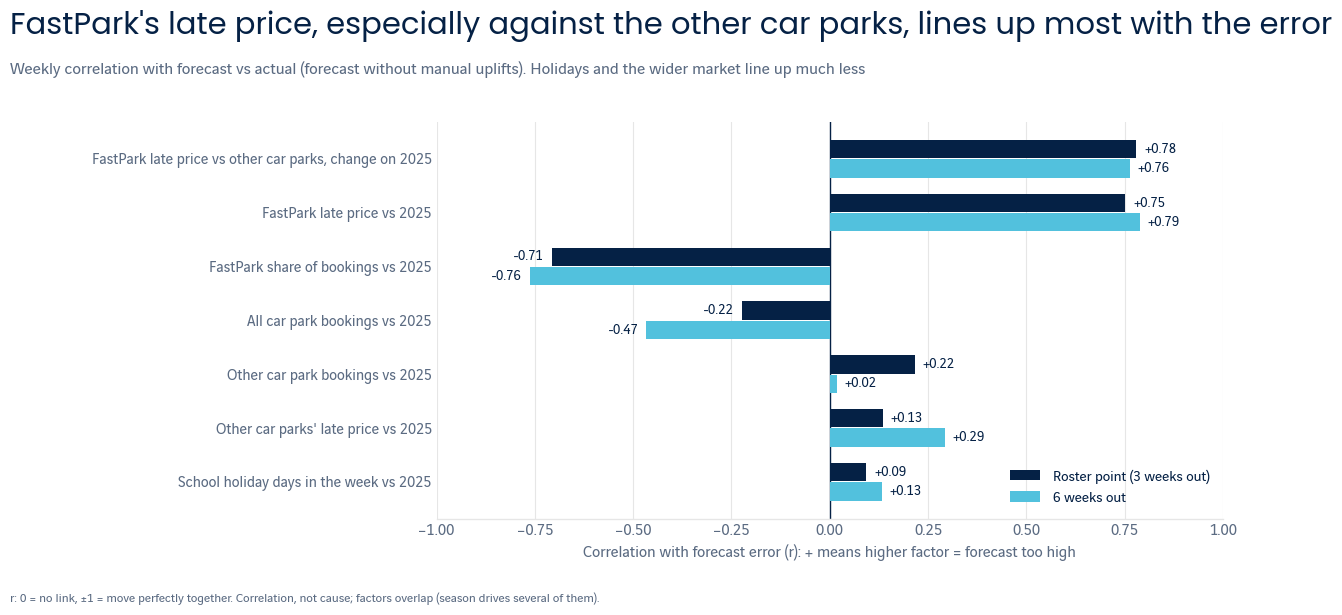

In [40]:
# -----------------------------------------------------------------------------
# Chart 19: what lines up with the forecast error?
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(top=0.78, bottom=0.16, left=0.36, right=0.95)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
names = factor_r.index.tolist()[::-1]
y = np.arange(len(names))
for k, (col, colour) in enumerate([(f"{ROSTER_W} weeks out", DARK_BLUE), ("6 weeks out", LIGHT_BLUE)]):
    vals = factor_r[col].reindex(names).values
    ys = y + (0.5 - k) * 0.36
    ax.barh(ys, vals, height=0.34, color=colour, zorder=3, label=f"Roster point ({ROSTER_W} weeks out)" if k == 0 else col)
    for yi, v in zip(ys, vals):
        ax.text(v + (0.02 if v >= 0 else -0.02), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
                fontsize=10.5, color=DARK_BLUE)
ax.axvline(0, color=DARK_BLUE, lw=1)
ax.set_yticks(y, names, fontsize=11.5)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlation with forecast error (r): + means higher factor = forecast too high")
ax.legend(loc="lower right", fontsize=11)

top = factor_r.index[0]
headline(fig, "FastPark's late price, especially against the other car parks, lines up most with the error",
         "Weekly correlation with forecast vs actual (forecast without manual uplifts). Holidays and the wider market line up much less")
footnote(fig, "r: 0 = no link, ±1 = move perfectly together. Correlation, not cause; factors overlap (season drives several of them).")
plt.show()

## 10. Wash-up visuals

The two visuals for the wash-up, answering the three questions for an ops audience. 1 April to 24 October 2026.

| Question | Visual |
|---|---|
| 1. How accurate was the forecast, from the first forecast to 1 week out, by month? | **Visual 1**: accuracy at each week before arrival, one line per month (June, September and October highlighted) |
| 2. What drove the inaccuracy? 3. June vs September and October | **Visual 2**: June, September and October side by side: how the forecast did, and what customers did differently from 2025 |
| 2. What drove the inaccuracy? (by forecast method) | **Visual 4**: as Visual 2, but each fact sits against the part of the forecast it affects: FastPark's share of demand (more than 2 weeks out) and bookings on the books (last 2 weeks) |
| 2. What drove the inaccuracy? (booking timing) | **Visual 5**: share of bookings already made 1 to 14 days before arrival: what the forecast assumes, 2025 and 2026, by month |
| 2. What drove the inaccuracy? (August uplift change) | **Visual 6**: what the 11 August change to the daily booking uplift did to the August forecast, entries and exits |
| 2. What drove the inaccuracy? (exits) | **Visual 7**: in the last 2 weeks, bookings x the standard daily uplift against actual, entries and exits, by month |
| 2. What drove the inaccuracy? (exits by stay length) | **Visual 8**: why exits still had bookings to come at 14 days out: short stays, and more of them in 2026 |
| 1. Accuracy by month (grid) | **Visual 9**: accuracy and direction for each month at each week out (no FTE, no highlighted weeks). Set `SHOW_R1 = True` to add the R1 column |
| Overview | **Visual 3**: each month's actual total against R1 and the forecast made 6, 3 and 1 week before |

Accuracy uses entries and exits together, forecasts as issued. Visual 2 states facts side by side; it does not say one caused another.
Set `SHOW_R1 = False` in Visual 2 to remove the R1 row.

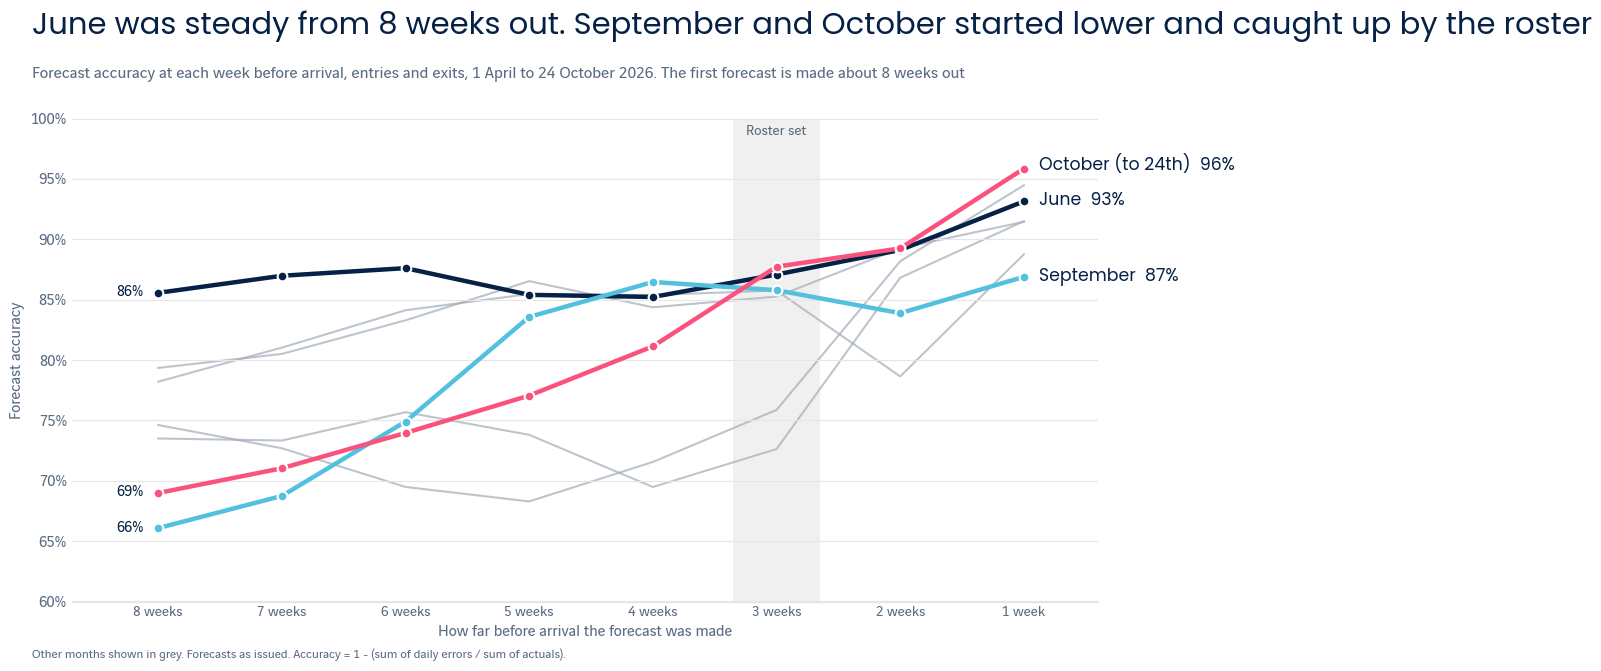

In [41]:
# -----------------------------------------------------------------------------
# Visual 1: forecast accuracy from 8 weeks out to 1 week out, by month
# -----------------------------------------------------------------------------
HZ = list(range(8, 0, -1))
fc_period = fa[fa["Date"].between(R1_START, R1_END)].assign(m=lambda d: d["Date"].dt.month, all=1)
v_acc, v_bias = {}, {}
for w in HZ:
    d = fc_period[fc_period["weeks_out"] == w]
    s = pd.concat([score_fc(d, "fc_entries", "fc_exits", "m"),
                   score_fc(d, "fc_entries", "fc_exits", "all").rename(index={1: "All"})])
    v_acc[w], v_bias[w] = s["accuracy"], s["bias"]
v_acc, v_bias = pd.DataFrame(v_acc), pd.DataFrame(v_bias)

fig, ax = plt.subplots(figsize=(13.33, 7.0))
fig.subplots_adjust(top=0.80, bottom=0.11, left=0.07, right=0.84)
xh = np.arange(len(HZ))
rx = HZ.index(R1_ROSTER)
ax.axvspan(rx - 0.35, rx + 0.35, color=GREY, alpha=0.6, lw=0, zorder=0)
ax.text(rx, 0.995, "Roster set", ha="center", va="top", fontsize=11, color=MUTED)

for m in R1_MONTHS:                                   # other months, faint
    if m in FOCUS:
        continue
    ax.plot(xh, v_acc.loc[m, HZ].values, color=LY_GREY, lw=1.5, alpha=0.7, zorder=1)
label_y = {}
for m in FOCUS:                                       # June, September, October
    vals = v_acc.loc[m, HZ].values
    ax.plot(xh, vals, color=FOCUS_COLOUR[m], lw=3.2, marker="o", ms=7, mec="white", mew=1.5, zorder=3)
    ax.text(xh[0] - 0.12, vals[0], f"{vals[0]:.0%}", ha="right", va="center", fontsize=11.5, color=DARK_BLUE)
    label_y[m] = vals[-1]
# right-hand labels, nudged apart so they don't overlap
order = sorted(label_y, key=label_y.get)
for k in range(1, len(order)):
    if label_y[order[k]] - label_y[order[k - 1]] < 0.03:
        label_y[order[k]] = label_y[order[k - 1]] + 0.03
for m, y in label_y.items():
    name = MONTH_LONG[m] + (" (to 24th)" if m == 10 else "")
    ax.text(xh[-1] + 0.12, y, f"{name}  {v_acc.loc[m, HZ[-1]]:.0%}", fontsize=12.5, fontfamily=HEAD_FONT,
            color=DARK_BLUE, va="center")

ax.set_xticks(xh, [f"{w} weeks" if w > 1 else "1 week" for w in HZ], fontsize=11)
ax.set_xlabel("How far before arrival the forecast was made")
ax.set_ylim(0.6, 1.0)
ax.set_xlim(-0.7, len(HZ) - 0.4)
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel("Forecast accuracy")

june8, sep8, oct8 = v_acc.loc[6, 8], v_acc.loc[9, 8], v_acc.loc[10, 8]
headline(fig, f"June was steady from 8 weeks out. September and October started lower and caught up by the roster",
         "Forecast accuracy at each week before arrival, entries and exits, 1 April to 24 October 2026. "
         "The first forecast is made about 8 weeks out")
footnote(fig, "Other months shown in grey. Forecasts as issued. Accuracy = 1 - (sum of daily errors / sum of actuals).")
plt.show()

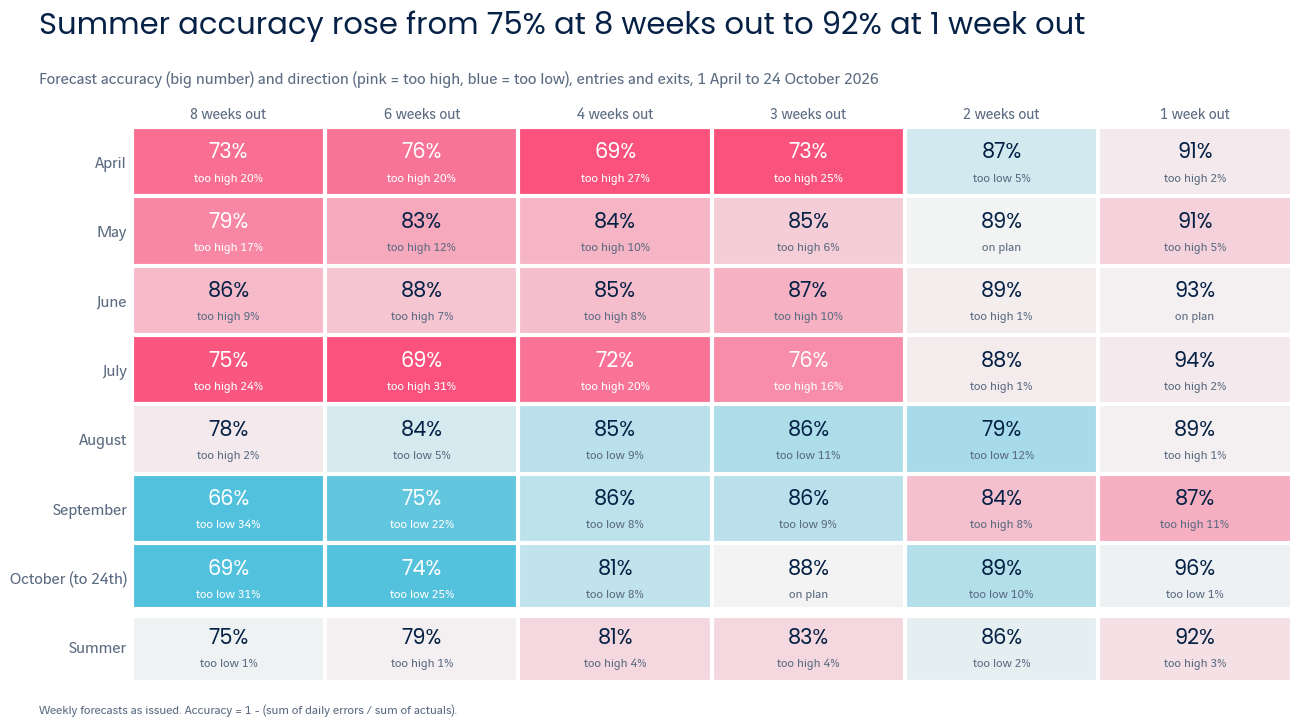

In [42]:
# -----------------------------------------------------------------------------
# Visual 9: month-by-month accuracy grid (weekly forecast; R1 column optional)
#   Same figures as Chart 23, without the staffing column or the roster highlight
# -----------------------------------------------------------------------------
SHOW_R1 = False          # set to True to add an R1 (budget) column

cols = (["R1"] if SHOW_R1 else []) + [f"{w}w" for w in R1_WEEKS]
col_labels = (["R1 (budget)"] if SHOW_R1 else []) + [f"{w} week{'s' if w > 1 else ''} out" for w in R1_WEEKS]
rows = R1_MONTHS + ["Summer"]
g_bias, g_acc = v1_bias.loc[rows, cols], v1_acc.loc[rows, cols]

over_under = LinearSegmentedColormap.from_list("over_under", [LIGHT_BLUE, "#F4F4F4", PINK])
lim = 0.25
fig, ax = plt.subplots(figsize=(13.33, 7.6))
fig.subplots_adjust(top=0.80, bottom=0.07, left=0.11, right=0.98)
ax.grid(False)
ax.imshow(g_bias.values.astype(float), cmap=over_under, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_xticks(np.arange(-0.5, len(cols)), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", length=0)
ax.axhline(len(R1_MONTHS) - 0.5, color="white", lw=8)
for i, r in enumerate(rows):
    for j, c in enumerate(cols):
        b, a = g_bias.loc[r, c], g_acc.loc[r, c]
        if pd.isna(b):
            continue
        strong = abs(b) / lim > 0.6
        ax.text(j, i - 0.13, f"{a:.0%}", ha="center", va="center", fontsize=15, fontfamily=HEAD_FONT,
                color="white" if strong else DARK_BLUE)
        word = "on plan" if abs(b) < 0.005 else ("too high" if b > 0 else "too low")
        ax.text(j, i + 0.24, word if word == "on plan" else f"{word} {abs(b):.0%}", ha="center", va="center",
                fontsize=9.5, color="white" if strong else MUTED)
ax.set_xticks(range(len(cols)), col_labels, fontsize=11.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(rows)), [MONTH_LONG.get(r, r) + (" (to 24th)" if r == 10 else "") for r in rows], fontsize=12.5)
for sp in ax.spines.values():
    sp.set_visible(False)

s = v1_acc.loc["Summer"]
headline(fig, f"Summer accuracy rose from {s['8w']:.0%} at 8 weeks out to {s['1w']:.0%} at 1 week out",
         "Forecast accuracy (big number) and direction (pink = too high, blue = too low), entries and exits, "
         "1 April to 24 October 2026")
footnote(fig, "Weekly forecasts as issued. Accuracy = 1 - (sum of daily errors / sum of actuals).")
plt.show()

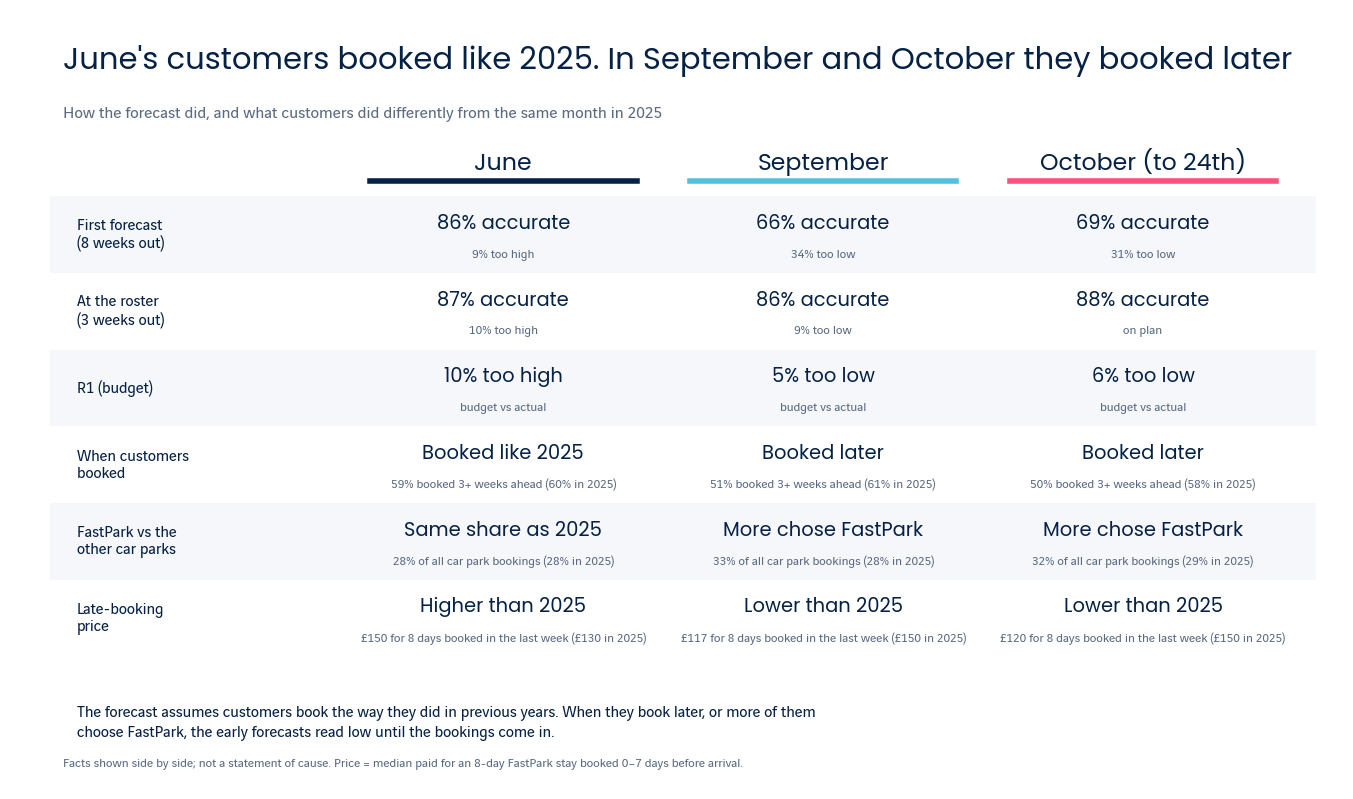

In [43]:
# -----------------------------------------------------------------------------
# Visual 2: June vs September vs October - how the forecast did, and what customers did differently from 2025
# -----------------------------------------------------------------------------
SHOW_R1 = True          # set to False to remove the R1 row

def acc_text(m, w):
    a, b = v_acc.loc[m, w], v_bias.loc[m, w]
    direction = "on plan" if abs(b) < 0.005 else f"{abs(b):.0%} too {'high' if b > 0 else 'low'}"
    return f"{a:.0%} accurate", direction

def timing_text(m):
    now, before = curves[(2026, m)][21], curves[(2025, m)][21]
    v = (now - before) * 100
    big = "Booked like 2025" if abs(v) < 1 else ("Booked earlier" if v > 0 else "Booked later")
    return big, f"{now:.0%} booked 3+ weeks ahead ({before:.0%} in 2025)"

def share_text(m):
    now, before = fp_share_m.loc[m, 2026], fp_share_m.loc[m, 2025]
    v = (now - before) * 100
    big = "Same share as 2025" if abs(v) < 0.5 else ("More chose FastPark" if v > 0 else "Fewer chose FastPark")
    return big, f"{now:.0%} of all car park bookings ({before:.0%} in 2025)"

# Typical price paid for an 8-day stay (the most common length) booked in the final week before arrival
late_8day = (priced[(priced["lead"] <= 7) & (priced["duration"] == 8)]
             .groupby(["month", "year"])["price"].median().unstack("year"))

def price_text(m):
    before, now = late_8day.loc[m, 2025], late_8day.loc[m, 2026]
    big = "Similar to 2025" if abs(now / before - 1) < 0.03 else ("Higher than 2025" if now > before else "Lower than 2025")
    return big, f"£{now:.0f} for 8 days booked in the last week (£{before:.0f} in 2025)"

def r1_text(m):
    b = v1_bias.loc[m, "R1"]
    return ("On plan" if abs(b) < 0.005 else f"{abs(b):.0%} too {'high' if b > 0 else 'low'}"), "budget vs actual"

rows = [("First forecast\n(8 weeks out)", lambda m: acc_text(m, 8)),
        ("At the roster\n(3 weeks out)", lambda m: acc_text(m, R1_ROSTER))]
if SHOW_R1:
    rows.append(("R1 (budget)", r1_text))
rows += [("When customers\nbooked", timing_text),
         ("FastPark vs the\nother car parks", share_text),
         ("Late-booking\nprice", price_text)]

fig = plt.figure(figsize=(13.33, 7.8))
fig.add_axes([0, 0, 1, 1]).axis("off")   # gives the figure an axes so it displays inline
headline(fig, "June's customers booked like 2025. In September and October they booked later",
         "How the forecast did, and what customers did differently from the same month in 2025")
col_x = [0.37, 0.61, 0.85]
top, bottom = 0.76, 0.17
row_h = (top - bottom) / len(rows)
for cx, m in zip(col_x, FOCUS):
    name = MONTH_LONG[m] + (" (to 24th)" if m == 10 else "")
    fig.text(cx, top + 0.035, name, ha="center", fontsize=17, fontfamily=HEAD_FONT, color=DARK_BLUE)
    fig.add_artist(plt.Line2D([cx - 0.1, cx + 0.1], [top + 0.02, top + 0.02], color=FOCUS_COLOUR[m], lw=4,
                              transform=fig.transFigure))
for r, (label, fn) in enumerate(rows):
    yc = top - (r + 0.5) * row_h
    if r % 2 == 0:
        fig.add_artist(plt.Rectangle((0.03, yc - row_h / 2), 0.95, row_h, transform=fig.transFigure,
                                     color="#F5F7FA", lw=0, zorder=0))
    fig.text(0.05, yc, label, ha="left", va="center", fontsize=12, color=DARK_BLUE, linespacing=1.2)
    for cx, m in zip(col_x, FOCUS):
        big, small = fn(m)
        fig.text(cx, yc + 0.015, big, ha="center", va="center", fontsize=14, fontfamily=HEAD_FONT, color=DARK_BLUE)
        fig.text(cx, yc - 0.025, small, ha="center", va="center", fontsize=9.5, color=MUTED)

fig.text(0.05, 0.085, "The forecast assumes customers book the way they did in previous years. When they book later, or more of them\n"
                      "choose FastPark, the early forecasts read low until the bookings come in.",
         ha="left", va="center", fontsize=12, color=DARK_BLUE, linespacing=1.4)
footnote(fig, "Facts shown side by side; not a statement of cause. Price = median paid for an 8-day FastPark stay "
              "booked 0–7 days before arrival.")
plt.show()

,April,May,June,July,August,September,October
days used,30,31,30,31,31,30,24
days in period,30,31,30,31,31,30,24


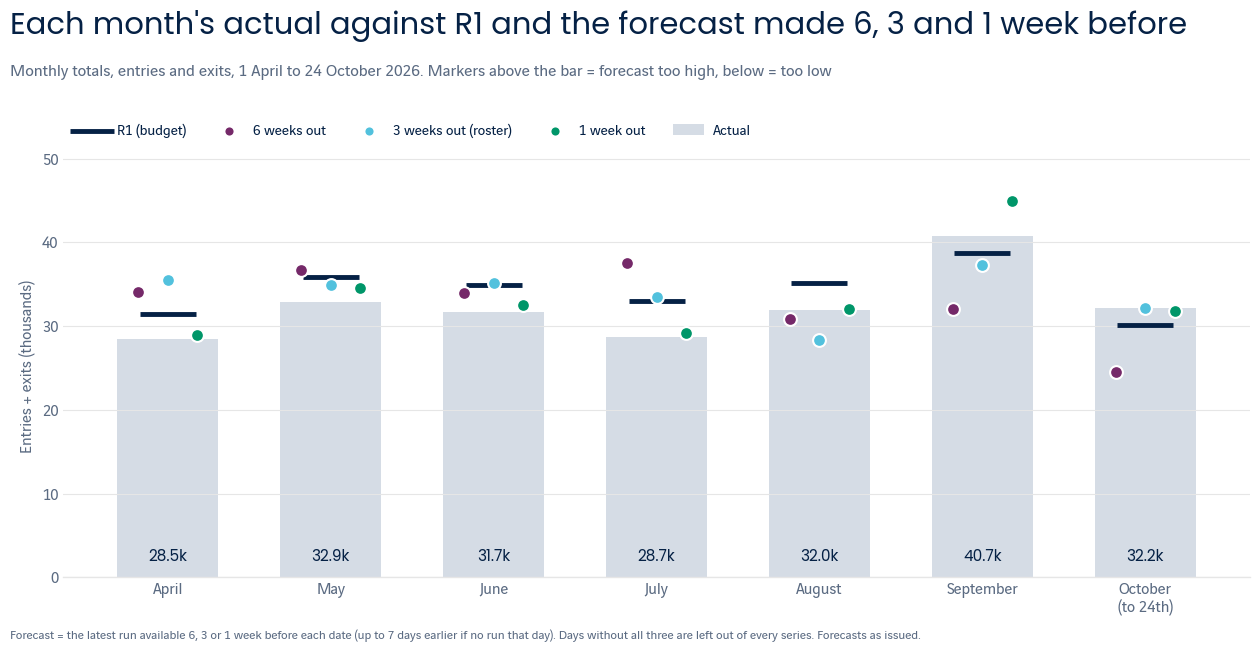

In [44]:
# -----------------------------------------------------------------------------
# Visual 3: monthly totals - actual vs R1 vs the forecast made 6, 3 and 1 week out
# -----------------------------------------------------------------------------
V3_WEEKS = [6, 3, 1]
V3_TOLERANCE_DAYS = 7      # if no run exactly N weeks before, use the latest run up to 7 days earlier (what we had at the time)
t3 = pd.DataFrame([(d, w, d - pd.Timedelta(days=7 * w)) for d in pd.date_range(R1_START, R1_END) for w in V3_WEEKS],
                  columns=["Date", "weeks_out", "cutoff"]).sort_values("cutoff")
t3 = pd.merge_asof(t3, pd.DataFrame({"run": sorted(runs)}), left_on="cutoff", right_on="run",
                   direction="backward", tolerance=pd.Timedelta(days=V3_TOLERANCE_DAYS))
wide = (t3.dropna(subset=["run"]).merge(forecasts, on=["run", "Date"])
        .assign(fc=lambda d: d["fc_entries"] + d["fc_exits"])
        .pivot_table(index="Date", columns="weeks_out", values="fc"))
wide = wide.dropna()                                   # same days for every series
daily = (wide.join(r1.assign(r1=lambda d: d["r1_entries"] + d["r1_exits"])["r1"])
             .join(actuals.assign(act=lambda d: d["act_entries"] + d["act_exits"])["act"]))
monthly = daily.groupby(daily.index.month).sum()
days_used = daily.groupby(daily.index.month).size()
days_in = pd.Series(pd.date_range(R1_START, R1_END)).groupby(lambda i: pd.date_range(R1_START, R1_END)[i].month).size()
display(pd.DataFrame({"days used": days_used, "days in period": days_in}).rename(index=MONTH_LONG).T)

SERIES = [("r1", "R1 (budget)", DARK_BLUE, "_"),
          (6, "6 weeks out", PURPLE, "o"),
          (3, "3 weeks out (roster)", LIGHT_BLUE, "o"),
          (1, "1 week out", GREEN, "o")]
fig, ax = plt.subplots(figsize=(13.33, 6.8))
fig.subplots_adjust(top=0.74, bottom=0.12, left=0.08, right=0.97)
xm = np.arange(len(R1_MONTHS))
ax.bar(xm, monthly.loc[R1_MONTHS, "act"] / 1000, width=0.62, color="#D5DCE5", zorder=1, label="Actual")
for xi, m in zip(xm, R1_MONTHS):
    ax.text(xi, 1.5, f"{monthly.loc[m, 'act'] / 1000:.1f}k", ha="center", va="bottom", fontsize=11,
            fontfamily=HEAD_FONT, color=DARK_BLUE, zorder=2)
offsets = {"r1": 0, 6: -0.18, 3: 0, 1: 0.18}
for key, label, colour, marker in SERIES:
    vals = monthly.loc[R1_MONTHS, key] / 1000
    if marker == "_":
        ax.scatter(xm, vals, marker="_", s=1600, linewidths=3.5, color=colour, zorder=3, label=label)
    else:
        ax.scatter(xm + offsets[key], vals, s=85, color=colour, edgecolor="white", linewidth=1.5, zorder=4, label=label)
ax.set_xticks(xm, [MONTH_LONG[m] + ("\n(to 24th)" if m == 10 else "") for m in R1_MONTHS], fontsize=12)
ax.set_ylabel("Entries + exits (thousands)")
ax.set_ylim(0, (monthly.loc[R1_MONTHS, ["act", "r1", 6, 3, 1]].max().max() / 1000) * 1.12)
ax.legend(loc="lower left", ncol=5, fontsize=11, bbox_to_anchor=(0, 1.01), handletextpad=0.6, columnspacing=1.8, markerscale=0.8)

headline(fig, "Each month's actual against R1 and the forecast made 6, 3 and 1 week before",
         "Monthly totals, entries and exits, 1 April to 24 October 2026. Markers above the bar = forecast too high, below = too low")
footnote(fig, "Forecast = the latest run available 6, 3 or 1 week before each date (up to 7 days earlier if no run that day). Days without all three are left out of every series. Forecasts as issued.")
plt.show()

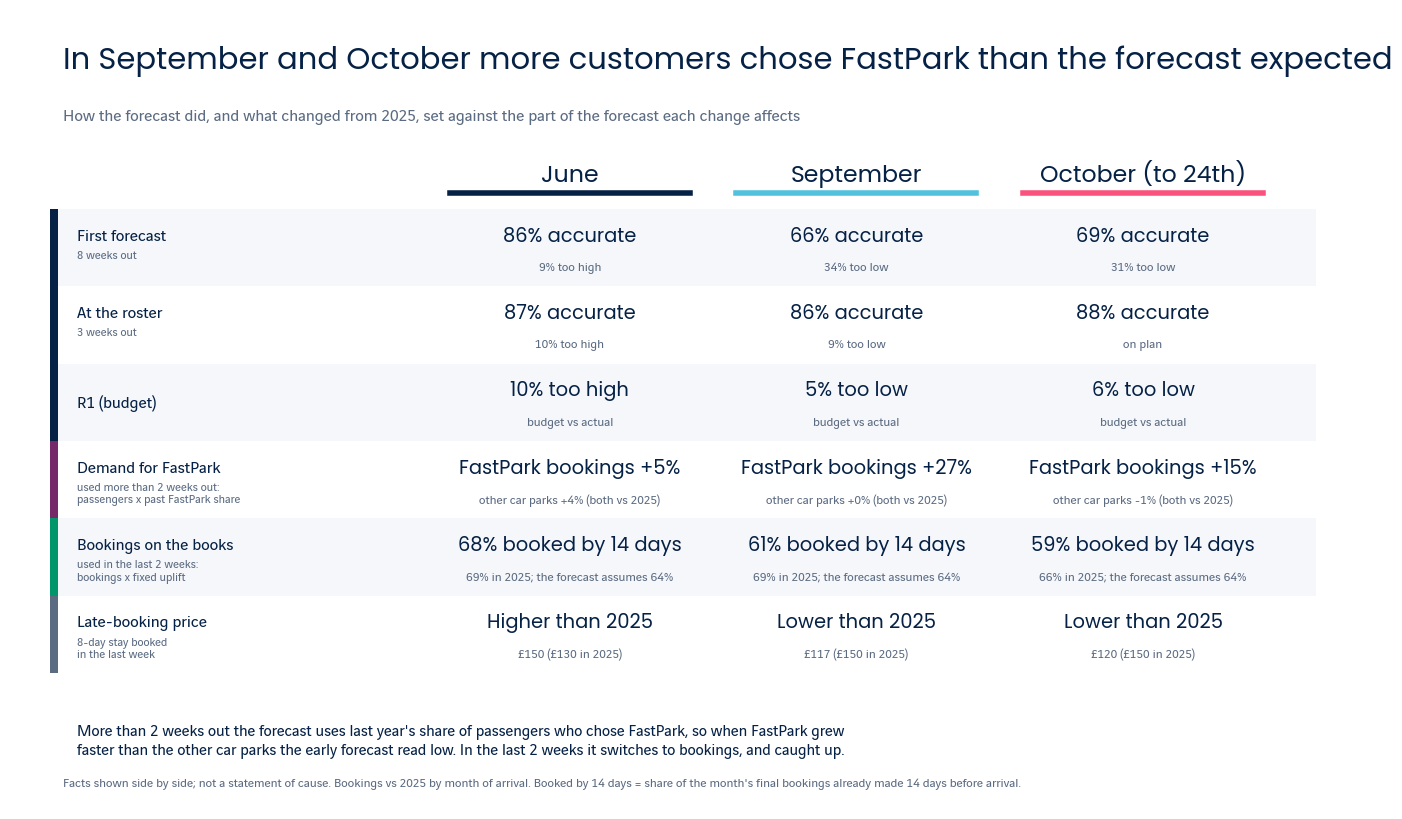

In [45]:
# -----------------------------------------------------------------------------
# Visual 4: June vs September vs October, each fact against the part of the forecast it affects
#   More than 14 days out: passengers x FastPark penetration  -> FastPark's share of demand matters
#   Last 14 days: bookings on the books x booking uplift      -> booking timing matters
# -----------------------------------------------------------------------------
UPLIFT_ASSUMED_14D = 1 / 1.56          # entries list: +56% at 14 days out = 64% assumed on the books

def demand_text(m):
    fp, other = vol_chg_m.loc[m, "FastPark"], vol_chg_m.loc[m, "Other car parks"]
    other = round(other, 2) + 0.0                     # avoid "-0%"
    return f"FastPark bookings {fp:+.0%}", f"other car parks {other:+.0%} (both vs 2025)"

def price_text4(m):
    now, before = late_8day.loc[m, 2026], late_8day.loc[m, 2025]
    big = "Similar to 2025" if abs(now - before) < 5 else ("Higher than 2025" if now > before else "Lower than 2025")
    return big, f"£{now:.0f} (£{before:.0f} in 2025)"

def onbooks_text(m):
    now, before = curves[(2026, m)][14], curves[(2025, m)][14]
    return f"{now:.0%} booked by 14 days", f"{before:.0%} in 2025; the forecast assumes {UPLIFT_ASSUMED_14D:.0%}"

rows4 = [
    ("Forecast", "First forecast", "8 weeks out", lambda m: acc_text(m, 8)),
    ("Forecast", "At the roster", "3 weeks out", lambda m: acc_text(m, R1_ROSTER)),
    ("Forecast", "R1 (budget)", "", r1_text),
    ("More than 2 weeks out", "Demand for FastPark", "used more than 2 weeks out:\npassengers x past FastPark share", demand_text),
    ("Last 2 weeks", "Bookings on the books", "used in the last 2 weeks:\nbookings x fixed uplift", onbooks_text),
    ("Context", "Late-booking price", "8-day stay booked\nin the last week", price_text4),
]

fig = plt.figure(figsize=(13.33, 8.0))
fig.add_axes([0, 0, 1, 1]).axis("off")
headline(fig, "In September and October more customers chose FastPark than the forecast expected",
         "How the forecast did, and what changed from 2025, set against the part of the forecast each change affects")
col_x = [0.42, 0.635, 0.85]
top, bottom = 0.75, 0.17
row_h = (top - bottom) / len(rows4)
for cx, m in zip(col_x, FOCUS):
    name = MONTH_LONG[m] + (" (to 24th)" if m == 10 else "")
    fig.text(cx, top + 0.035, name, ha="center", fontsize=17, fontfamily=HEAD_FONT, color=DARK_BLUE)
    fig.add_artist(plt.Line2D([cx - 0.09, cx + 0.09], [top + 0.02, top + 0.02], color=FOCUS_COLOUR[m], lw=4,
                              transform=fig.transFigure))
group_colour = {"Forecast": DARK_BLUE, "More than 2 weeks out": PURPLE, "Last 2 weeks": GREEN, "Context": MUTED}
last_group = None
for r, (group, label, sub, fn) in enumerate(rows4):
    yc = top - (r + 0.5) * row_h
    if r % 2 == 0:
        fig.add_artist(plt.Rectangle((0.03, yc - row_h / 2), 0.95, row_h, transform=fig.transFigure,
                                     color="#F5F7FA", lw=0, zorder=0))
    fig.add_artist(plt.Rectangle((0.03, yc - row_h / 2), 0.006, row_h, transform=fig.transFigure,
                                 color=group_colour[group], lw=0))
    last_group = group
    fig.text(0.05, yc + (0.0 if not sub else 0.005), label, ha="left", va="bottom" if sub else "center",
             fontsize=12.5, color=DARK_BLUE)
    if sub:
        fig.text(0.05, yc - 0.003, sub, ha="left", va="top", fontsize=9, color=MUTED, linespacing=1.15)
    for cx, m in zip(col_x, FOCUS):
        big, small = fn(m)
        fig.text(cx, yc + 0.015, big, ha="center", va="center", fontsize=14, fontfamily=HEAD_FONT, color=DARK_BLUE)
        fig.text(cx, yc - 0.025, small, ha="center", va="center", fontsize=9.5, color=MUTED)

fig.text(0.05, 0.085, "More than 2 weeks out the forecast uses last year's share of passengers who chose FastPark, so when FastPark grew\n"
                      "faster than the other car parks the early forecast read low. In the last 2 weeks it switches to bookings, and caught up.",
         ha="left", va="center", fontsize=12, color=DARK_BLUE, linespacing=1.4)
footnote(fig, "Facts shown side by side; not a statement of cause. Bookings vs 2025 by month of arrival. "
              "Booked by 14 days = share of the month's final bookings already made 14 days before arrival.")
plt.show()

Share of final bookings already made, by days before arrival (%):


days out       1                    2                   3               \
          Assumed   2025  2026 Assumed  2025  2026 Assumed  2025  2026   
month                                                                    
Summer       95.0   98.0  98.0    91.0  92.0  90.0    87.0  87.0  86.0   
April        95.0   97.0  98.0    91.0  84.0  89.0    87.0  77.0  85.0   
May          95.0   98.0  98.0    91.0  90.0  89.0    87.0  86.0  85.0   
June         95.0  100.0  97.0    91.0  98.0  90.0    87.0  93.0  86.0   
July         95.0   99.0  97.0    91.0  97.0  90.0    87.0  92.0  85.0   
August       95.0   98.0  98.0    91.0  91.0  90.0    87.0  87.0  84.0   
September    95.0   99.0  98.0    91.0  91.0  91.0    87.0  87.0  87.0   
October      95.0   99.0  98.0    91.0  93.0  91.0    87.0  88.0  86.0   

days out       4   ...    11      12                  13                  14  \
          Assumed  ...  2026 Assumed  2025  2026 Assumed  2025  2026 Assumed   
month              ...                                                         
Summer       83.0  ...  66.0    67.0  65.0  64.0    65.0  64.0  63.0    64.0   
April        83.0  ...  65.0    67.0  48.0  64.0    65.0  46.0  63.0    64.0   
May          83.0  ...  67.0    67.0  61.0  66.0    65.0  59.0  65.0    64.0   
June         83.0  ...  72.0    67.0  72.0  70.0    65.0  71.0  69.0    64.0   
July         83.0  ...  69.0    67.0  72.0  68.0    65.0  70.0  66.0    64.0   
August       83.0  ...  58.0    67.0  64.0  56.0    65.0  62.0  54.0    64.0   
September    83.0  ...  66.0    67.0  72.0  65.0    65.0  70.0  63.0    64.0   
October      83.0  ...  64.0    67.0  69.0  62.0    65.0  68.0  61.0    64.0   

days out               
           2025  2026  
month                  
Summer     62.0  61.0  
April      45.0  61.0  
May        57.0  63.0  
June       69.0  68.0  
July       69.0  65.0  
August     60.0  52.0  
September  69.0  61.0  
October    66.0  59.0  

[8 rows x 42 columns]

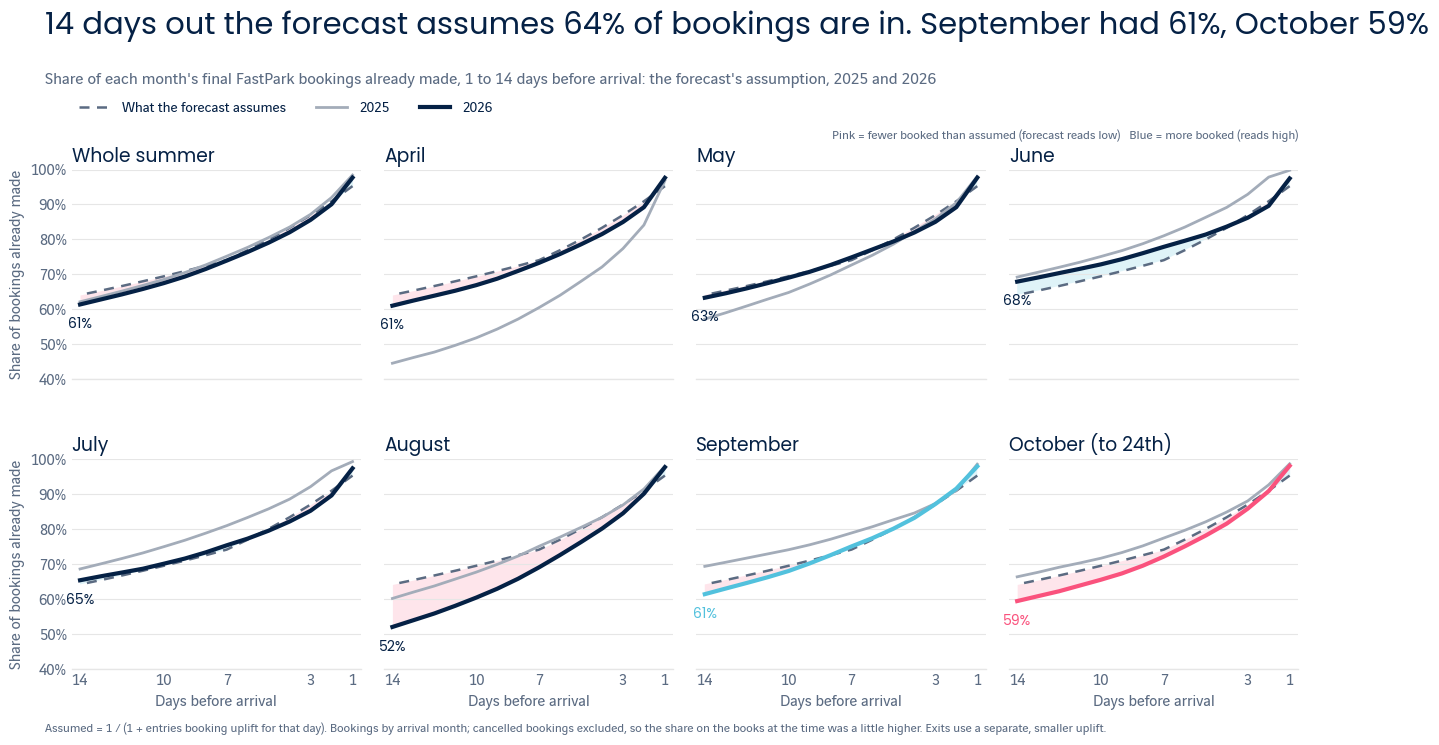

In [46]:
# -----------------------------------------------------------------------------
# Visual 5: bookings already on the books 1 to 14 days before arrival
#   assumed = what the fixed booking uplift implies (entries list, 1 day out = +5% ... 14 days out = +56%)
#   2025 / 2026 = share of the month's final bookings made at least that many days before arrival
# -----------------------------------------------------------------------------
ENTRY_UPLIFT = [5, 10, 15, 20, 25, 30, 35, 38, 41, 44, 47, 50, 53, 56]     # % by days out, 1..14
D14 = np.arange(1, 15)
assumed = pd.Series([1 / (1 + u / 100) for u in ENTRY_UPLIFT], index=D14)

curves["Summer"] = {y: booked_by(bk[bk["year"] == y]) for y in (2025, 2026)}
def curve(y, key):
    return curves["Summer"][y] if key == "Summer" else curves[(y, key)]

# table: month x days out, assumed / 2025 / 2026
tbl = {}
for key in ["Summer"] + MONTHS:
    for d in D14:
        tbl[(MONTH_LONG.get(key, "Summer"), d)] = {"Assumed": assumed[d], "2025": curve(2025, key)[d],
                                                    "2026": curve(2026, key)[d]}
booked_table = pd.DataFrame(tbl).T.rename_axis(["month", "days out"])
print("Share of final bookings already made, by days before arrival (%):")
display((booked_table * 100).round(0).unstack("days out").swaplevel(axis=1).sort_index(axis=1, level=0)
        .reindex(columns=["Assumed", "2025", "2026"], level=1)
        .reindex(["Summer"] + [MONTH_LONG[m] for m in MONTHS]))

# chart
panels = ["Summer"] + MONTHS
fig, axes = plt.subplots(2, 4, figsize=(13.33, 7.8), sharey=True, sharex=True)
fig.subplots_adjust(top=0.75, bottom=0.11, left=0.06, right=0.98, hspace=0.38, wspace=0.08)
for ax, key in zip(axes.flat, panels):
    a, ly, ty = assumed.values, curve(2025, key)[D14].values, curve(2026, key)[D14].values
    colour = FOCUS_COLOUR.get(key, DARK_BLUE)
    ax.fill_between(D14, a, ty, where=ty < a, color=PINK, alpha=0.15, lw=0, interpolate=True)
    ax.fill_between(D14, a, ty, where=ty >= a, color=LIGHT_BLUE, alpha=0.18, lw=0, interpolate=True)
    ax.plot(D14, a, color=MUTED, lw=1.8, ls=(0, (4, 3)))
    ax.plot(D14, ly, color=LY_GREY, lw=2)
    ax.plot(D14, ty, color=colour, lw=3)
    ax.text(14, ty[-1] - 0.035, f"{ty[-1]:.0%}", ha="center", va="top", fontsize=10, color=colour, fontfamily=HEAD_FONT)
    name = "Whole summer" if key == "Summer" else MONTH_LONG[key] + (" (to 24th)" if key == 10 else "")
    ax.set_title(name, loc="left", fontsize=13.5, fontfamily=HEAD_FONT, color=DARK_BLUE)
    ax.set_xlim(14.4, 0.6)
    ax.set_xticks([14, 10, 7, 3, 1])
    ax.set_ylim(0.4, 1.0)
    ax.yaxis.set_major_formatter(pct)
for ax in axes[1]:
    ax.set_xlabel("Days before arrival")
for ax in axes[:, 0]:
    ax.set_ylabel("Share of bookings already made")

# key across the top
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], color=MUTED, lw=1.8, ls=(0, (4, 3))), Line2D([], [], color=LY_GREY, lw=2),
            Line2D([], [], color=DARK_BLUE, lw=3)],
           ["What the forecast assumes", "2025", "2026"],
           loc="upper left", bbox_to_anchor=(0.055, 0.855), ncol=4, frameon=False, fontsize=11)
fig.text(0.98, 0.79, "Pink = fewer booked than assumed (forecast reads low)   Blue = more booked (reads high)",
         ha="right", fontsize=9.5, color=MUTED)

s14 = {m: curve(2026, m)[14] for m in FOCUS}
headline(fig, f"14 days out the forecast assumes {assumed[14]:.0%} of bookings are in. "
              f"September had {s14[9]:.0%}, October {s14[10]:.0%}",
         "Share of each month's final FastPark bookings already made, 1 to 14 days before arrival: "
         "the forecast's assumption, 2025 and 2026")
footnote(fig, "Assumed = 1 / (1 + entries booking uplift for that day). Bookings by arrival month; cancelled bookings "
              "excluded, so the share on the books at the time was a little higher. Exits use a separate, smaller uplift.")
plt.show()

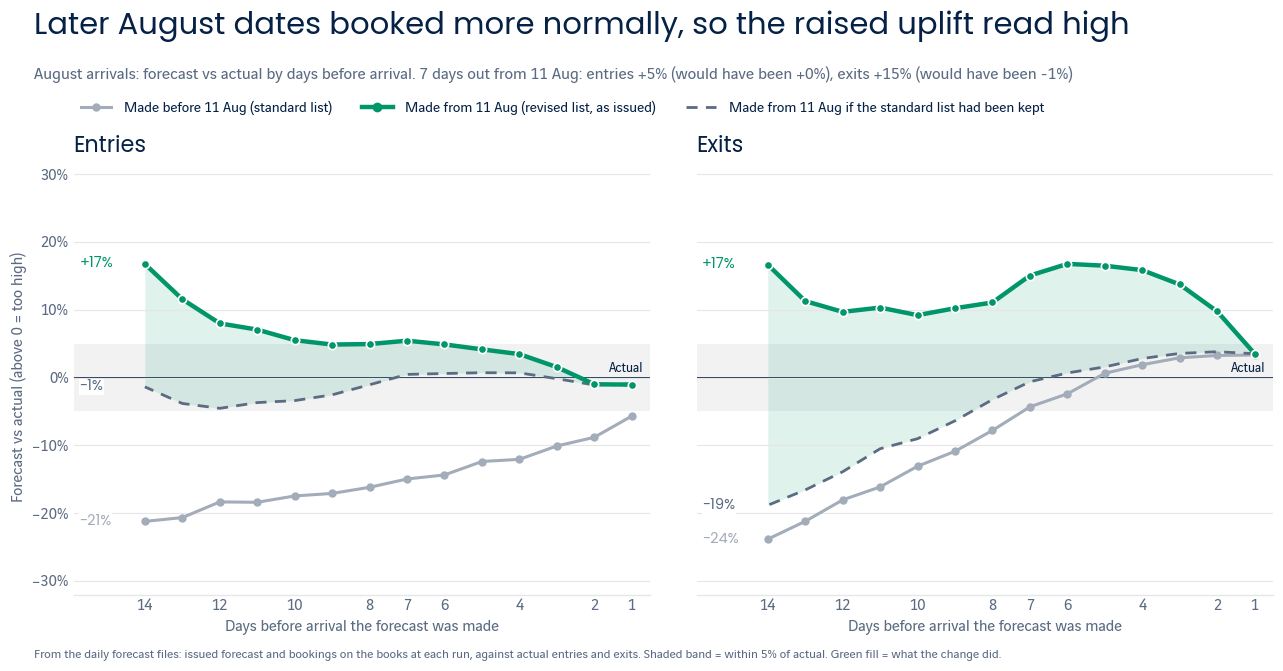

In [47]:
# -----------------------------------------------------------------------------
# Visual 6: what the 11 August change to the daily booking uplift did (August arrivals only)
#   Forecasts made 1-14 days before each August date, from the forecast files:
#   - made before 11 Aug: standard list, as issued
#   - made from 11 Aug: revised list, as issued
#   - made from 11 Aug: if the standard list had been kept = bookings on the books x standard uplift
# -----------------------------------------------------------------------------
STD_UPLIFT = {"entries": [5, 10, 15, 20, 25, 30, 35, 38, 41, 44, 47, 50, 53, 56],
              "exits":   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]}
AUG_CHANGE = pd.Timestamp("2026-08-11")
D14 = np.arange(1, 15)

aug = forecasts.dropna(subset=["Date"]).assign(d=lambda x: (x["Date"] - x["run"]).dt.days)
aug = aug[aug["d"].between(1, 14) & (aug["Date"].dt.month == 8) & (aug["Date"].dt.year == 2026)].merge(actuals.reset_index(), on="Date")
aug["after"] = aug["run"] >= AUG_CHANGE
for flow in ["entries", "exits"]:
    aug[f"std_{flow}"] = aug[f"otb_{flow}"] * (1 + aug["d"].map(dict(zip(D14, STD_UPLIFT[flow]))) / 100)

def pct_vs_actual(df, col, flow):
    s = df.groupby("d")[[col, f"act_{flow}"]].sum()
    return (s[col] / s[f"act_{flow}"] - 1).reindex(D14)

fig, axes = plt.subplots(1, 2, figsize=(13.33, 7.0), sharey=True)
fig.subplots_adjust(top=0.74, bottom=0.12, left=0.07, right=0.97, wspace=0.08)
series = {}
for ax, flow in zip(axes, ["entries", "exits"]):
    before = pct_vs_actual(aug[~aug["after"]], f"fc_{flow}", flow)
    after = pct_vs_actual(aug[aug["after"]], f"fc_{flow}", flow)
    kept = pct_vs_actual(aug[aug["after"]], f"std_{flow}", flow)
    series[flow] = (before, after, kept)
    ax.axhspan(-0.05, 0.05, color=GREY, alpha=0.5, lw=0, zorder=0)
    ax.axhline(0, color=DARK_BLUE, lw=1.2, zorder=1)
    ax.fill_between(D14, kept.values, after.values, color=GREEN, alpha=0.12, lw=0, zorder=1)
    ax.plot(D14, before.values, color=LY_GREY, lw=2.2, marker="o", ms=5, zorder=2)
    ax.plot(D14, kept.values, color=MUTED, lw=2, ls=(0, (4, 3)), zorder=3)
    ax.plot(D14, after.values, color=GREEN, lw=3.2, marker="o", ms=6, mec="white", mew=1.2, zorder=4)
    for s, c in [(before, LY_GREY), (kept, MUTED), (after, GREEN)]:
        ax.text(15.75, s[14], f"{s[14]:+.0%}", ha="left", va="center", fontsize=10.5, color=c,
                fontfamily=HEAD_FONT, bbox=dict(fc="white", ec="none", pad=0.5))
    ax.text(0.7, 0.003, "Actual", fontsize=10, color=DARK_BLUE, va="bottom", ha="right")
    ax.set_title(flow.capitalize(), loc="left", fontsize=16, fontfamily=HEAD_FONT, color=DARK_BLUE)
    ax.set_xlim(15.9, 0.5)
    ax.set_xticks([14, 12, 10, 8, 7, 6, 4, 2, 1])
    ax.set_xlabel("Days before arrival the forecast was made")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Forecast vs actual (above 0 = too high)")
axes[0].set_ylim(-0.32, 0.32)

from matplotlib.lines import Line2D
fig.legend([Line2D([], [], color=LY_GREY, lw=2.2, marker="o", ms=5),
            Line2D([], [], color=GREEN, lw=3.2, marker="o", ms=6),
            Line2D([], [], color=MUTED, lw=2, ls=(0, (4, 3)))],
           ["Made before 11 Aug (standard list)", "Made from 11 Aug (revised list, as issued)",
            "Made from 11 Aug if the standard list had been kept"],
           loc="upper left", bbox_to_anchor=(0.065, 0.845), ncol=3, frameon=False, fontsize=11)

ea, ek = series["entries"][1][7], series["entries"][2][7]
xa, xk = series["exits"][1][7], series["exits"][2][7]
headline(fig, "Later August dates booked more normally, so the raised uplift read high",
         f"August arrivals: forecast vs actual by days before arrival. 7 days out from 11 Aug: entries {ea:+.0%} "
         f"(would have been {ek:+.0%}), exits {xa:+.0%} (would have been {xk:+.0%})")
footnote(fig, "From the daily forecast files: issued forecast and bookings on the books at each run, against actual entries and exits. "
              "Shaded band = within 5% of actual. Green fill = what the change did.")
plt.show()

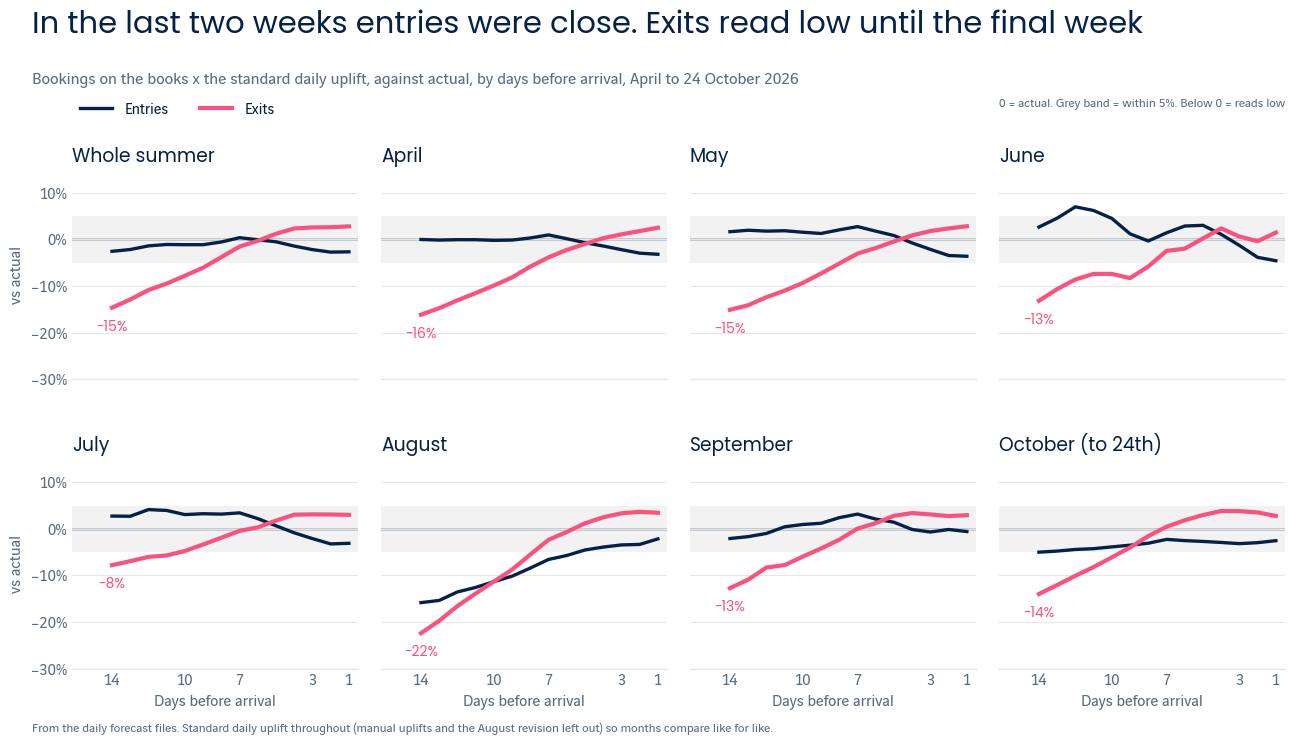

14 / 7 / 1 days out, standard uplift vs actual (%):


entries           exits          
               14   7    1     14   7    1 
Summer       -3.0  0.0 -3.0 -15.0 -2.0  3.0
April        -0.0  1.0 -3.0 -16.0 -4.0  3.0
May           2.0  3.0 -4.0 -15.0 -3.0  3.0
June          3.0  1.0 -5.0 -13.0 -2.0  1.0
July          3.0  3.0 -3.0  -8.0 -0.0  3.0
August      -16.0 -7.0 -2.0 -22.0 -2.0  3.0
September    -2.0  3.0 -1.0 -13.0  0.0  3.0
October      -5.0 -2.0 -3.0 -14.0  0.0  3.0

In [48]:
# -----------------------------------------------------------------------------
# Visual 7: entries vs exits in the last 2 weeks - how the standard daily uplift read against actual
#   From the forecast files: bookings on the books at each run x the standard daily uplift, vs actual.
#   Uses the standard list throughout (no manual uplifts, no August revision) so months compare like for like.
# -----------------------------------------------------------------------------
STD_UPLIFT = {"entries": [5, 10, 15, 20, 25, 30, 35, 38, 41, 44, 47, 50, 53, 56],
              "exits":   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]}
D14 = np.arange(1, 15)
w = forecasts.dropna(subset=["Date"]).assign(d=lambda x: (x["Date"] - x["run"]).dt.days)
w = w[w["d"].between(1, 14) & w["Date"].between(R1_START, R1_END)].merge(actuals.reset_index(), on="Date")
w["m"] = w["Date"].dt.month
for flow in ["entries", "exits"]:
    w[f"std_{flow}"] = w[f"otb_{flow}"] * (1 + w["d"].map(dict(zip(D14, STD_UPLIFT[flow]))) / 100)

def reads(df, flow):
    s = df.groupby("d")[[f"std_{flow}", f"act_{flow}"]].sum()
    return (s[f"std_{flow}"] / s[f"act_{flow}"] - 1).reindex(D14)

panels = ["Summer"] + R1_MONTHS
v7 = {}
fig, axes = plt.subplots(2, 4, figsize=(13.33, 7.8), sharey=True, sharex=True)
fig.subplots_adjust(top=0.75, bottom=0.11, left=0.07, right=0.98, hspace=0.38, wspace=0.08)
for ax, key in zip(axes.flat, panels):
    d = w if key == "Summer" else w[w["m"] == key]
    e, x = reads(d, "entries"), reads(d, "exits")
    v7[key] = {"entries": e, "exits": x}
    ax.axhspan(-0.05, 0.05, color=GREY, alpha=0.5, lw=0, zorder=0)
    ax.axhline(0, color=DARK_BLUE, lw=1, zorder=1)
    ax.plot(D14, e.values, color=DARK_BLUE, lw=2.4, zorder=3)
    ax.plot(D14, x.values, color=PINK, lw=3, zorder=4)
    ax.text(14, x[14] - 0.025, f"{x[14]:+.0%}", ha="center", va="top", fontsize=10, color=PINK, fontfamily=HEAD_FONT)
    name = "Whole summer" if key == "Summer" else MONTH_LONG[key] + (" (to 24th)" if key == 10 else "")
    ax.set_title(name, loc="left", fontsize=13.5, fontfamily=HEAD_FONT, color=DARK_BLUE)
    ax.set_xlim(16.2, 0.5)
    ax.set_xticks([14, 10, 7, 3, 1])
    ax.set_ylim(-0.3, 0.15)
    ax.yaxis.set_major_formatter(pct)
for ax in axes[1]:
    ax.set_xlabel("Days before arrival")
for ax in axes[:, 0]:
    ax.set_ylabel("vs actual")

from matplotlib.lines import Line2D
fig.legend([Line2D([], [], color=DARK_BLUE, lw=2.4), Line2D([], [], color=PINK, lw=3)],
           ["Entries", "Exits"], loc="upper left", bbox_to_anchor=(0.065, 0.855), ncol=2, frameon=False, fontsize=11.5)
fig.text(0.98, 0.83, "0 = actual. Grey band = within 5%. Below 0 = reads low", ha="right", fontsize=9.5, color=MUTED)

headline(fig, "In the last two weeks entries were close. Exits read low until the final week",
         "Bookings on the books x the standard daily uplift, against actual, by days before arrival, April to 24 October 2026")
footnote(fig, "From the daily forecast files. Standard daily uplift throughout (manual uplifts and the August revision left out) "
              "so months compare like for like.")
plt.show()
print("14 / 7 / 1 days out, standard uplift vs actual (%):")
display(pd.DataFrame({(f, d): {MONTH_LONG.get(k, k): v7[k][f][d] * 100 for k in v7} for f in ["entries", "exits"] for d in [14, 7, 1]}).round(0))

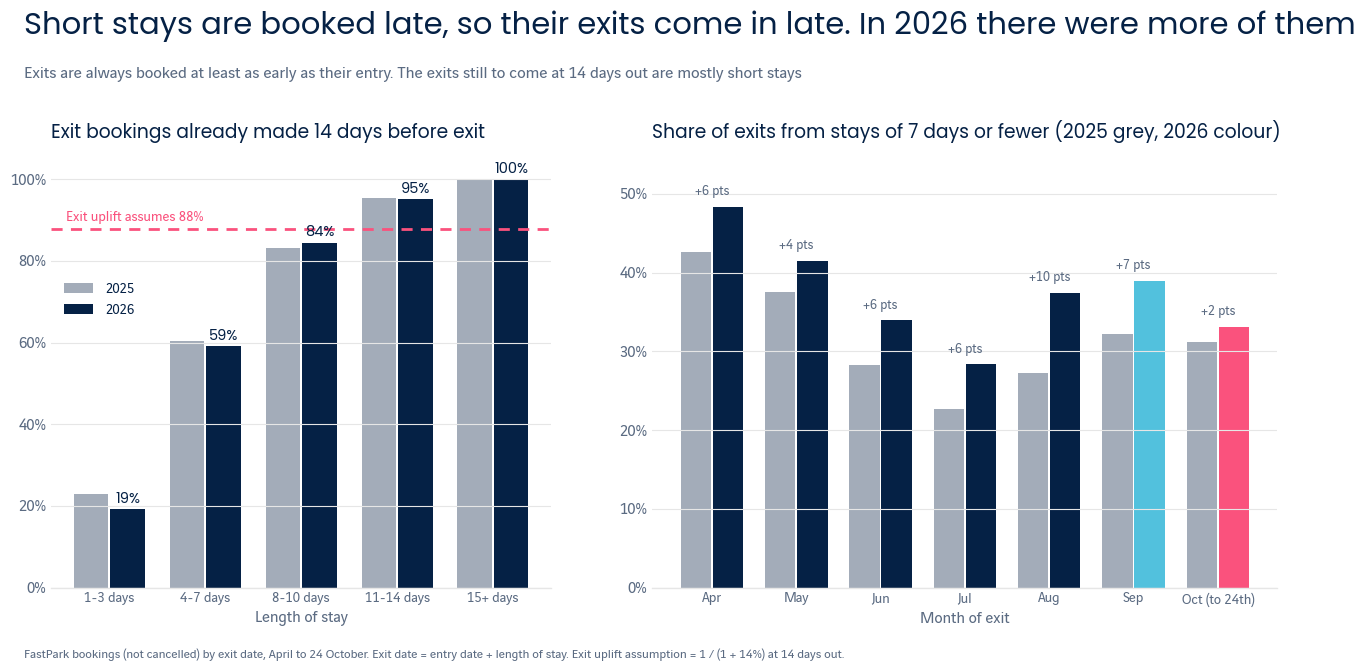

Exits already booked 14 days before exit, by month:


year,2025,2026
m,,
April,62.0,72.0
May,71.0,74.0
June,82.0,79.0
July,86.0,80.0
August,79.0,70.0
September,81.0,77.0
October,80.0,76.0


In [49]:
# -----------------------------------------------------------------------------
# Visual 8: exits by stay length - why exits still had bookings to come 14 days out
#   An exit booking is always at least as old as its entry booking (exit = entry + stay length),
#   so exits fill earlier than entries. What is left to come at 14 days out is mostly short stays,
#   booked shortly before they travel. The standard exit uplift assumes 88% are in at 14 days.
# -----------------------------------------------------------------------------
xb = bookings.copy()
xb["createdAt"], xb["entryDate"] = pd.to_datetime(xb["createdAt"]), pd.to_datetime(xb["entryDate"])
xb["entry_d"] = xb["entryDate"].dt.normalize()
xb["exit_d"] = xb["entry_d"] + pd.to_timedelta(xb["duration"], unit="D")
xb["lead_x"] = (xb["exit_d"] - xb["createdAt"].dt.normalize()).dt.days
xb["lead_e"] = (xb["entry_d"] - xb["createdAt"].dt.normalize()).dt.days
xb["year"], xb["m"] = xb["exit_d"].dt.year, month_key(xb["exit_d"])
xb = xb[xb["m"].isin(R1_MONTHS) & xb["year"].isin([2025, 2026]) & (xb["lead_e"] >= 0)]
STAY_BANDS = ["1-3 days", "4-7 days", "8-10 days", "11-14 days", "15+ days"]
xb["band"] = pd.cut(xb["duration"], [0, 3, 7, 10, 14, 10_000], labels=STAY_BANDS)
EXIT_ASSUMED_14 = 1 / 1.14

in14_band = xb.groupby(["band", "year"], observed=True).apply(lambda d: (d["lead_x"] >= 14).mean()).unstack("year")
short = xb.assign(s=xb["duration"] <= 7).groupby(["m", "year"])["s"].mean().unstack("year")
in14_m = xb.groupby(["m", "year"]).apply(lambda d: (d["lead_x"] >= 14).mean()).unstack("year")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.33, 7.0), gridspec_kw=dict(width_ratios=[1, 1.25]))
fig.subplots_adjust(top=0.76, bottom=0.13, left=0.06, right=0.98, wspace=0.18)

# left: share of exit bookings already in 14 days out, by stay length
xs = np.arange(len(STAY_BANDS))
for off, y, col in [(-0.19, 2025, LY_GREY), (0.19, 2026, DARK_BLUE)]:
    vals = in14_band[y].reindex(STAY_BANDS).values
    a1.bar(xs + off, vals, width=0.36, color=col, label=str(y))
    if y == 2026:
        for xi, v in zip(xs + off, vals):
            a1.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=10.5, color=DARK_BLUE, fontfamily=HEAD_FONT)
a1.axhline(EXIT_ASSUMED_14, color=PINK, lw=2, ls=(0, (4, 3)))
a1.text(-0.45, EXIT_ASSUMED_14 + 0.02, f"Exit uplift assumes {EXIT_ASSUMED_14:.0%}", color=PINK, fontsize=10.5)
a1.set_xticks(xs, STAY_BANDS, fontsize=10.5)
a1.set_ylim(0, 1.08)
a1.yaxis.set_major_formatter(pct)
a1.set_title("Exit bookings already made 14 days before exit", loc="left", fontsize=13.5,
             fontfamily=HEAD_FONT, color=DARK_BLUE)
a1.set_xlabel("Length of stay")
a1.legend(loc="upper left", bbox_to_anchor=(0, 0.72), frameon=False, fontsize=10.5)

# right: share of exits from stays of 7 days or fewer, by month
xm = np.arange(len(R1_MONTHS))
for off, y, col in [(-0.19, 2025, LY_GREY), (0.19, 2026, DARK_BLUE)]:
    vals = short[y].reindex(R1_MONTHS).values
    a2.bar(xm + off, vals, width=0.36, color=[FOCUS_COLOUR.get(m, col) if y == 2026 else col for m in R1_MONTHS])
for xi, m in zip(xm, R1_MONTHS):
    a2.text(xi, max(short.loc[m]) + 0.015, f"{(short.loc[m, 2026] - short.loc[m, 2025]) * 100:+.0f} pts",
            ha="center", fontsize=10, color=MUTED)
a2.set_xticks(xm, [MONTH_LONG[m][:3] + (" (to 24th)" if m == 10 else "") for m in R1_MONTHS], fontsize=10.5)
a2.set_ylim(0, 0.56)
a2.yaxis.set_major_formatter(pct)
a2.set_title("Share of exits from stays of 7 days or fewer (2025 grey, 2026 colour)", loc="left", fontsize=13.5,
             fontfamily=HEAD_FONT, color=DARK_BLUE)
a2.set_xlabel("Month of exit")

headline(fig, "Short stays are booked late, so their exits come in late. In 2026 there were more of them",
         "Exits are always booked at least as early as their entry. The exits still to come at 14 days out are mostly short stays")
footnote(fig, "FastPark bookings (not cancelled) by exit date, April to 24 October. Exit date = entry date + length of stay. "
              "Exit uplift assumption = 1 / (1 + 14%) at 14 days out.")
plt.show()
print("Exits already booked 14 days before exit, by month:")
display((in14_m * 100).round(0).rename(index=MONTH_LONG))